# BBC News word-level pipeline, first version

This is the Google Colab notebook as it was run for the paper's word-level experiments. API keys, Hugging Face
tokens and Google Sheet / Drive IDs are replaced by placeholders (`os.environ["GOOGLE_API_KEY"]`, `<HF_TOKEN>`,
`<GOOGLE_SHEET_ID>`); one screenshot was removed. The notebook reads and writes Google Drive files and Google
Sheets through `gspread`; the workbooks in `data/` are exports of those sheets (`data/BBC_news_latest.xlsx`). To run it outside
Colab, replace that I/O with reads of the exported workbooks. The reconstructions were decoded with
gemini-2.0-flash, which has since been retired.

Naming map (notebook -> paper):

| Notebook | Paper |
|---|---|
| Benchmark Way, fixed-step deletion (`benchmark` sheet) | Step |
| Way 1, word-length deletion (`adaptive_..._length_deletion` sheet) | WordLen |
| Way 2, word frequency with 3 / 6 classes (`wf_3classes` / `wf_6classes`) | WordFreq-3 / WordFreq-6 |
| Way 3, optimization for word frequency (`wf_optimal`) | LP |
| "Without Prepolish" (`wf_optimal_without_prepolish`) | an LP variant calibrated without the second decoder pass; not in the paper's tables |
| "LLM for restoration", `restored_*` columns | first decoder pass |
| "LLM for polishment", `polished_*` columns | second decoder pass; its outputs are the reconstructions the paper scores ("Without Polished" = a single pass) |
| Way 4, SFT | QLoRA fine-tuned Llama-3.2-3B-Instruct decoder |
| Way 4.1, base model used by SFT | the same model without fine-tuning (zero-shot) |

This is the earlier of the two BBC News notebooks. Everything before the heading *BBC News Dataset Summary* is unrelated early experimentation (other corpora, punctuation restoration, distortion and step-size trials) and is not part of the paper. From that heading on it holds the first versions of the word-level strategies and the derivation of the LP allocation. `harness/wf3_deletion.py` is the WordFreq-3 deletion rule of this notebook, and `analysis/run_r005_wordfreq3.py` reads its restoration prompt from it. `bbc_word_level_pipeline_v2.ipynb` is the version behind the published BBC tables.


#  Datasets Processing

## English News

In [ ]:
from datasets import load_dataset

## https://huggingface.co/datasets/vblagoje/cc_news

ds = load_dataset("vblagoje/cc_news")


In [ ]:
import pandas as pd
ds

In [ ]:
df = ds["train"].to_pandas()

df = df.drop_duplicates(subset=["text","description"])

In [ ]:

df["text_length"] = df["text"].apply(lambda x: len(str(x).replace(" ", "").replace("\n", "").replace("\r", "").replace("\t", "")))
df

In [ ]:
import re

# 🚫 1. 要排除的垃圾短语（针对 text 列）
ban_phrases = [
    "Send to Email Address",
    "Your Name",
    "Your Email Address",
    "Post was not sent - check your email addresses!",
    "Email check failed, please try again",
    "Sorry, your blog cannot share posts by email."
]

# 组合为正则表达式（使用 | 表示“或”）
ban_pattern = "|".join([re.escape(p) for p in ban_phrases])

# 🚫 2. 印地语字符范围（针对 title 列）
hindi_pattern = r'[\u0900-\u097F]'

# ✅ 3. 筛选 + 抽样
df_sample = df[
    (df["text_length"] <= 4000)
    & (df["text_length"] > 100)
    & (df["description"].apply(lambda x: len(re.sub(r"\s+", "", str(x)))) >= 60)
    & (~df["title"].astype(str).str.contains(hindi_pattern, regex=True))               # ❌ title 不含印地语
    & (~df["text"].astype(str).str.contains(ban_pattern, regex=True, case=False))      # ❌ text 不含垃圾短语
].sample(n=5000, random_state=42)


In [ ]:
df_sample["text_length"].value_counts()

In [ ]:
!pip install --quiet tiktoken
import tiktoken

# 初始化 tokenizer
enc = tiktoken.get_encoding("cl100k_base")

# 定义统计函数
def count_tokens(text: str) -> int:
    """统计文本的 token 数"""
    return len(enc.encode(str(text)))

# 在 df_sample 里添加 token 数列
df_sample["token_count"] = df_sample["text"].apply(count_tokens)

# 查看结果
print(df_sample[["text", "token_count"]].head())
print(f"📊 平均 token 数: {df_sample['token_count'].mean():.2f}")


In [ ]:
df_sample

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sample_5000")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sample_5000", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df_sample)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## ENGLISH BOOK

In [ ]:

import pandas as pd
from datasets import load_dataset


eb = load_dataset("IsmaelMousa/books")


In [ ]:
eb

In [ ]:
eb2 = eb["validation"].to_pandas()

In [ ]:
eb2.rename(columns={"EN": "text"}, inplace=True)

In [ ]:
eb2["text_length"] = eb2["text"].apply(lambda x: len(str(x).replace(" ", "").replace("\n", "").replace("\r", "").replace("\t", "")))
eb2

In [ ]:
import re
import tiktoken

enc = tiktoken.get_encoding("cl100k_base")

def count_tokens(text: str) -> int:
    return len(enc.encode(str(text)))

def hard_split_by_tokens(text: str, hard_max: int):
    """当单个句子超过硬上限时，按 token 进行强制切片"""
    toks = enc.encode(str(text))
    pieces = []
    i = 0
    while i < len(toks):
        j = min(i + hard_max, len(toks))
        pieces.append(enc.decode(toks[i:j]))
        i = j
    return pieces

def split_by_token_semantic(text, target_tokens=800, tolerance=0.15):
    """
    智能分块（带硬上限）：
    1) 优先段落边界  2) 其次句子边界  3) 句内 token 强切兜底
    """
    hard_max = int(target_tokens * (1 + tolerance))
    min_tokens = int(target_tokens * (1 - tolerance))

    paragraphs = re.split(r'\n{2,}', str(text).strip())
    chunks, current = [], ""

    def flush_current():
        nonlocal current
        if current.strip():
            chunks.append(current.strip())
            current = ""

    for para in paragraphs:
        # 先按“句子终止符”切；若文本无标点，可考虑再按逗号/分号“次级切”
        sentences = re.split(r'(?<=[。！？!?\.])\s*', para.strip())
        sentences = [s for s in sentences if s.strip()]

        for sent in sentences:
            sent_tok = count_tokens(sent)
            curr_tok = count_tokens(current)

            # 句子本身超过硬上限：先句内硬切，再逐片装配
            if sent_tok > hard_max:
                # 先把已有 current 刷掉（避免和硬切片黏在一起过界）
                if curr_tok >= min_tokens:
                    flush_current()
                pieces = hard_split_by_tokens(sent, hard_max)
                for piece in pieces:
                    # piece 至多 hard_max，此处直接作为独立块（或与 current 合并）
                    if count_tokens(current) + count_tokens(piece) <= hard_max:
                        current += piece + " "
                    else:
                        flush_current()
                        current = piece + " "
                continue

            # 句子不超过硬上限：尝试合并到 current
            if curr_tok + sent_tok <= hard_max:
                current += sent + " "
            elif curr_tok < min_tokens:
                # current 太短，尽量再吞一个句子（即便越过 hard_max 也不允许 → 所以 flush 再放）
                flush_current()
                # 如果单句 <= hard_max，直接作为新 current
                current = sent + " "
            else:
                # current 已够：先收块，再开新块
                flush_current()
                current = sent + " "

        # 段落结束：以自然边界收块（若 current 已够长）
        if count_tokens(current) >= min_tokens:
            flush_current()

    # 收尾
    if current.strip():
        # 如果尾块过小，尝试与前块合并，仍不超 hard_max
        if chunks and count_tokens(chunks[-1]) + count_tokens(current) <= hard_max:
            chunks[-1] = (chunks[-1] + " " + current.strip()).strip()
        else:
            chunks.append(current.strip())

    # 若最后块仍过短，合并到前一块（不会超过 hard_max）
    if len(chunks) > 1 and count_tokens(chunks[-1]) < max(1, int(min_tokens * 0.5)):
        if count_tokens(chunks[-2]) + count_tokens(chunks[-1]) <= hard_max:
            chunks[-2] = (chunks[-2] + " " + chunks[-1]).strip()
            chunks.pop()

    return chunks

# ============================================================
# 3️⃣ 主函数：从 DataFrame 生成 chunk DataFrame
# ============================================================
def make_chunks(df, target_tokens=800):
    """
    输入 DataFrame（含 title, author, text）
    输出分块 DataFrame（含 chunk_id, token_count）
    """
    records = []
    for _, row in df.iterrows():
        title = row.get("title", "")
        author = row.get("author", "")
        text = row.get("text", "")

        if not isinstance(text, str) or not text.strip():
            continue

        chunks = split_by_token_semantic(text, target_tokens)
        for i, chunk in enumerate(chunks):
            token_count = count_tokens(chunk)
            records.append({
                "title": title,
                "author": author,
                "chunk_id": i + 1,
                "text_chunk": chunk,
                "token_count": token_count
            })

    return pd.DataFrame(records)

try:
    df_chunks = make_chunks(eb2, target_tokens=800)

    # ============================================================
    # 5️⃣ 输出结果
    # ============================================================
    print("✅ Chunking 完成！")
    print(df_chunks.head(3))
    print(f"📊 共生成 {len(df_chunks)} 条 chunk。")
    print(f"📈 平均 token 数: {df_chunks['token_count'].mean():.2f}")
    print(f"📉 最小 token 数: {df_chunks['token_count'].min()}")
    print(f"📈 最大 token 数: {df_chunks['token_count'].max()}")

except NameError:
    print("❌ 请先定义 eb2，例如：eb2 = pd.read_excel('your_file.xlsx') 或从 Google Sheet 读取。")


In [ ]:
df_chunks

In [ ]:
df_chunks["text_chunk_length"] = df_chunks["text_chunk"].apply(lambda x: len(str(x).replace(" ", "").replace("\n", "").replace("\r", "").replace("\t", "")))
df_chunks

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_novels_chunk_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_novels_chunk_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df_chunks)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


# Punctutation Restoration

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_novels_chunk_800"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
import re
import pandas as pd

# ============================================================
# 🧩 定义中英文常见标点符号集合（含中英文符号）
# ============================================================
punct_pattern = r"[，。！？、；：“”‘’（）【】《》〈〉—\-…,.!?;:'\"()\[\]{}]"

# ============================================================
# 🧠 统计函数：返回 (数量, 标点列表字符串)
# ============================================================
def extract_punct_info(text):
    text = str(text)
    puncts = re.findall(punct_pattern, text)
    unique_puncts = sorted(set(puncts))  # 去重并排序
    punct_count = len(unique_puncts)
    punct_list = "".join(unique_puncts)  # 拼成字符串方便存表
    return pd.Series([punct_count, punct_list])

# ============================================================
# 📊 应用到 DataFrame
# ============================================================
# 假设文本列为 'text' 或 'text_chunk'
target_col = "text"
if "text_chunk" in df.columns:
    target_col = "text_chunk"

df[["unique_punct_count", "unique_punct_list"]] = df[target_col].apply(extract_punct_info)

# ============================================================
# 🔍 查看结果
# ============================================================
print(df[[target_col, "unique_punct_count", "unique_punct_list"]].head(10))
print(f"📊 平均不同标点种类数：{df['unique_punct_count'].mean():.2f}")


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_novels_chunk_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_novels_chunk_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## LLM processing

### without punctutation hints

In [ ]:
import os
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet google-generativeai pandas scikit-learn tqdm

# ============================================================
# 📗 导入库
# ============================================================
from google import genai
import pandas as pd
import re
from tqdm import tqdm
from sklearn.metrics import precision_recall_fscore_support
import re
from difflib import SequenceMatcher



client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

# ============================================================
# 2️⃣ 标点集合 + 辅助函数
# ============================================================
PUNCT_RE = r"[，。！？、；：“”‘’（）【】《》〈〉—\-…,.!?;:'\"()\[\]{}]"

def strip_punct(text):
    """去除所有标点符号"""
    return re.sub(PUNCT_RE, "", str(text))

def extract_puncts(text):
    """提取标点符号序列"""
    return re.findall(PUNCT_RE, str(text))

def punct_positions(text):
    """返回 (字符间隙位置, 标点) 列表"""
    s = str(text)
    result, gap = [], 0
    for ch in s:
        if re.match(PUNCT_RE, ch):
            result.append((gap, ch))
        else:
            gap += 1
    return result

def normalize_text_for_punct(s: str):
    """去除空行、换行和多余空格"""
    if not isinstance(s, str):
        return ""
    s = re.sub(r"[\r\n]+", "", s)  # 去除换行符
    s = re.sub(r"\s+", "", s)      # 去除所有空白（空格、制表符等）
    return s.strip()



def text_similarity(a: str, b: str):
    """比较两个文本的整体相似度（包含标点符号，忽略空行/换行）"""
    a_norm, b_norm = normalize_text_for_punct(a), normalize_text_for_punct(b)
    return SequenceMatcher(None, a_norm, b_norm).ratio()

# ============================================================
# 🔹 标点位置准确率
# ============================================================

def punct_position_accuracy(pred: str, gold: str):
    """位置 + 类型双重匹配的准确率（忽略空行和换行）"""
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    pset, gset = set(punct_positions(pred_norm)), set(punct_positions(gold_norm))
    if not gset:
        return 0.0
    return len(pset & gset) / len(gset)

def punct_position_accuracy_fuzzy(pred: str, gold: str, tolerance: int = 1):
    """
    位置 + 类型双重匹配的准确率（带容忍度）
    - 若预测标点位置与真实位置相差 <= tolerance（默认1），且标点类型相同，即认为匹配。
    - 忽略空行与换行符。
    """
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    p_pos = punct_positions(pred_norm)
    g_pos = punct_positions(gold_norm)

    if not g_pos:
        return 0.0

    matched = set()
    for g_idx, g_punct in g_pos:
        for p_idx, p_punct in p_pos:
            # 只要类型相同 且 位置差 ≤ tolerance，就算匹配
            if p_punct == g_punct and abs(p_idx - g_idx) <= tolerance:
                matched.add((g_idx, g_punct))
                break

    return len(matched) / len(g_pos)


# ============================================================
# 🔹 标点类型 F1
# ============================================================
def punct_f1_type_only(pred: str, gold: str):
    """仅按标点类型计算 Precision / Recall / F1（忽略空行和换行）"""
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    y_true, y_pred = extract_puncts(gold_norm), extract_puncts(pred_norm)
    n = min(len(y_true), len(y_pred))
    if n == 0:
        return 0, 0, 0
    y_true, y_pred = y_true[:n], y_pred[:n]
    labels = sorted(set(y_true + y_pred))
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    return p, r, f1
# ============================================================
# 3️⃣ Prompt 模板
# ============================================================
PUNCT_PROMPT = """
You are an expert in English punctuation restoration.
I will give you a segment of text with all punctuation removed.
Your task is to **only restore the English punctuation**, ensuring that:
- You do not change, add or delete any English letters, numbers, or words;
- You only insert appropriate English punctuation marks (e.g., , . ! ? ; : ' " - ... ) where they naturally belong;
- Do NOT output any explanations, markdown, or commentary;
- Output only the restored text.

Original Text:
{input_text}

Output:
""".strip()


# ============================================================
# ✅ 单条标点恢复测试（新版 genai.Client 调用）
# ============================================================
test_text = "I like this Sunny day"   # ← 这里替换为你要测试的无标点文本

prompt = PUNCT_PROMPT.format(input_text=test_text)

response = client.models.generate_content(
    model="gemini-2.0-flash",
    contents=prompt,
    config={
        "temperature": 0.1,
        "top_p": 0.9,
        "max_output_tokens": 1000,
    },
)

# 提取生成结果
restored = (response.text or "").strip()

print("🧩 Input）:", test_text)
print("🔸 Output:", restored)

In [ ]:

# ============================================================
# 4️⃣ 准备数据
# ============================================================
# 假设 df 为你原本的 dataframe，包含 text_chunk 列
df_eval = df[:100].copy()
df_eval["gold_text"] = df_eval["text_chunk"]
df_eval["no_punct_text"] = df_eval["gold_text"].apply(strip_punct)
print(f"✅ 已准备 {len(df_eval)} 条样本用于标点恢复")

# ============================================================
# 5️⃣ 调用 Gemini 批量恢复标点（边生成边输出）
# =====a======================================================
preds = []

print("\n================== 开始标点恢复任务 ==================\n")
for i, text in enumerate(tqdm(df_eval["no_punct_text"], desc="Restoring punctuation", ncols=90)):
    try:
        prompt = PUNCT_PROMPT.format(input_text=text)
        response = client.models.generate_content(
        model="gemini-2.0-flash",
        contents=prompt,
        config={
          "temperature": 0.1,
          "top_p": 0.9,
          "max_output_tokens": 1000,
      },
  )

  # 提取生成结果
        restored = (response.text or "").strip()
        preds.append(restored)

        # ✅ 实时打印每条输出
        print(f"\n🧩 Chunk {i+1}/{len(df_eval)}")
        print(f"🔹 无标点输入: {text[:200]}")  # 限制前200字符防爆屏
        print(f"🔸 模型恢复输出: {restored[:200]}")
        print("-" * 60)

    except Exception as e:
        preds.append("")
        print(f"❌ 第 {i+1} 条出错: {e}")

# ✅ 结果写回 DataFrame
df_eval["pred_text"] = preds
print("\n✅ 全部标点恢复任务完成！共生成", len(preds), "条结果。")



In [ ]:
df_eval.head()

In [ ]:
df_eval["similarity"] = df_eval.apply(
    lambda row: text_similarity(row["pred_text"], row["gold_text"]),
    axis=1
)

In [ ]:
df_eval["similarity"].mean()

In [ ]:
df_eval["punct_position_accuracy"] = df_eval.apply(
    lambda row: punct_position_accuracy(row["pred_text"], row["gold_text"]), axis=1
)

df_eval[["punct_precision","punct_recall","punct_f1"]] = df_eval.apply(
    lambda row: pd.Series(punct_f1_type_only(row["pred_text"], row["gold_text"])),
    axis=1
)


In [ ]:
df_eval["punct_position_accuracy_fuzzy"] = df_eval.apply(
    lambda row: punct_position_accuracy_fuzzy(row["pred_text"], row["gold_text"]), axis=1
)

In [ ]:
df_eval["punct_position_accuracy"].mean()

In [ ]:
df_eval["punct_position_accuracy_fuzzy"].mean()

In [ ]:
for i in range(3):  # 看前三个
    gold = df_eval.loc[i, "gold_text"]
    pred = df_eval.loc[i, "pred_text"]
    print(f"\n=== 样本 {i} ===")
    print("gold:", extract_puncts(gold))
    print("pred:", extract_puncts(pred))
    print("整体文本相似度:", text_similarity(pred, gold))
    print("位置准确率:", punct_position_accuracy(pred, gold))
    print("位容错准确率:", punct_position_accuracy_fuzzy(pred, gold))
    print("类型F1:", punct_f1_type_only(pred, gold))


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sample_eval")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sample_eval", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df_eval)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### with punctutation hints



In [ ]:
import os
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet google-generativeai pandas scikit-learn tqdm

# ============================================================
# 📗 导入库
# ============================================================
from google import genai
import pandas as pd
import re
from tqdm import tqdm
from sklearn.metrics import precision_recall_fscore_support
import re
from difflib import SequenceMatcher



client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

# ============================================================
# 2️⃣ 标点集合 + 辅助函数
# ============================================================
PUNCT_RE = r"[，。！？、；：“”‘’（）【】《》〈〉—\-…,.!?;:'\"()\[\]{}]"

def strip_punct(text):
    """去除所有标点符号"""
    return re.sub(PUNCT_RE, "", str(text))

def extract_puncts(text):
    """提取标点符号序列"""
    return re.findall(PUNCT_RE, str(text))

def punct_positions(text):
    """返回 (字符间隙位置, 标点) 列表"""
    s = str(text)
    result, gap = [], 0
    for ch in s:
        if re.match(PUNCT_RE, ch):
            result.append((gap, ch))
        else:
            gap += 1
    return result

def normalize_text_for_punct(s: str):
    """去除空行、换行和多余空格"""
    if not isinstance(s, str):
        return ""
    s = re.sub(r"[\r\n]+", "", s)  # 去除换行符
    s = re.sub(r"\s+", "", s)      # 去除所有空白（空格、制表符等）
    return s.strip()



def text_similarity(a: str, b: str):
    """比较两个文本的整体相似度（包含标点符号，忽略空行/换行）"""
    a_norm, b_norm = normalize_text_for_punct(a), normalize_text_for_punct(b)
    return SequenceMatcher(None, a_norm, b_norm).ratio()

# ============================================================
# 🔹 标点位置准确率
# ============================================================

def punct_position_accuracy(pred: str, gold: str):
    """位置 + 类型双重匹配的准确率（忽略空行和换行）"""
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    pset, gset = set(punct_positions(pred_norm)), set(punct_positions(gold_norm))
    if not gset:
        return 0.0
    return len(pset & gset) / len(gset)

def punct_position_accuracy_fuzzy(pred: str, gold: str, tolerance: int = 1):
    """
    位置 + 类型双重匹配的准确率（带容忍度）
    - 若预测标点位置与真实位置相差 <= tolerance（默认1），且标点类型相同，即认为匹配。
    - 忽略空行与换行符。
    """
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    p_pos = punct_positions(pred_norm)
    g_pos = punct_positions(gold_norm)

    if not g_pos:
        return 0.0

    matched = set()
    for g_idx, g_punct in g_pos:
        for p_idx, p_punct in p_pos:
            # 只要类型相同 且 位置差 ≤ tolerance，就算匹配
            if p_punct == g_punct and abs(p_idx - g_idx) <= tolerance:
                matched.add((g_idx, g_punct))
                break

    return len(matched) / len(g_pos)


# ============================================================
# 🔹 标点类型 F1
# ============================================================
def punct_f1_type_only(pred: str, gold: str):
    """仅按标点类型计算 Precision / Recall / F1（忽略空行和换行）"""
    pred_norm, gold_norm = normalize_text_for_punct(pred), normalize_text_for_punct(gold)
    y_true, y_pred = extract_puncts(gold_norm), extract_puncts(pred_norm)
    n = min(len(y_true), len(y_pred))
    if n == 0:
        return 0, 0, 0
    y_true, y_pred = y_true[:n], y_pred[:n]
    labels = sorted(set(y_true + y_pred))
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    return p, r, f1
# ============================================================
# 3️⃣ Prompt 模板
# ============================================================

PUNCT_PROMPT = """
You are an expert in English punctuation restoration.
I will give you a segment of text with all punctuation removed.
Your task is to **only restore the English punctuation**, ensuring that:
- You do not change, add or delete any English letters, numbers, or words;
- You only insert appropriate English punctuation marks (e.g., , . ! ? ; : ' " - ... ) where they naturally belong;
- Do NOT output any explanations, markdown, or commentary;
- Output only the restored text.

Likely punctuation types: {punct_list}

Original Text:
{input_text}

Output:
""".strip()


# ============================================================
# 4️⃣ 准备数据
# ============================================================
# 假设 df 原本就有 unique_punct_list 列
dfp_eval = df[:500].copy()

# 保留已有列
dfp_eval["gold_text"] = dfp_eval["text_chunk"]
dfp_eval["no_punct_text"] = dfp_eval["gold_text"].apply(strip_punct)

# ✅ 保留原 df 的 unique_punct_list（不要重建）
dfp_eval["unique_punct_list"] = df["unique_punct_list"].iloc[:100].copy()

print(f"✅ 已准备 {len(dfp_eval)} 条样本用于标点恢复")

# ============================================================
# 5️⃣ 调用 Gemini 批量恢复标点（边生成边输出）
# ============================================================
preds = []

print("\n================== 开始标点恢复任务 ==================\n")
for i, row in enumerate(tqdm(dfp_eval.itertuples(index=False), desc="Restoring punctuation", ncols=90)):
    try:
        text = row.no_punct_text
        punct_list = row.unique_punct_list  # ✅ 从原 df 读取该行的标点集合

        # 防止为空时崩溃
        if isinstance(punct_list, list):
            punct_str = ", ".join(sorted(set(punct_list))) if punct_list else ", . ! ? ; : ' \" - ..."
        elif isinstance(punct_list, str):
            punct_str = punct_list
        else:
            punct_str = ", . ! ? ; : ' \" - ..."

        # 构造 Prompt
        prompt = PUNCT_PROMPT.format(input_text=text, punct_list=punct_str)

        # 调用 Gemini
        response = client.models.generate_content(
            model="gemini-2.0-flash",
            contents=prompt,
            config={
                "temperature": 0.1,
                "top_p": 0.9,
                "max_output_tokens": 1000,
            },
        )

        restored = (response.text or "").strip()
        preds.append(restored)

        # ✅ 实时打印每条输出
        print(f"\n🧩 Chunk {i+1}/{len(dfp_eval)}")
        print(f"🔹 无标点输入: {text[:200]}")
        print(f"🔸 可能标点类型: {punct_str}")
        print(f"🪄 模型恢复输出: {restored[:200]}")
        print("-" * 60)

    except Exception as e:
        preds.append("")
        print(f"❌ 第 {i+1} 条出错: {e}")

# ✅ 写回预测结果
dfp_eval["pred_text"] = preds
print("\n✅ 全部标点恢复任务完成！共生成", len(preds), "条结果。")




In [ ]:
dfp_eval["similarity"] = dfp_eval.apply(
    lambda row: text_similarity(row["pred_text"], row["gold_text"]),
    axis=1
)

In [ ]:
dfp_eval["similarity"].mean()

In [ ]:
dfp_eval["punct_position_accuracy"] = dfp_eval.apply(
    lambda row: punct_position_accuracy(row["pred_text"], row["gold_text"]), axis=1
)

dfp_eval[["punct_precision","punct_recall","punct_f1"]] = dfp_eval.apply(
    lambda row: pd.Series(punct_f1_type_only(row["pred_text"], row["gold_text"])),
    axis=1
)


In [ ]:
dfp_eval["punct_position_accuracy_fuzzy"] = dfp_eval.apply(
    lambda row: punct_position_accuracy_fuzzy(row["pred_text"], row["gold_text"]), axis=1
)

In [ ]:
dfp_eval["punct_position_accuracy"].mean()

In [ ]:
dfp_eval["punct_position_accuracy_fuzzy"].mean()

In [ ]:
for i in range(3):  # 看前三个
    gold = dfp_eval.loc[i, "gold_text"]
    pred = dfp_eval.loc[i, "pred_text"]
    print(f"\n=== 样本 {i} ===")
    print("gold:", extract_puncts(gold))
    print("pred:", extract_puncts(pred))
    print("整体文本相似度:", text_similarity(pred, gold))
    print("位置准确率:", punct_position_accuracy(pred, gold))
    print("位容错准确率:", punct_position_accuracy_fuzzy(pred, gold))
    print("类型F1:", punct_f1_type_only(pred, gold))


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("sample_eval_hints_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="sample_eval_hints_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dfp_eval)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


# LLM Text Distortion

In [ ]:
import numpy as np
import random
import string

def gaussian_text_distortion(
    text,
    mean=0.5,
    std=0.15,
    delete_ratio=0.1,
    insert_ratio=0.1,
    flip_ratio=0.1
):
    """
    对文本执行按高斯分布控制的 删除 / 插入 / 翻转 操作

    参数：
        mean, std: 控制高斯分布位置和宽度（0靠前，1靠后）
        delete_ratio: 平均删除比例
        insert_ratio: 平均插入比例
        flip_ratio: 平均翻转比例
    """
    chars = list(text)
    n = len(chars)
    probs = np.clip(np.random.normal(mean, std, n), 0, 1)

    new_chars = []
    for i, c in enumerate(chars):
        p = probs[i]

        # 1️⃣ 删除操作
        if random.random() < delete_ratio * p:
            continue

        # 2️⃣ 翻转操作（交换相邻字母）
        if c.isalpha() and random.random() < flip_ratio * p and i + 1 < len(chars):
            next_c = chars[i + 1]
            if next_c.isalpha():
                new_chars.append(next_c)
                new_chars.append(c)
                continue  # 跳过下一个
        new_chars.append(c)

        # 3️⃣ 插入操作（在当前位置后插入随机符号或字母）
        if random.random() < insert_ratio * p:
            insert_char = random.choice(string.ascii_letters + string.punctuation)
            new_chars.append(insert_char)

    return "".join(new_chars)


# 🌟 示例
text = "According to the Gaussian distribution, we will randomly delete, insert, and flip letters!"
print("Original:", text)
print("Distorted:", gaussian_text_distortion(
    text,
    mean=0.5,
    std=0.2,
    delete_ratio=0.15,
    insert_ratio=0.1,
    flip_ratio=0.15
))


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name ="dstortion_sample_800" #"english_novels_chunk_800"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
!pip install --upgrade evaluate python-Levenshtein
!pip install rouge_score sacrebleu  bert_score

In [ ]:
import os

from google import genai
import numpy as np, random, string
import evaluate, Levenshtein
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import tensorflow_hub as hub

# ====================== Gemini Init ======================
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])  # 👈 填API Key
model_name = "gemini-2.0-flash"  # or "gemini-2.0-flash" etc.


# ====================== 1️⃣ Gaussian Distortion ======================
def gaussian_text_distortion(text, mean=0.5, std=0.15, delete_ratio=0.1, insert_ratio=0.1, flip_ratio=0.1):
    chars = list(text)
    n = len(chars)
    probs = np.clip(np.random.normal(mean, std, n), 0, 1)
    new_chars = []

    for i, c in enumerate(chars):
        p = probs[i]

        # delete
        if random.random() < delete_ratio * p:
            continue

        # flip letters
        if c.isalpha() and random.random() < flip_ratio * p and i + 1 < len(chars):
            nx = chars[i + 1]
            if nx.isalpha():
                new_chars.append(nx)
                new_chars.append(c)
                continue

        new_chars.append(c)

        # insert
        if random.random() < insert_ratio * p:
            new_chars.append(random.choice(string.ascii_letters + string.punctuation))

    return "".join(new_chars)


# ====================== 2️⃣ Gemini Restore ======================
def restore_text(distorted_text):
    prompt = f"""
You are an English text restoration expert.

Your task is to reconstruct the original, fluent, and grammatically correct sentence
from the distorted input below.

The input may contain random distortions such as deleted, inserted, or swapped letters or symbols.
Return only the restored sentence, without any explanation.

Distorted:
{distorted_text}

Restored:
"""

    response = client.models.generate_content(
        model=model_name,
        contents=prompt,
        config={
            "temperature": 0.4,
            "top_p": 0.9,
            "max_output_tokens": 1200,
        },
    )

    return response.text.strip()


# ====================== 3️⃣ Text Similarity Metrics ======================
def strip_punct(text: str):
    return re.sub(r"[^\w\s]", "", text)

def evaluate_similarity(original, restored):
    results = {}

        # 忽略标点 + 小写化
    original = strip_punct(original.lower())
    restored = strip_punct(restored.lower())

    # BLEU / ROUGE / METEOR / chrF
    bleu = evaluate.load("bleu")
    rouge = evaluate.load("rouge")
    meteor = evaluate.load("meteor")
    chrf = evaluate.load("chrf")

    results["BLEU"] = bleu.compute(predictions=[restored], references=[original])["bleu"]
    results["ROUGE-L"] = rouge.compute(predictions=[restored], references=[original])["rougeL"]
    results["METEOR"] = meteor.compute(predictions=[restored], references=[original])["meteor"]
    results["chrF"] = chrf.compute(predictions=[restored], references=[original])["score"]

    # Edit distance
    results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1)
    results["WER"] = Levenshtein.distance(" ".join(original.split()),
                                          " ".join(restored.split())) / max(len(original.split()), 1)

    # BERTScore
    bert = evaluate.load("bertscore")
    bs = bert.compute(predictions=[restored], references=[original], lang="en")
    results["BERTScore_F1"] = bs["f1"][0]

    # SBERT cosine
    sbert = SentenceTransformer("all-MiniLM-L6-v2")
    emb1, emb2 = sbert.encode([original, restored])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])

    # USE cosine
    use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")
    u1, u2 = use([original, restored])
    results["USE_Cosine"] = float(np.inner(u1, u2))

    # TF-IDF cosine
    tfidf = TfidfVectorizer().fit_transform([original, restored])
    results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0])

    return results


# ====================== 4️⃣ Test Example ======================
original = "According to the Gaussian distribution, we randomly delete, insert, and flip letters to test reconstruction."
distorted = gaussian_text_distortion(original, delete_ratio=0.15, insert_ratio=0.12, flip_ratio=0.15)

print("🌀 Distorted:\n", distorted)
restored = restore_text(distorted)
print("\n🤖 Restored:\n", restored)

scores = evaluate_similarity(original, restored)
print("\n📊 Similarity Metrics:")
for k, v in scores.items():
    print(f"{k:15}: {v:.4f}")


In [ ]:
scores

In [ ]:
from tqdm import tqdm

# 初始化 DataFrame 列
dff=df[:500].copy()
dff = dff.assign(distorted_text="", restored_text="", scores=None)

In [ ]:
# 主循环
for i in tqdm(range(len(dff)), desc="Processing texts"):
    original = dff.loc[i, "text_chunk"]

    # 1️⃣ 生成扰动文本
    distorted = gaussian_text_distortion(
        original,
        mean=0.5, std=0.2,
        delete_ratio=0.15,
        insert_ratio=0.1,
        flip_ratio=0.15
    )

    # 2️⃣ 恢复文本
    restored = restore_text(distorted)

    # 3️⃣ 计算相似度
    #score_dict = evaluate_similarity(original, restored)

    # 4️⃣ 写入 DataFrame
    dff.loc[i, "distorted_text"] = distorted
    dff.loc[i, "restored_text"] = restored
    #dff.loc[i, "scores"] = score_dict  # ✅ 正确保存字典对象

    # 5️⃣ 打印进度
    print(f"No.{i} | distorted: {distorted[:30]}... | restored: {restored}")
    #print("Scores:", score_dict)


In [ ]:
import evaluate, Levenshtein, numpy as np, tensorflow_hub as hub
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re, warnings

warnings.filterwarnings("ignore")

# ============================================================
# 📦 一次性加载模型（只执行一次！）
# ============================================================
bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
meteor_metric = evaluate.load("meteor")
chrf_metric = evaluate.load("chrf")
bert_metric = evaluate.load("bertscore")
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
use_model = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

# ============================================================
# 📘 工具函数
# ============================================================
def strip_punct(text):
    return re.sub(r"[^\w\s]", "", text)

# ============================================================
# 🧠 主函数
# ============================================================
def evaluate_similarity(original, restored):
    results = {}
    original = strip_punct(original.lower())
    restored = strip_punct(restored.lower())

    # Lexical
    results["BLEU"] = bleu_metric.compute(predictions=[restored], references=[original])["bleu"]
    results["ROUGE-L"] = rouge_metric.compute(predictions=[restored], references=[original])["rougeL"]
    results["METEOR"] = meteor_metric.compute(predictions=[restored], references=[original])["meteor"]
    results["chrF"] = chrf_metric.compute(predictions=[restored], references=[original])["score"]

    # Edit
    results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1)
    results["WER"] = Levenshtein.distance(" ".join(original.split()),
                                          " ".join(restored.split())) / max(len(original.split()), 1)

    # Semantic
    bs = bert_metric.compute(predictions=[restored], references=[original], lang="en")
    results["BERTScore_F1"] = bs["f1"][0]

    emb1, emb2 = sbert_model.encode([original, restored])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])

    u1, u2 = use_model([original, restored])
    results["USE_Cosine"] = float(np.inner(u1, u2))

    # Statistical
    tfidf = TfidfVectorizer().fit_transform([original, restored])
    results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0])

    return results


for i in range(len(dff)):
    score_dict = evaluate_similarity(dff.loc[i, "text_chunk"], dff.loc[i, "restored_text"])
    dff.at[i, "scores"] = score_dict


In [ ]:
import pandas as pd
import numpy as np

def summarize_scores(df, score_col="scores"):
    """
    统计 DataFrame 中 `score_col` 列（字典形式）的每个指标的 mean 和 std。

    返回：
        summary_df：每个指标的均值和标准差表
    """
    # 1️⃣ 将字典列展开为独立 DataFrame
    scores_df = pd.DataFrame(list(df[score_col]))

    # 2️⃣ mean and std
    summary_df = scores_df.agg(["mean", "std"]).T
    summary_df.columns = ["mean", "std"]

    # 3️⃣ results
    return summary_df


# ✅ Test Example
summary_df = summarize_scores(dff, "scores")
print(summary_df)


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("dstortion_sample_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="dstortion_sample_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## different ratio

In [ ]:
df.head(10)

In [ ]:
!pip install --upgrade evaluate python-Levenshtein
!pip install rouge_score sacrebleu  bert_score

In [ ]:
!pip install --quiet google-generativeai pandas scikit-learn tqdm

In [ ]:
import os
from tqdm import tqdm
import itertools, pandas as pd, time, re, random, string, numpy as np
from google import genai
import numpy as np, random, string




# ============================================================
# 1️⃣ Gemini 初始化
# ============================================================
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
model_name = "gemini-2.0-flash"


# ============================================================
# 2️⃣ 扰动函数
# ============================================================
def gaussian_text_distortion(text, mean=0.5, std=0.15,
                             delete_ratio=0.1, insert_ratio=0.1, flip_ratio=0.1):
    chars = list(text)
    n = len(chars)
    probs = np.clip(np.random.normal(mean, std, n), 0, 1)
    new_chars = []
    for i, c in enumerate(chars):
        p = probs[i]
        if random.random() < delete_ratio * p:
            continue
        if c.isalpha() and random.random() < flip_ratio * p and i + 1 < len(chars):
            nx = chars[i + 1]
            if nx.isalpha():
                new_chars.append(nx)
                new_chars.append(c)
                continue
        new_chars.append(c)
        if random.random() < insert_ratio * p:
            new_chars.append(random.choice(string.ascii_letters + string.punctuation))
    return "".join(new_chars)


# ============================================================
# 3️⃣ 恢复函数
# ============================================================
def restore_text(distorted_text):
    prompt = f"""
You are an English text restoration expert.

Your task is to reconstruct the original, fluent, and grammatically correct sentence
from the distorted input below.

The input may contain random distortions such as deleted, inserted, or swapped letters or symbols.
Return only the restored sentence, without any explanation.

Distorted:
{distorted_text}

Restored:
"""
    try:
        #response = client.models.generate_content(model=model_name, contents=prompt)
        response = client.models.generate_content(
        model=model_name,
        contents=prompt,
        config={
            "temperature": 0.4,
            "top_p": 0.9,
        },
    )

        return response.text.strip()
    except Exception as e:
        print("Gemini API Error:", e)
        return ""


# ============================================================
# 4️⃣ 相似度指标函数
# ============================================================

 # ============================================================ # 📘 工具函数 # ============================================================ def strip_punct(text): return re.sub(r"[^\w\s]", "", text) # ============================================================ # 🧠 主函数 # ============================================================ def evaluate_similarity(original, restored): results = {} original = strip_punct(original.lower()) restored = strip_punct(restored.lower()) # Lexical results["BLEU"] = bleu_metric.compute(predictions=[restored], references=[original])["bleu"] results["ROUGE-L"] = rouge_metric.compute(predictions=[restored], references=[original])["rougeL"] results["METEOR"] = meteor_metric.compute(predictions=[restored], references=[original])["meteor"] results["chrF"] = chrf_metric.compute(predictions=[restored], references=[original])["score"] # Edit results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1) results["WER"] = Levenshtein.distance(" ".join(original.split()), " ".join(restored.split())) / max(len(original.split()), 1) # Semantic bs = bert_metric.compute(predictions=[restored], references=[original], lang="en") results["BERTScore_F1"] = bs["f1"][0] emb1, emb2 = sbert_model.encode([original, restored]) results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0]) u1, u2 = use_model([original, restored]) results["USE_Cosine"] = float(np.inner(u1, u2)) # Statistical tfidf = TfidfVectorizer().fit_transform([original, restored]) results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0]) return results


# ============================================================
# 5️⃣ 参数组合
# ============================================================
means = [0.3]      # 扰动集中在前半句 & 中间（可以选0.7扩展）
stds = [0.1]      # 扰动分布范围：集中 / 中等
ratios = [0.1]  # 扰动强度：轻 / 中


# ============================================================
# 6️⃣ 处理 DataFrame
# ============================================================
#dfff=df[:100].copy()  # 示例：前150行
print(f"🧪 Running {len(list(itertools.product(means,stds,ratios)))} parameter combinations on {len(dfff)} samples...")

# ============================================================
# 7️⃣ 主循环（参数组合 → 新列）
# ============================================================
for mean, std, ratio in tqdm(list(itertools.product(means, stds, ratios)), desc="Parameter sets"):
    suffix = f"{mean}_{std}_{ratio}".replace(".", "")
    restore_col = f"restore_text_{suffix}"
    score_col = f"score_{suffix}"

    dfff[restore_col] = ""
    dfff[score_col] = None

    for i in range(len(dfff)):
        original = dfff.loc[i, "text_chunk"]

        distorted = gaussian_text_distortion(
            original, mean=mean, std=std,
            delete_ratio=ratio, insert_ratio=ratio/2, flip_ratio=ratio/2
        )
        restored = restore_text(distorted)
        #score = evaluate_similarity(original, restored)

        dfff.loc[i, restore_col] = restored
        #dfff.loc[i, score_col] = score

        print(f"No.{i:<3} | Param=({mean},{std},{ratio})| Restore_text=({restored})")
        #| BLEU={score['BLEU']:.3f} | SBERT={score['SBERT_Cosine']:.3f}")


In [ ]:
pip install -U sentence-transformers==2.7.0 transformers==4.43.3

In [ ]:
import evaluate, Levenshtein, numpy as np, tensorflow_hub as hub
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re, warnings

warnings.filterwarnings("ignore")

# --- 一次加载（仅执行一次） ---
print("🔹 Loading evaluation models (BLEU, ROUGE, METEOR, chrF, BERTScore, SBERT, USE)...")
bleu = evaluate.load("bleu")
rouge = evaluate.load("rouge")
meteor = evaluate.load("meteor")
chrf = evaluate.load("chrf")
bert = evaluate.load("bertscore")
sbert = SentenceTransformer("all-MiniLM-L6-v2")
use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")
print("✅ All models loaded successfully.\n")


# ==============================================
# 🧹 预处理函数
# ==============================================
def strip_punct(text: str):
    """去除所有标点"""
    return re.sub(r"[^\w\s]", "", text)


# ==============================================
# 📊 主评估函数
# ==============================================
def evaluate_similarity(original: str, restored: str):
    """计算多指标文本相似度（使用预加载模型）"""
    results = {}

    # 忽略标点 + 小写化
    original = strip_punct(original.lower())
    restored = strip_punct(restored.lower())

    # ===== BLEU / ROUGE / METEOR / chrF =====
    results["BLEU"] = bleu.compute(predictions=[restored], references=[original])["bleu"]
    results["ROUGE-L"] = rouge.compute(predictions=[restored], references=[original])["rougeL"]
    results["METEOR"] = meteor.compute(predictions=[restored], references=[original])["meteor"]
    results["chrF"] = chrf.compute(predictions=[restored], references=[original])["score"]

    # ===== Edit Distance =====
    results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1)
    results["WER"] = Levenshtein.distance(" ".join(original.split()),
                                          " ".join(restored.split())) / max(len(original.split()), 1)

    # ===== BERTScore =====
    bs = bert.compute(predictions=[restored], references=[original], lang="en")
    results["BERTScore_F1"] = bs["f1"][0]

    # ===== SBERT cosine =====
    emb1, emb2 = sbert.encode([original, restored])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])

    # ===== USE cosine =====
    u1, u2 = use([original, restored])
    results["USE_Cosine"] = float(np.inner(u1, u2))

    # ===== TF-IDF cosine =====
    tfidf = TfidfVectorizer().fit_transform([original, restored])
    results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0])

    return results



In [ ]:
from tqdm import tqdm
import itertools, pandas as pd, time, numpy as np, re, random, string, json

# === Parameter sets ===
means = [0.3]
stds = [0.05, 0.1]
ratios = [0.05, 0.1]

# === Main loop ===
for mean, std, ratio in tqdm(list(itertools.product(means, stds, ratios)), desc="Parameter sets"):
    suffix = f"{mean}_{std}_{ratio}".replace(".", "")
    restore_col = f"restore_text_{suffix}"

    for i in range(len(df)):
        original = df.loc[i, "text_chunk"]
        restored = df.loc[i, restore_col]

        # Compute metrics
        score_dict = evaluate_similarity(original, restored)

        # expand each metric to separate column
        for metric_name, metric_value in score_dict.items():
            df.loc[i, f"score_{suffix}_{metric_name}"] = metric_value

        print(f"No.{i:<3} | Param=({mean},{std},{ratio}) | BLEU={score_dict['BLEU']:.6f} | BERTScore_F1={score_dict['BERTScore_F1']:.6f}")


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("dstortion_sample_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="dstortion_sample_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
import re
import pandas as pd

# 假设 df 已经存在，并包含多组参数的分数列
# 自动识别所有参数组合
pattern = re.compile(r"score_(\d+)_(\d+)_(\d+)_")

param_groups = {}
for col in df.columns:
    match = pattern.match(col)
    if match:
        param = "_".join(match.groups())  # e.g. '03_005_005'
        param_groups.setdefault(param, []).append(col)

# 计算每组参数的平均指标
summary_rows = []
for param, cols in param_groups.items():
    subset = df[cols]
    means = subset.mean(numeric_only=True)

    metric_names = [re.sub(rf"score_{param}_", "", c) for c in cols]
    means.index = metric_names
    means["param"] = param
    summary_rows.append(means)

summary_df = pd.DataFrame(summary_rows).set_index("param")

summary_df.head()


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("dstortion_sample_800")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="dstortion_sample_800", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


# LLM flip ratio

In [ ]:
!pip install --upgrade evaluate python-Levenshtein
!pip install rouge_score sacrebleu  bert_score

In [ ]:
import os
import lzma, random, numpy as np
from google import genai
import evaluate, Levenshtein, re, warnings
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings("ignore")

# ============================================================
# 1️⃣ 初始化 LLM（Gemini）
# ============================================================
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
model_name = "gemini-2.0-flash"

# ============================================================
# 2️⃣ 计算压缩率
# ============================================================
def compression_ratio_lzma(text):
    raw = text.encode("utf-8")
    compressed = lzma.compress(raw)
    ratio = len(compressed) / len(raw)
    return ratio

# ============================================================
# 3️⃣ 生成扰动文本（按压缩比例）
# ============================================================
def distort_by_compression(text, ratio, mode="delete"):
    chars = list(text)
    n = len(chars)
    delete_ratio = max(0.05, 1 - ratio)  # 例如压缩率0.6→删除40%
    k = int(delete_ratio * n)

    if mode == "delete":
        idx_to_delete = sorted(random.sample(range(n), k))
        distorted = "".join([c for i, c in enumerate(chars) if i not in idx_to_delete])

    elif mode == "flip":
        chars = [c for c in text]
        idx_to_flip = sorted(random.sample(range(n), k))
        for i in idx_to_flip:
            if chars[i].isalpha():
                chars[i] = random.choice("abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ")
        distorted = "".join(chars)

    else:
        raise ValueError("mode must be 'delete' or 'flip'")

    return distorted, delete_ratio

# ============================================================
# 4️⃣ LLM 恢复
# ============================================================
def llm_restore(distorted_text):
    prompt = f"""
You are an English text restoration expert.
The following text has been partially deleted or corrupted according to a compression ratio.
Reconstruct the most natural and semantically faithful English sentence.
Only output the restored sentence.

Distorted:
{distorted_text}

Restored:
"""
    try:
        response = client.models.generate_content(model=model_name, contents=prompt)
        return response.text.strip()
    except Exception as e:
        print("⚠️ Gemini error:", e)
        return ""

# ============================================================
# 5️⃣ 相似度指标（可复用）
# ============================================================
bleu = evaluate.load("bleu")
rouge = evaluate.load("rouge")
bert = evaluate.load("bertscore")
sbert = SentenceTransformer("all-MiniLM-L6-v2")

def strip_punct(t): return re.sub(r"[^\w\s]", "", t)

def similarity_metrics(original, restored):
    o, r = strip_punct(original.lower()), strip_punct(restored.lower())
    results = {}
    results["BLEU"] = bleu.compute(predictions=[r], references=[o])["bleu"]
    results["ROUGE_L"] = rouge.compute(predictions=[r], references=[o])["rougeL"]
    results["CER"] = Levenshtein.distance(o, r)/max(len(o),1)
    emb1, emb2 = sbert.encode([o, r])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])
    return results

# ============================================================
# 6️⃣ 主流程
# ============================================================
texts = [
    "According to the Gaussian distribution, we randomly delete or flip characters to test semantic restoration.",
    "Machine learning enables computers to understand human language.",
    "The robustness of large models under noisy channels is worth studying."
]

results = []
for text in texts:
    ratio = compression_ratio_lzma(text)
    distorted, p = distort_by_compression(text, ratio, mode="delete")
    restored = llm_restore(distorted)
    scores = similarity_metrics(text, restored)
    results.append({
        "original": text,
        "distorted": distorted,
        "restored": restored,
        "compression_ratio": ratio,
        "delete_ratio": p,
        **scores
    })

# ============================================================
# 7️⃣ 输出结果
# ============================================================



In [ ]:
results

In [ ]:
import numpy as np, random, gzip, lzma, io

# ============================================================
# 计算 gzip / lzma 压缩率
# ============================================================
def compression_ratio(text: str, mode="gzip"):
    raw = text.encode()
    if mode == "gzip":
        buf = io.BytesIO()
        with gzip.GzipFile(fileobj=buf, mode="wb") as f: f.write(raw)
        comp = buf.getvalue()
    else:
        comp = lzma.compress(raw)
    return len(comp) / len(raw)


In [ ]:
import zlib, lzma

def compression_ratio(text: str, mode="zlib"):
    """
    返回压缩率 = 压缩后字节数 / 原始字节数
    支持 zlib / lzma
    """
    raw = text.encode("utf-8")
    if mode == "zlib":
        comp = zlib.compress(raw)
    elif mode == "lzma":
        comp = lzma.compress(raw)
    else:
        raise ValueError("mode 必须是 'zlib' 或 'lzma'")
    return len(comp) / len(raw)


# ============================================================
# 多分布文本扰动 (动态匹配目标压缩率)
# ============================================================
def distort_to_target_ratio(
    text: str,
    target_ratio: float,
    dist_type: str = "gaussian",
    flip_prob: float = 0.05,
    seed: int = 42
):
    """
    按给定分布扰动文本，使扰动后长度 ≈ 原文长度 × target_ratio。
    支持分布类型：
        - gaussian
        - exponential
        - poisson
        - mixture
    """

    np.random.seed(seed)
    random.seed(seed)
    n = len(text)
    chars = list(text)

    # 1️⃣ 生成概率分布
    if dist_type == "gaussian":
        x = np.linspace(0, 1, n)
        probs = np.exp(-0.5 * ((x - 0.5) / 0.15) ** 2)
        probs = (probs - probs.min()) / (probs.max() - probs.min())

    elif dist_type == "exponential":
        x = np.linspace(0, 1, n)
        probs = 1 - np.exp(-5 * x)
        probs = (probs - probs.min()) / (probs.max() - probs.min())

    elif dist_type == "poisson":
        lam = 5
        probs = np.zeros(n)
        idx = 0
        while idx < n:
            gap = np.random.poisson(lam)
            if idx < n:
                probs[idx] = 1
            idx += gap if gap > 0 else 1
        probs = (probs - probs.min()) / (probs.max() - probs.min())

    elif dist_type == "mixture":
        x = np.linspace(0, 1, n)
        gauss = np.exp(-0.5 * ((x - 0.5) / 0.2) ** 2)
        exp = 1 - np.exp(-4 * x)
        probs = 0.7 * gauss + 0.3 * exp
        probs = (probs - probs.min()) / (probs.max() - probs.min())

    else:
        raise ValueError(f"Unknown dist_type: {dist_type}")

    # 2️⃣ 自适应阈值，确保长度≈目标比例
    def threshold_for_ratio(p, ratio):
        """二分搜索阈值，使保留率≈ratio"""
        lo, hi = p.min(), p.max()
        for _ in range(20):
            mid = (lo + hi) / 2
            keep_ratio = np.mean(p >= mid)
            if keep_ratio > ratio:
                lo = mid
            else:
                hi = mid
        return (lo + hi) / 2

    threshold = threshold_for_ratio(probs, target_ratio)
    keep = probs >= threshold

    # 3️⃣ 随机 bit-flip (模拟信号翻转)
    kept_idx = [i for i, k in enumerate(keep) if k]
    for idx in kept_idx:
        if idx + 1 < n and random.random() < flip_prob:
            chars[idx], chars[idx + 1] = chars[idx + 1], chars[idx]

    distorted = "".join([c for c, k in zip(chars, keep) if k])
    return distorted


In [ ]:
text = "According to the Gaussian distribution, we will randomly delete, insert, and flip letters to test restoration."

# 计算压缩率
zlib_ratio = compression_ratio(text, "zlib")
lzma_ratio = compression_ratio(text, "lzma")

print(f"ZLIB ratio ≈ {zlib_ratio:.3f}, LZMA ratio ≈ {lzma_ratio:.3f}")

# 遍历两种压缩模式 + 四种扰动分布
for mode, r in {"zlib": zlib_ratio, "lzma": lzma_ratio}.items():
    for dist_type in ["gaussian", "exponential", "poisson", "mixture"]:
        distorted = distort_to_target_ratio(text, target_ratio=r, dist_type=dist_type)
        print(f"\n[{mode.upper()}] {dist_type.upper()} 分布:")
        print(f"原长度={len(text)}, 扰动后长度={len(distorted)} (~{r:.2f}x)")
        print(distorted)


## DataFrame

#### whole novel

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "all_novels"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
!pip install lz4
import zlib
import lzma
import bz2
import lz4.frame
import pandas as pd

def compress_all_methods(text: str):
    raw = text.encode("utf-8")
    original_size = len(raw)

    result = {"original_size": original_size}

    # zlib
    zlib_size = len(zlib.compress(raw, level=9))
    result["zlib_size"] = zlib_size
    result["zlib_ratio"] = zlib_size / original_size   # 越小越好

    # lzma
    lzma_size = len(lzma.compress(raw, preset=9))
    result["lzma_size"] = lzma_size
    result["lzma_ratio"] = lzma_size / original_size

    # bz2
    bz2_size = len(bz2.compress(raw, compresslevel=9))
    result["bz2_size"] = bz2_size
    result["bz2_ratio"] = bz2_size / original_size

    # lz4
    lz4_size = len(lz4.frame.compress(raw))
    result["lz4_size"] = lz4_size
    result["lz4_ratio"] = lz4_size / original_size

    return result


# ===================================================
# 🔥 对 DataFrame 批处理，打印每篇文章的压缩率
# ===================================================
for idx, row in df.iterrows():
    title = row["title"]
    text = row["text"]

    comp = compress_all_methods(text)

    print(f"\n===== 《{title}》 =====")
    print(f"原文大小: {comp['original_size']:,} bytes")
    print(f"zlib: {comp['zlib_size']:,} bytes (ratio = {comp['zlib_ratio']:.4f})")
    print(f"lzma: {comp['lzma_size']:,} bytes (ratio = {comp['lzma_ratio']:.4f})")
    print(f"bz2 : {comp['bz2_size']:,} bytes (ratio = {comp['bz2_ratio']:.4f})")
    print(f"lz4 : {comp['lz4_size']:,} bytes (ratio = {comp['lz4_ratio']:.4f})")


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "compression_sample_english_novels_chunk"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
!pip install lz4

import pandas as pd, itertools, time, random, string, lz4
import numpy as np
import random, zlib, bz2, lzma, numpy as np
from google import genai
from tqdm import tqdm

In [ ]:
from tqdm import tqdm
import pandas as pd, numpy as np, random, zlib, bz2, lzma, lz4.frame

# ============================================================
# 1️⃣ 压缩函数（含 lz4）
# ============================================================
def compress_text(text: str):
    raw = text.encode("utf-8")
    return {
        "zlib":  {"ratio": len(zlib.compress(raw)) / len(raw),  "data": zlib.compress(raw)},
        "bz2":   {"ratio": len(bz2.compress(raw)) / len(raw),   "data": bz2.compress(raw)},
        "lzma":  {"ratio": len(lzma.compress(raw)) / len(raw),  "data": lzma.compress(raw)},
        "lz4":   {"ratio": len(lz4.frame.compress(raw)) / len(raw), "data": lz4.frame.compress(raw)},
    }

# ============================================================
# 2️⃣ 扰动函数
# ============================================================
def distort_to_target_ratio(text, target_ratio=0.6, dist_type="gaussian", seed=42):
    np.random.seed(seed)
    random.seed(seed)
    n = len(text)
    chars = list(text)

    if dist_type == "gaussian":
        x = np.linspace(0, 1, n)
        probs = np.exp(-0.5 * ((x - 0.5) / 0.15) ** 2)

    elif dist_type == "exponential":
        x = np.linspace(0, 1, n)
        probs = 1 - np.exp(-5 * x)

    elif dist_type == "poisson":
        lam = 5
        probs = np.zeros(n)
        idx = 0
        while idx < n:
            gap = np.random.poisson(lam)
            if idx < n:
                probs[idx] = 1
            idx += gap if gap > 0 else 1

    elif dist_type == "mixture":
        x = np.linspace(0, 1, n)
        gauss = np.exp(-0.5 * ((x - 0.5) / 0.2) ** 2)
        exp = 1 - np.exp(-4 * x)
        probs = 0.7 * gauss + 0.3 * exp

    elif dist_type == "gaussian_distance":
        keep = np.ones(n, dtype=bool)
        mean_gap = int(1 / (1 - min(target_ratio, 0.99)) * 2)
        std_gap = max(1, mean_gap * 0.3)
        idx = 0
        while idx < n:
            gap = max(1, int(np.random.normal(mean_gap, std_gap)))
            idx += gap
            if idx < n:
                keep[idx] = False
        distorted = "".join([c for c, k in zip(chars, keep) if k])
        return distorted

    else:
        raise ValueError(f"Unknown dist_type: {dist_type}")

    probs = (probs - probs.min()) / (probs.max() - probs.min())

    def find_threshold(p, ratio):
        lo, hi = p.min(), p.max()
        for _ in range(20):
            mid = (lo + hi) / 2
            keep_ratio = np.mean(p >= mid)
            if keep_ratio > ratio:
                lo = mid
            else:
                hi = mid
        return (lo + hi) / 2

    threshold = find_threshold(probs, target_ratio)
    keep = probs >= threshold
    distorted = "".join([c for c, k in zip(chars, keep) if k])
    return distorted


# ============================================================
# 3️⃣ 主函数（自动映射压缩率）
# ============================================================
def process_existing_df_stage(
    df,
    text_col="text_chunk",
    dists=["gaussian", "gaussian_distance", "exponential", "poisson", "mixture"]
):
    """
    对 df 每行文本生成：
      - compression_dict: 各压缩算法压缩率
      - distorted_dict: {dist_type: distorted_text}
      - chosen_mode / chosen_ratio: 仅作为参考
    """
    # 初始化列
    for col in ["compression_dict", "chosen_mode", "chosen_ratio", "distorted_dict"]:
        if col not in df.columns:
            df[col] = None

    for i in tqdm(range(len(df)), desc="Processing df (distortion ↔ compression mapping)"):
        text = str(df.loc[i, text_col])
        if not text.strip():
            continue

        # === 1️⃣ 压缩率计算
        comp_dict = compress_text(text)
        ratios = {k: v["ratio"] for k, v in comp_dict.items()}

        # 建立分布与压缩算法的映射关系
        mapping = {
            "exponential": ratios["zlib"],       # gzip
            "mixture": ratios["bz2"],            # bz2
            "gaussian": ratios["lzma"],          # lzma
            "gaussian_distance": ratios["lz4"],  # lz4
            "poisson": np.mean(list(ratios.values())),  # 平均作为中间层
        }

        # 最强压缩方式（仅参考）
        chosen_mode = min(ratios, key=ratios.get)
        chosen_ratio = ratios[chosen_mode]

        df.at[i, "compression_dict"] = comp_dict
        df.at[i, "chosen_mode"] = chosen_mode
        df.at[i, "chosen_ratio"] = chosen_ratio

        print(f"[Row {i}] compression ratios → " +
              ", ".join([f"{k}={v:.3f}" for k, v in ratios.items()]) +
              f" | chosen={chosen_mode} ({chosen_ratio:.3f})")

        # === 2️⃣ 扰动文本生成（使用映射对应的 ratio）
        distorted_dict = {}
        for dist_type in dists:
            target_ratio = mapping[dist_type]
            distorted_text = distort_to_target_ratio(text, target_ratio=target_ratio, dist_type=dist_type)
            distorted_dict[dist_type] = distorted_text

        df.at[i, "distorted_dict"] = distorted_dict

    return df


In [ ]:
dff=df[:500]
dff = process_existing_df_stage(df)  # 只取前50行测试

dff.head(10)


# New Section

In [ ]:
dff.tail()

In [ ]:
!pip install --upgrade evaluate python-Levenshtein
!pip install rouge_score sacrebleu  bert_score

In [ ]:
# ============================================================
import evaluate, Levenshtein, tensorflow_hub as hub, re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
meteor_metric = evaluate.load("meteor")
chrf_metric = evaluate.load("chrf")
bert_metric = evaluate.load("bertscore")
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
use_model = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

def strip_punct(text): return re.sub(r"[^\w\s]", "", text)

def evaluate_similarity(original, restored):
    results = {}
    original, restored = strip_punct(original.lower()), strip_punct(restored.lower())
    results["BLEU"] = bleu_metric.compute(predictions=[restored], references=[original])["bleu"]
    results["ROUGE-L"] = rouge_metric.compute(predictions=[restored], references=[original])["rougeL"]
    results["METEOR"] = meteor_metric.compute(predictions=[restored], references=[original])["meteor"]
    results["chrF"] = chrf_metric.compute(predictions=[restored], references=[original])["score"]
    results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1)
    results["WER"] = Levenshtein.distance(" ".join(original.split()), " ".join(restored.split())) / max(len(original.split()), 1)
    bs = bert_metric.compute(predictions=[restored], references=[original], lang="en")
    results["BERTScore_F1"] = bs["f1"][0]
    emb1, emb2 = sbert_model.encode([original, restored])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])
    u1, u2 = use_model([original, restored])
    results["USE_Cosine"] = float(np.inner(u1, u2))
    tfidf = TfidfVectorizer().fit_transform([original, restored])
    results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0])
    return results


In [ ]:
dff=dff[:100].copy()
dff.tail()

In [ ]:
import os
from tqdm import tqdm
from google import genai

# ============================================================
# ✅ 初始化 Gemini 客户端
# ============================================================
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
model_name = "gemini-2.0-flash"

# ============================================================
# ✅ 确保存在目标列
# ============================================================
for col in ["restored_dict", "metrics_dict"]:
    if col not in dff.columns:
        dff[col] = None

# ============================================================
# ✅ 主循环（每个分布都恢复）
# ============================================================
for i in tqdm(range(len(dff)), desc="Running Gemini restoration for all distributions"):
    text = str(dff.loc[i, "text_chunk"])
    if not text.strip():
        continue

    distorted_dict = dff.loc[i, "distorted_dict"]
    if not isinstance(distorted_dict, dict) or not distorted_dict:
        continue

    restored_dict, metrics_dict = {}, {}

    # === 遍历每种扰动分布 ===
    for dist_type, distorted_text in distorted_dict.items():

        prompt = f"""
You are an expert in English text restoration.

The input sentence has lost some characters or words.
Reconstruct the most natural, fluent, and semantically correct version of the original sentence.

Rules:
- Keep the original word order.
- Fill in missing parts only where needed.
- Do not add extra information.
- Output only the restored sentence.

Distorted:
{distorted_text}

Restored:
""".strip()


        # === 1️⃣ Gemini 调用 ===
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt,
                config={
                    "temperature": 0.15,  # 保持稳定性
                    "top_p": 0.9,
                }
            )
            restored_text = response.text.strip()
        except Exception as e:
            print(f"⚠️ Gemini Error at row {i}, {dist_type}: {e}")
            restored_text = ""

        restored_dict[dist_type] = restored_text
        print(f"[Row {i}] {dist_type} → Restored: {restored_text[:120]!r}...")

        # === 2️⃣ similarity metrics ===
        #try:
       #     metrics = evaluate_similarity(text, restored_text)
       # except Exception as e:
        #    metrics = {"error": str(e)}

       # metrics_dict[dist_type] = metrics

        #print(f"[Row {i}] {dist_type}: BLEU={metrics.get('BLEU', 0):.3f} | "
       #       f"BERT={metrics.get('BERTScore_F1', 0):.3f}")

    # === 3️⃣ 写回结果 ===
    dff.at[i, "restored_dict"] = restored_dict
    #dff.at[i, "metrics_dict"] = metrics_dict


In [ ]:
from tqdm import tqdm

# 确保存在 metrics_dict 列
if "metrics_dict" not in dff.columns:
    dff["metrics_dict"] = None

# 遍历每一行计算 similarity metrics
for i in tqdm(range(len(dff)), desc="Calculating metrics for restored results"):
    text = str(dff.loc[i, "text_chunk"])
    if not text.strip():
        continue

    restored_dict = dff.loc[i, "restored_dict"]
    if not isinstance(restored_dict, dict) or not restored_dict:
        continue

    metrics_dict = {}

    # === 针对每种扰动类型计算相似度 ===
    for dist_type, restored_text in restored_dict.items():
        try:
            metrics = evaluate_similarity(text, restored_text)
        except Exception as e:
            metrics = {"error": str(e)}

        metrics_dict[dist_type] = metrics

        print(
            f"[Row {i}] {dist_type}: "
            f"BLEU={metrics.get('BLEU', 0):.3f} | "
            f"BERT={metrics.get('BERTScore_F1', 0):.3f} | "
            f"ROUGE-L={metrics.get('ROUGE-L', 0):.3f}"
        )

    # === 写回 DataFrame ===
    dff.at[i, "metrics_dict"] = metrics_dict


In [ ]:
import pandas as pd
import numpy as np

def aggregate_metrics(df, dist_type="gaussian_distance"):
    """
    对 df 中 metrics_dict 里的指定分布类型（如 'gaussian_distance'）
    求各指标的平均值。
    """
    # 收集所有结果
    metrics_list = []

    for metrics_dict in df["metrics_dict"]:
        if isinstance(metrics_dict, dict) and dist_type in metrics_dict:
            metrics = metrics_dict[dist_type]
            if isinstance(metrics, dict) and "error" not in metrics:
                metrics_list.append(metrics)

    # 转换为 DataFrame
    if not metrics_list:
        print(f"⚠️ No metrics found for {dist_type}")
        return pd.DataFrame()

    metrics_df = pd.DataFrame(metrics_list)

    # 求均值与标准差
    summary = metrics_df.agg(["mean", "std"]).T
    summary.columns = ["mean", "std"]

    print(f"📊 Aggregated results for {dist_type}:")
    print(summary)

    return summary


dist_types = ["gaussian", "gaussian_distance", "exponential", "poisson", "mixture"]

all_summary = {
    dist: aggregate_metrics(dff, dist).T["mean"]
    for dist in dist_types
}

summary_df = pd.DataFrame(all_summary)
print(summary_df)


In [ ]:
dff.to_csv("dff_res.csv")

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("deletion_sample_100")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="deletion_sample_100", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
dff.to_csv("dff_llm.csv")

**Example**

In [ ]:
import os
import pandas as pd, itertools, time, random, string, numpy as np
import zlib, bz2, lzma
from google import genai
from tqdm import tqdm

# ============================================================
# 1️⃣ Gemini 初始化
# ============================================================
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
model_name = "gemini-2.0-flash"

# ============================================================
# 2️⃣ 压缩率计算（加入 bz2）
# ============================================================
def compression_ratio(text: str, mode="zlib"):
    raw = text.encode("utf-8")
    if mode == "zlib":
        comp = zlib.compress(raw)
    elif mode == "lzma":
        comp = lzma.compress(raw)
    elif mode == "bz2":
        comp = bz2.compress(raw)
    else:
        raise ValueError("mode 必须是 'zlib', 'lzma' 或 'bz2'")
    return len(comp) / len(raw)

# ============================================================
# 3️⃣ 扰动函数（示例 Gaussian）
# ============================================================
def distort_to_target_ratio(
    text: str,
    target_ratio: float = 0.6,
    dist_type: str = "gaussian",
    seed: int = 42
):
    """
    对文本按不同分布删除字符，使长度 ≈ 原文 × target_ratio。
    支持分布：
      - gaussian
      - exponential
      - poisson
      - mixture
      - gaussian_distance: 按高斯分布生成删除间距
    """
    np.random.seed(seed)
    random.seed(seed)

    n = len(text)
    chars = list(text)

    # === 1️⃣ 按分布生成删除概率或间距 ===
    if dist_type == "gaussian":
        x = np.linspace(0, 1, n)
        probs = np.exp(-0.5 * ((x - 0.5) / 0.15) ** 2)

    elif dist_type == "exponential":
        x = np.linspace(0, 1, n)
        probs = 1 - np.exp(-5 * x)

    elif dist_type == "poisson":
        lam = 5
        probs = np.zeros(n)
        idx = 0
        while idx < n:
            gap = np.random.poisson(lam)
            if idx < n:
                probs[idx] = 1
            idx += gap if gap > 0 else 1

    elif dist_type == "mixture":
        x = np.linspace(0, 1, n)
        gauss = np.exp(-0.5 * ((x - 0.5) / 0.2) ** 2)
        exp = 1 - np.exp(-4 * x)
        probs = 0.7 * gauss + 0.3 * exp

    elif dist_type == "gaussian_distance":
        # 🧠 高斯间距删除模式：每隔 gap 个字符删除 1 个
        keep = np.ones(n, dtype=bool)
        deleted_positions = []

        mean_gap = int(1 / (1 - min(target_ratio, 0.99)) * 2)
        std_gap = max(1, mean_gap * 0.3)
        idx = 0
        while idx < n:
            gap = max(1, int(np.random.normal(mean_gap, std_gap)))
            idx += gap
            if idx < n:
                keep[idx] = False
                deleted_positions.append(idx)

        distorted = "".join([c for c, k in zip(chars, keep) if k])

        if len(deleted_positions) > 1:
            avg_gap = np.mean(np.diff(deleted_positions))
            print(f"🔹 Gaussian-distance: average deletion distance ≈ {avg_gap:.2f} | keep ratio ≈ {len(distorted)/n:.2f}")
        return distorted

    else:
        raise ValueError(f"Unknown distribution: {dist_type}")

    # === 2️⃣ 概率归一化 + 二分法阈值控制目标长度 ===
    probs = (probs - probs.min()) / (probs.max() - probs.min())

    def find_threshold(p, ratio):
        lo, hi = p.min(), p.max()
        for _ in range(20):
            mid = (lo + hi) / 2
            keep_ratio = np.mean(p >= mid)
            if keep_ratio > ratio:
                lo = mid
            else:
                hi = mid
        return (lo + hi) / 2

    threshold = find_threshold(probs, target_ratio)
    keep = probs >= threshold

    # === 3️⃣ 删除对应字符 ===
    distorted = "".join([c for c, k in zip(chars, keep) if k])
    return distorted


# ============================================================
# 3️⃣ 扰动函数（四种分布 + 自适应长度）
# ============================================================
def distort_to_target_ratio_with_flip(text, target_ratio=0.6, dist_type="gaussian", flip_prob=0.05, seed=42):
    np.random.seed(seed)
    random.seed(seed)
    n = len(text)
    chars = list(text)

    if dist_type == "gaussian":
        x = np.linspace(0, 1, n)
        probs = np.exp(-0.5 * ((x - 0.5) / 0.15) ** 2)
    elif dist_type == "exponential":
        x = np.linspace(0, 1, n)
        probs = 1 - np.exp(-5 * x)
    elif dist_type == "poisson":
        lam = 5
        probs = np.zeros(n)
        idx = 0
        while idx < n:
            gap = np.random.poisson(lam)
            if idx < n: probs[idx] = 1
            idx += gap if gap > 0 else 1
    elif dist_type == "mixture":
        x = np.linspace(0, 1, n)
        gauss = np.exp(-0.5 * ((x - 0.5) / 0.2) ** 2)
        exp = 1 - np.exp(-4 * x)
        probs = 0.7 * gauss + 0.3 * exp
    else:
        raise ValueError("未知分布类型")

    probs = (probs - probs.min()) / (probs.max() - probs.min())
    lo, hi = probs.min(), probs.max()
    for _ in range(20):
        mid = (lo + hi) / 2
        keep_ratio = np.mean(probs >= mid)
        if keep_ratio > target_ratio: lo = mid
        else: hi = mid
    threshold = (lo + hi) / 2
    keep = probs >= threshold

    kept_idx = [i for i, k in enumerate(keep) if k]
    for idx in kept_idx:
        if idx + 1 < n and random.random() < flip_prob:
            chars[idx], chars[idx + 1] = chars[idx + 1], chars[idx]

    distorted = "".join([c for c, k in zip(chars, keep) if k])
    return distorted
 ##============================================================
# ============================================================
# 4️⃣ Gemini 恢复函数
# ============================================================
def restore_text_with_gemini(distorted_text):
    prompt = f"""
You are an expert in English text restoration.

The following input sentence has been distorted during compression transmission.
Your task is to reconstruct the most natural, fluent, and semantically correct English sentence.
Return only the restored sentence, no explanations.

Distorted:
{distorted_text}

Restored:
""".strip()
    try:
        response = client.models.generate_content(model=model_name, contents=prompt)
        return response.text.strip()
    except Exception as e:
        print("Gemini Error:", e)
        return ""

# ============================================================
# 5️⃣ (evaluate_similarity）
# ============================================================
import evaluate, Levenshtein, tensorflow_hub as hub, re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
meteor_metric = evaluate.load("meteor")
chrf_metric = evaluate.load("chrf")
bert_metric = evaluate.load("bertscore")
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
use_model = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

def strip_punct(text): return re.sub(r"[^\w\s]", "", text)

def evaluate_similarity(original, restored):
    results = {}
    original, restored = strip_punct(original.lower()), strip_punct(restored.lower())
    results["BLEU"] = bleu_metric.compute(predictions=[restored], references=[original])["bleu"]
    results["ROUGE-L"] = rouge_metric.compute(predictions=[restored], references=[original])["rougeL"]
    results["METEOR"] = meteor_metric.compute(predictions=[restored], references=[original])["meteor"]
    results["chrF"] = chrf_metric.compute(predictions=[restored], references=[original])["score"]
    results["CER"] = Levenshtein.distance(original, restored) / max(len(original), 1)
    results["WER"] = Levenshtein.distance(" ".join(original.split()), " ".join(restored.split())) / max(len(original.split()), 1)
    bs = bert_metric.compute(predictions=[restored], references=[original], lang="en")
    results["BERTScore_F1"] = bs["f1"][0]
    emb1, emb2 = sbert_model.encode([original, restored])
    results["SBERT_Cosine"] = float(cosine_similarity([emb1], [emb2])[0][0])
    u1, u2 = use_model([original, restored])
    results["USE_Cosine"] = float(np.inner(u1, u2))
    tfidf = TfidfVectorizer().fit_transform([original, restored])
    results["TFIDF_Cosine"] = float(cosine_similarity(tfidf[0:1], tfidf[1:2])[0][0])
    return results

# ============================================================
# 6️⃣ 主实验循环
# ============================================================
text = "According to the Gaussian distribution, we will randomly delete, insert, and flip letters to test restoration."

ratios = {
    "zlib": compression_ratio(text, "zlib"),
    "lzma": compression_ratio(text, "lzma"),
    "bz2": compression_ratio(text, "bz2")
}
print("compression ratio:", ratios)

results = []

for mode, r in ratios.items():
    for dist_type in ["gaussian", "exponential", "poisson", "mixture", "gaussian_gap"]:
        distorted = distort_to_target_ratio(text, target_ratio=r, dist_type=dist_type)
        restored = restore_text_with_gemini(distorted)
        scores = evaluate_similarity(text, restored)
        results.append({
            "compression_mode": mode,
            "dist_type": dist_type,
            "target_ratio": round(r, 3),
            "original_len": len(text),
            "distorted_len": len(distorted),
            "restored": restored,
            **scores
        })
        print(f"[{mode.upper()}-{dist_type}] BLEU={scores['BLEU']:.3f}, BERT={scores['BERTScore_F1']:.3f}")

results

# LLM Fix-step Deletion and Compression


**For English Novels**

In [ ]:
!pip install --upgrade evaluate python-Levenshtein
!pip install rouge_score sacrebleu  bert_score

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample"
#"compression_sample_english_novels_chunk"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

## Count steps

In [ ]:
def best_step_for_ratio(n, target_ratio, max_step=20):
    """
    对长度 n（可以是字符长度或 token 数）找到最接近 target_ratio 的整数 step。
    step ∈ [2,20] 足以覆盖 ratio 0.4~0.9.
    """
    target_kept = n * target_ratio
    best_step = None
    best_diff = float('inf')

    for step in range(2, max_step + 1):
        kept = n * (step - 1) / step
        diff = abs(kept - target_kept)
        if diff < best_diff:
            best_diff = diff
            best_step = step

    return best_step


### Character-level fixed-step

In [ ]:
def fixed_step_delete_chars(text, step):
    pattern = [1] * (step - 1) + [0]
    return ''.join(text[i] for i in range(len(text)) if pattern[i % step] == 1)


## Gemini Token-level fixed-step

In [ ]:
!pip install sentencepiece pandas


In [ ]:
from huggingface_hub import login
login()


In [ ]:
!wget --header="Authorization: Bearer <HF_TOKEN>" \
 https://huggingface.co/google/gemma-2-2b/resolve/main/tokenizer.model \
 -O tokenizer.model


In [ ]:
import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file="tokenizer.model")


### Token-level fixed step

In [ ]:
def fixed_step_delete_tokens_sp(text, step):
    tokens = sp.encode(text, out_type=int)
    pattern = [1] * (step - 1) + [0]
    kept_tokens = [tok for i, tok in enumerate(tokens) if pattern[i % step] == 1]
    return sp.decode(kept_tokens)


In [ ]:
def generate_deletion_dicts(text, ratios=[0.9,0.8,0.7,0.6,0.5,0.4]):
    char_dict = {}
    token_dict = {}

    n_chars = len(text)
    tokens = sp.encode(text, out_type=int)
    n_tokens = len(tokens)

    for r in ratios:
        # 字符级
        step_char = best_step_for_ratio(n_chars, r)
        char_dict[f"deleted_char_{int(r*100)}"] = fixed_step_delete_chars(text, step_char)

        # token-level
        step_tok = best_step_for_ratio(n_tokens, r)
        token_dict[f"deleted_token_{int(r*100)}"] = fixed_step_delete_tokens_sp(text, step_tok)

    return char_dict, token_dict


In [ ]:
def generate_deletion_dicts(text, ratios=[0.59,0.58,0.57,0.56]):
    char_dict = {}
    token_dict = {}

    n_chars = len(text)
    tokens = sp.encode(text, out_type=int)
    n_tokens = len(tokens)

    for r in ratios:
        # 字符级
        step_char = best_step_for_ratio(n_chars, r)
        char_dict[f"deleted_char_{int(r*100)}"] = fixed_step_delete_chars(text, step_char)

        # token-level
        step_tok = best_step_for_ratio(n_tokens, r)
        token_dict[f"deleted_token_{int(r*100)}"] = fixed_step_delete_tokens_sp(text, step_tok)

    return char_dict, token_dict
    #return token_dict


In [ ]:
import pandas as pd
import re
def apply_deletion_to_df(df, text_col="text_chunk"):
    df["df_char"] = None
    df["df_token"] = None

    for idx in df.index:

        text = re.sub(r"\s+", " ", df.at[idx, text_col]).strip()
        print("No",idx,text)

        char_dict, token_dict = generate_deletion_dicts(text)

        df.at[idx, "df_char"] = char_dict
        df.at[idx, "df_token"] = token_dict

    return df


In [ ]:
import pandas as pd
import re
def apply_deletion_to_df(df, text_col="text_chunk"):
    df["df_char_60to50"] = None
    df["df_token_60to50"] = None

    for idx in df.index:

        text = re.sub(r"\s+", " ", df.at[idx, text_col]).strip()
        print("No",idx,text)

        #token_dict = generate_deletion_dicts(text)
        char_dict, token_dict = generate_deletion_dicts(text)

        df.at[idx, "df_char_60to50"] = char_dict
        df.at[idx, "df_token_60to50"] = token_dict

    return df


In [ ]:
df = apply_deletion_to_df(df, text_col="text_chunk")
df.head(10)

In [ ]:
df["df_char_60to50"].iloc[1]

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## LLM restoration of Deletion and Compression

In [ ]:
dff["df_char_sen_75to70"]=df[:100]["df_char_sen_75to70"]
dff["df_token_sen_75to70"]=df[:100]["df_token_sen_75to70"]

In [ ]:
dff.head(10)

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample_result_100_dict"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
!pip install -U google-generativeai

import google.generativeai as genai

In [ ]:
import os
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])
                #
model = genai.GenerativeModel("gemini-2.0-flash")

In [ ]:

RESTORE_PROMPT = """
Restore the original text.

The text was corrupted by fixed-step deletion.

- Do not add meaning, not summarize or explain.
- Do not remove existing characters.
- Do not repeat or duplicate any existing content.
- Do not generate repeated symbols or patterns (###, ---, ..., etc.).
- Only output the restored text.

Corrupted:
{noisy_text}
""".strip()


In [ ]:
import ast

dff["df_char_60to50"] = dff["df_char_60to50"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
dff["df_token_60to50"] = dff["df_token_60to50"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)


In [ ]:
# keep only 59, 57, 56, 55
valid_suffix = {"59", "57", "56"}

print("---- Char-level Restore ----")
for idx in range(51, dff.shape[0]):

    print(f"\n========== No.{idx} ==========\n")

    # 遍历该行的所有噪声版本
    for key, noisy in dff.at[idx, "df_char_60to50"].items():

        # -------------------------
        # ⭐ 只处理 suffix ∈ {59,57,56,55}
        # -------------------------
        suffix = key.split("_")[-1]
        if suffix not in valid_suffix:
            continue   # 跳过 54、53、52、51
        # -------------------------

        prompt = RESTORE_PROMPT.format(noisy_text=noisy)

        response = model.generate_content(
            prompt,
            generation_config={
                "temperature": 0.1,
                "max_output_tokens": 1024,
                "top_p": 0.9,
                "top_k": 40
            }
        )

        restored = response.text.strip()

        # ⭐ 直接写入到新的列：char_deleted_char_xxx
        col_name = f"char_{key}"
        dff.loc[idx, col_name] = restored

        print(col_name + ":", restored)


In [ ]:
dff.tail(10)

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"   # 方案 1：轻量模型 → 快 5～10 ×

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )


In [ ]:
dff["bert_chunk_60to50"] = None
dff["bert_sentence_60to50"] = None

valid_suffix = {"59", "57", "56"}   # ⭐ 你要的三个 ratio

for idx in dff.index:
    print(f"Processing row {idx}")

    original = clean_text(dff.at[idx, "text_chunk"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    for col in dff.columns:
        if col.startswith("char_deleted_char_"):
            suffix = col.split("_")[-1]       # 得到 59 / 57 / 56 / 55...
            if suffix not in valid_suffix:    # ⭐ 过滤，只保留 59,57,56
                continue

            restored = clean_text(dff.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore
            # --------------------------
            P, R, F1 = bertscore([restored], [original],
                                 model_type=MODEL, lang="en", verbose=False)
            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level batch 计算
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥 batch 计算所有句子对
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_batch(refs_all, hyps_all)

    # result 合并回每个 col（只给 59,57,56）
    sent_score = {}
    for col in dff.columns:
        if col.startswith("char_deleted_char_"):
            suffix = col.split("_")[-1]
            if suffix in valid_suffix:
                sent_score[col] = []       # ⭐ 只创建这三个 key

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": P_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    dff.at[idx, "bert_chunk_60to50"] = chunk_dict
    dff.at[idx, "bert_sentence_60to50"] = sent_score


In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["59", "57", "56"]
metrics = ["P", "R", "F1"]

# 用来累积所有记录的分数
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in dff.index:
#for idx in range(51):
    row = dff.at[idx, "bert_chunk_60to50"]

    # 修复从 CSV 读入时的字符串 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"char_deleted_char_{r}"
        if key in row:
            acc["P"][r].append(row[key]["P"])
            acc["R"][r].append(row[key]["R"])
            acc["F1"][r].append(row[key]["F1"])

# 计算平均值（行为 P R F1，列为不同ratio）
summary = pd.DataFrame(
    {
        r: [np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary


In [ ]:
import pandas as pd
import numpy as np
import ast

ratios =  ["59", "57", "56"]#["75", "74", "73", "72", "71"]
metrics = ["P", "R", "F1"]

# 累积每条记录的平均句级 BERTScore
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in dff.index:

    row = dff.at[idx, "bert_sentence_60to50"]

    # 如果是字符串，转 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"char_deleted_char_{r}"
        if key in row:
            sentence_list = row[key]   # 这是一个句子列表：[{P,R,F1}, {P,R,F1}, ...]

            if len(sentence_list) > 0:
                # 每条记录：对所有句子取平均
                P_avg = np.mean([s["P"] for s in sentence_list])
                R_avg = np.mean([s["R"] for s in sentence_list])
                F1_avg = np.mean([s["F1"] for s in sentence_list])

                acc["P"][r].append(P_avg)
                acc["R"][r].append(R_avg)
                acc["F1"][r].append(F1_avg)

# 👉 跨记录求平均，生成最终 summary 表格
summary_sentence = pd.DataFrame(
    {
        r: [
            np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])
        ]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary_sentence


In [ ]:
df.to_excel("dfa.xlsx")

In [ ]:
df

In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["79", "78", "77", "76"]
metrics = ["P", "R", "F1"]

# 累积每条记录的平均句级 BERTScore
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in range(51):

    row = dff.at[idx, "bert_sentence_80to70"]

    # 如果是字符串，转 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"char_deleted_char_{r}"
        if key in row:
            sentence_list = row[key]   # 这是一个句子列表：[{P,R,F1}, {P,R,F1}, ...]

            if len(sentence_list) > 0:
                # 每条记录：对所有句子取平均
                P_avg = np.mean([s["P"] for s in sentence_list])
                R_avg = np.mean([s["R"] for s in sentence_list])
                F1_avg = np.mean([s["F1"] for s in sentence_list])

                acc["P"][r].append(P_avg)
                acc["R"][r].append(R_avg)
                acc["F1"][r].append(F1_avg)

# 👉 跨记录求平均，生成最终 summary 表格
summary_sentence = pd.DataFrame(
    {
        r: [
            np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])
        ]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary_sentence


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import wer, cer

In [ ]:
from jiwer import cer, wer

target_suffixes = {"90", "80", "70", "60", "59", "57", "56", "50", "40"}

# 两个新列：cer & wer
dff["cer"] = None
dff["wer"] = None

for idx in dff.index:
    print(f"Processing row {idx}")

    original = dff.at[idx, "text_chunk"]

    cer_dict = {}
    wer_dict = {}

    for col in dff.columns:
        if col.startswith("char_deleted_char_"):

            suffix = col.split("_")[-1]
            if suffix not in target_suffixes:
                continue

            restored = dff.at[idx, col]
            if not isinstance(restored, str):
                continue

            # ⭐ 直接计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（每列保存一个 dict）
    dff.at[idx, "cer"] = cer_dict
    dff.at[idx, "wer"] = wer_dict


In [ ]:
target_suffixes = ["90", "80", "70", "60", "59", "57", "56", "50", "40"]
import numpy as np

avg_cer = {}

for suf in target_suffixes:
    cer_vals = [
        row.get(suf)
        for row in dff["cer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_cer[suf] = np.mean(cer_vals) if cer_vals else None


In [ ]:
avg_wer = {}

for suf in target_suffixes:
    wer_vals = [
        row.get(suf)
        for row in dff["wer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_wer[suf] = np.mean(wer_vals) if wer_vals else None


In [ ]:
pd.DataFrame.from_dict(avg_cer, orient='index', columns=["CER"])

In [ ]:
pd.DataFrame.from_dict(avg_wer, orient='index', columns=["WER"])

In [ ]:
cer_percent = {k: v for k, v in avg_cer.items()}
wer_percent = {k: v for k, v in avg_wer.items()}

# 转成表格
df_joined = pd.DataFrame(
    [cer_percent, wer_percent],
    index=["CER", "WER"]      # 行名
)

df_joined

In [ ]:
#!pip install --quiet gspread gspread_dataframe pandas google-auth

#from google.colab import auth
#auth.authenticate_user()

#from google.auth import default
#import gspread
#from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
#creds, _ = default()

# ✅ 2️⃣ 授权 gspread
#gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample_result_100_dict")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample_result_100_dict", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:

print("---- Char-level Restore ----")
for idx in dff.index:
    print(f"\n========== No.{idx} ==========\n")

    char_restore_dict = {}

    # --- char-level recovery ---

    for key, noisy in dff.at[idx, "df_char_60to50"].items():
        prompt = RESTORE_PROMPT.format(noisy_text=noisy)

        response = model.generate_content(
            prompt,
            generation_config={"temperature": 0.2}
        )

        restored = response.text
        char_restore_dict[key] = restored
        print(key + ":", restored)

    # 保存到 DF
    dff.at[idx, "df_char_restore"] = char_restore_dict


In [ ]:
import pandas as pd
import ast

# ① 确保 df_char_restore 都是 dict，而不是字符串
def fix_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return {}
    return {}

dff["df_char_60to50"] = dff["df_char_60to50"].apply(fix_dict)

# ② 展开成多列，每个 key → 自己的一列
df_char_expanded = dff["df_char_60to50"].apply(pd.Series)

# ③ 为避免冲突给列名前缀
df_char_expanded = df_char_expanded.add_prefix("char_")

# ④ 合并回原 DataFrame
dff_expanded = pd.concat([dff.drop(columns=["df_char"]), df_char_expanded], axis=1)
dff_expanded.head()

In [ ]:
dff["df_char_restore"] = None
print("---- Char-level Restore ----")
for idx in dff.index:
    print(f"\n========== No.{idx} ==========\n")

    char_restore_dict = {}

    # --- char-level recovery ---

    for key, noisy in dff.at[idx, "df_char"].items():
        prompt = RESTORE_PROMPT.format(noisy_text=noisy)

        response = model.generate_content(
            prompt,
            generation_config={"temperature": 0.1}
        )

        restored = response.text
        char_restore_dict[key] = restored
        print(key + ":", restored)

    # 保存到 DF
    dff.at[idx, "df_char_restore"] = char_restore_dict


In [ ]:
#!pip install --quiet gspread gspread_dataframe pandas google-auth

#from google.colab import auth
#auth.authenticate_user()

#from google.auth import default
#import gspread
#from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
#creds, _ = default()

# ✅ 2️⃣ 授权 gspread
#gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample_result_100_dict")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample_result_100_dict", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff_expanded)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
import logging
logging.getLogger("transformers").setLevel(logging.ERROR)


#### bertscore

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample_result_100_dict"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"   # 方案 1：轻量模型 → 快 5～10 ×

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:

!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "microsoft/deberta-base"   # 方案 1：轻量模型 → 快 5～10 ×

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )


In [ ]:
import torch
torch.cuda.empty_cache()
torch.cuda.ipc_collect()


In [ ]:
import os, gc, torch
gc.collect()
torch.cuda.empty_cache()
os.kill(os.getpid(), 9)


In [ ]:
dff["bert_chunk_V2"] = None
dff["bert_sentence_V2"] = None

for idx in dff.index:
    print(f"Processing row {idx}")

    original = clean_text(dff.at[idx, "text_chunk"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in dff.columns:
        if col.startswith("char_deleted_char_"):
            restored = clean_text(dff.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore
            # --------------------------
            P, R, F1 = bertscore([restored], [original],
                                 model_type=MODEL, lang="en", verbose=False)
            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level batch 计算
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算全部句子对
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_batch(refs_all, hyps_all)

    # result 合并回每个 col
    sent_score = {}
    for col in dff.columns:
        if col.startswith("char_deleted_char_"):
            sent_score[col] = []

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回
    dff.at[idx, "bert_chunk_V2"] = chunk_dict
    dff.at[idx, "bert_sentence_V2"] = sent_score


In [ ]:
#!pip install --quiet gspread gspread_dataframe pandas google-auth

#from google.colab import auth
#auth.authenticate_user()

#from google.auth import default
#import gspread
#from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
#creds, _ = default()

# ✅ 2️⃣ 授权 gspread
#gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample_result_100_dict")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample_result_100_dict", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### Token size

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample_result_100_token"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
import ast

dff["df_token_60to50"] = dff["df_token_60to50"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)


In [ ]:
import os
!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])
                #
                #
model = genai.GenerativeModel("gemini-2.0-flash")

In [ ]:
RESTORE_PROMPT = """
Restore the original text. The input was corrupted by fixed-step token deletion.

This is a reconstruction task, not a generation task.

Rules:
- Do not add new content or explanations.
- Do not remove any surviving text.
- Do not repeat or duplicate sentences or phrases.
- Do not generate repeated symbols or patterns (###, ---, ...).
- Output ONE clean, coherent, non-repetitive passage.
- Output only the restored text.

Corrupted:
{noisy_text}
""".strip()


In [ ]:
#dff["df_token_restore"] = None

valid_suffix = {"59", "57", "56"}   # ⭐ 只想处理这三个

print("---- Token-level Restore ----")
for idx in range(28,dff.shape[0]):
    print(f"\n========== No.{idx} ==========\n")

    token_restore_dict = {}

    for key, noisy in dff.at[idx, "df_token_60to50"].items():

        # ⭐ 只处理 59 / 57 / 56
        suffix = key.split("_")[-1]
        if suffix not in valid_suffix:
            continue

        prompt = RESTORE_PROMPT.format(noisy_text=noisy)

        response = model.generate_content(
            prompt,
            generation_config={
                "temperature": 0.1,
                "max_output_tokens": 1024,
                "top_p": 0.9,
                "top_k": 40
            }
        )

        restored = response.text.strip()
        token_restore_dict[key] = restored

        # ★ 展开列（只为这三个 key）
        colname = f"token_restore_{key}"
        dff.at[idx, colname] = restored

        print(key + ":", restored)

    # 保存 dict（只包含 59、57、56）
    #dff.at[idx, "df_token_restore"] = token_restore_dict


In [ ]:
import re
from nltk import sent_tokenize
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

def is_repetitive(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return False

    # 1) 检测重复句子
    sents = sent_tokenize(text)
    if len(sents) != len(set(sents)):
        return True

    # 2) 检测明显的重复模式（多次重复同一段）
    # 保守检测：长度 > 20 且重复 2 次以上
    chunks = re.findall(r'(.{20,}?)\1{1,}', text)
    if chunks:
        return True

    # 3) 连续重复符号模式
    if re.search(r"(#+|-{2,}|\.{3,})", text):
        return True

    return False


In [ ]:
cols_to_check = [
    "token_restore_deleted_token_50",
    "token_restore_deleted_token_40"
]

# 找到需要重新跑的行
rerun_idx = []

for idx in dff.index:
    for col in cols_to_check:
        txt = dff.at[idx, col]
        if is_repetitive(txt):
            rerun_idx.append(idx)
            break   # 任意一列重复，就加入

rerun_idx

In [ ]:
keys_to_rerun = ["deleted_token_50", "deleted_token_40"]

print("---- Rerun Token-level Restore for repetitive rows ----")
print("Rows:", rerun_idx)

for idx in rerun_idx:
    print(f"\n========== Rerunning No.{idx} ==========\n")

    # 修复 dict-string → dict
    token_dict = dff.at[idx, "df_token_restore"]
    if isinstance(token_dict, str):
        token_dict = ast.literal_eval(token_dict)

    for key in keys_to_rerun:
        noisy_text = dff.at[idx, "df_token"][key]

        prompt = RESTORE_PROMPT.format(noisy_text=noisy_text)

        response = model.generate_content(
            prompt,
            generation_config={"temperature": 0.01,
                "max_output_tokens": 1024,
                "top_p": 0.9,
                "top_k": 40}
        )

        restored = response.text

        # 更新 dict
        token_dict[key] = restored

        # 更新展开列
        colname = f"token_restore_{key}"
        dff.at[idx, colname] = restored

        print(f"{colname}:", restored, "\n")

    # 写回 df_token_restore
    dff.at[idx, "df_token_restore"] = token_dict


In [ ]:
dff.head(10)

In [ ]:
dff.to_csv("dfff.csv")

In [ ]:
# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample_result_100_token")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample_result_100_token", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample_result_100_token"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["90", "80", "70", "60",  "59",  "57",  "56","50", "40"]
metrics = ["P", "R", "F1"]

# 用来累积所有记录的分数
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in df.index:
    row = df.at[idx, "bert_chunk"]

    # 修复从 CSV 读入时的字符串 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"token_restore_deleted_token_{r}"
        if key in row:
            acc["P"][r].append(row[key]["P"])
            acc["R"][r].append(row[key]["R"])
            acc["F1"][r].append(row[key]["F1"])

# 计算平均值（行为 P R F1，列为不同ratio）
summary = pd.DataFrame(
    {
        r: [np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary


In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["90", "80", "70", "60", "50", "40"]
metrics = ["P", "R", "F1"]

# 累积每条记录的平均句级 BERTScore
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in df.index:

    row = df.at[idx, "bert_sentence"]

    # 如果是字符串，转 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"token_restore_deleted_token_{r}"
        if key in row:
            sentence_list = row[key]   # 这是一个句子列表：[{P,R,F1}, {P,R,F1}, ...]

            if len(sentence_list) > 0:
                # 每条记录：对所有句子取平均
                P_avg = np.mean([s["P"] for s in sentence_list])
                R_avg = np.mean([s["R"] for s in sentence_list])
                F1_avg = np.mean([s["F1"] for s in sentence_list])

                acc["P"][r].append(P_avg)
                acc["R"][r].append(R_avg)
                acc["F1"][r].append(F1_avg)

# 👉 跨记录求平均，生成最终 summary 表格
summary_sentence = pd.DataFrame(
    {
        r: [
            np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])
        ]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary_sentence


#### bertscore

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth

# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "fixed_step_sample_result_100_token"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"   # 方案 1：轻量模型 → 快 5～10 ×

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )


In [ ]:
dff["bert_chunk"] = None
dff["bert_sentence"] = None

for idx in dff.index:
    print(f"Processing row {idx}")

    original = clean_text(dff.at[idx, "text_chunk"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in dff.columns:
        if col.startswith("token_restore_deleted_token_"):
            restored = clean_text(dff.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore
            # --------------------------
            P, R, F1 = bertscore([restored], [original],
                                 model_type=MODEL, lang="en", verbose=False)
            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level batch 计算
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算全部句子对
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_batch(refs_all, hyps_all)

    # result 合并回每个 col
    sent_score = {}
    for col in dff.columns:
        if col.startswith("token_restore_deleted_token_"):
            sent_score[col] = []

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回
    dff.at[idx, "bert_chunk"] = chunk_dict
    dff.at[idx, "bert_sentence"] = sent_score


In [ ]:
dff["bert_chunk_60to50"] = None
dff["bert_sentence_60to50"] = None

# ⭐ 你要处理的 suffix
valid_suffix = {"59", "57", "56"}

for idx in dff.index:
    print(f"Processing row {idx}")

    original = clean_text(dff.at[idx, "text_chunk"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    for col in dff.columns:
        if col.startswith("token_restore_deleted_token_"):

            # ⭐ 过滤不在 90/80/.../40 范围的列
            suffix = col.split("_")[-1]
            if suffix not in valid_suffix:
                continue

            restored = clean_text(dff.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore
            # --------------------------
            P, R, F1 = bertscore([restored], [original],
                                 model_type=MODEL, lang="en", verbose=False)
            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level batch 计算
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算全部句子对
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_batch(refs_all, hyps_all)

    # result 合并回每个 col
    sent_score = {}
    for col in dff.columns:
        if col.startswith("token_restore_deleted_token_"):
            suffix = col.split("_")[-1]
            if suffix in valid_suffix:      # ⭐ 保证只包含 90–40
                sent_score[col] = []

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回
    dff.at[idx, "bert_chunk_60to50"] = chunk_dict
    dff.at[idx, "bert_sentence_60to50"] = sent_score


In [ ]:
dff.head(10)

In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["59", "57", "56"]
metrics = ["P", "R", "F1"]

# 用来累积所有记录的分数
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in dff.index:
    row = dff.at[idx, "bert_chunk_60to50"]

    # 修复从 CSV 读入时的字符串 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"token_restore_deleted_token_{r}"
        if key in row:
            acc["P"][r].append(row[key]["P"])
            acc["R"][r].append(row[key]["R"])
            acc["F1"][r].append(row[key]["F1"])

# 计算平均值（行为 P R F1，列为不同ratio）
summary = pd.DataFrame(
    {
        r: [np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary


In [ ]:
import pandas as pd
import numpy as np
import ast

ratios = ["59", "57", "56"]
metrics = ["P", "R", "F1"]

# 累积每条记录的平均句级 BERTScore
acc = {m: {r: [] for r in ratios} for m in metrics}

for idx in dff.index:

    row = dff.at[idx, "bert_sentence_60to50"]

    # 如果是字符串，转 dict
    if isinstance(row, str):
        row = ast.literal_eval(row)

    for r in ratios:
        key = f"token_restore_deleted_token_{r}"
        if key in row:
            sentence_list = row[key]   # 这是一个句子列表：[{P,R,F1}, {P,R,F1}, ...]

            if len(sentence_list) > 0:
                # 每条记录：对所有句子取平均
                P_avg = np.mean([s["P"] for s in sentence_list])
                R_avg = np.mean([s["R"] for s in sentence_list])
                F1_avg = np.mean([s["F1"] for s in sentence_list])

                acc["P"][r].append(P_avg)
                acc["R"][r].append(R_avg)
                acc["F1"][r].append(F1_avg)

# 👉 跨记录求平均，生成最终 summary 表格
summary_sentence = pd.DataFrame(
    {
        r: [
            np.mean(acc["P"][r]),
            np.mean(acc["R"][r]),
            np.mean(acc["F1"][r])
        ]
        for r in ratios
    },
    index=["P_mean", "R_mean", "F1_mean"]
)

summary_sentence


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import wer, cer

In [ ]:
from jiwer import cer, wer

target_suffixes = {"90", "80", "70", "60", "59", "57", "56", "50", "40"}

# 两个新列：cer & wer
dff["cer"] = None
dff["wer"] = None

for idx in dff.index:
    print(f"Processing row {idx}")

    original = dff.at[idx, "text_chunk"]

    cer_dict = {}
    wer_dict = {}

    for col in dff.columns:
        if col.startswith("token_restore_deleted_token_"):

            suffix = col.split("_")[-1]
            if suffix not in target_suffixes:
                continue

            restored = dff.at[idx, col]
            if not isinstance(restored, str):
                continue

            # ⭐ 直接计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（每列保存一个 dict）
    dff.at[idx, "cer"] = cer_dict
    dff.at[idx, "wer"] = wer_dict


In [ ]:
target_suffixes = ["90", "80", "70", "60", "59", "57", "56", "50", "40"]
import numpy as np

avg_cer = {}

for suf in target_suffixes:
    cer_vals = [
        row.get(suf)
        for row in dff["cer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_cer[suf] = np.mean(cer_vals) if cer_vals else None


In [ ]:
avg_wer = {}

for suf in target_suffixes:
    wer_vals = [
        row.get(suf)
        for row in dff["wer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_wer[suf] = np.mean(wer_vals) if wer_vals else None


In [ ]:
pd.DataFrame.from_dict(avg_cer, orient='index', columns=["CER"])

In [ ]:
pd.DataFrame.from_dict(avg_wer, orient='index', columns=["WER"])

In [ ]:
cer_percent = {k: v for k, v in avg_cer.items()}
wer_percent = {k: v for k, v in avg_wer.items()}

# 转成表格
df_joined = pd.DataFrame(
    [cer_percent, wer_percent],
    index=["CER", "WER"]      # 行名
)

df_joined

In [ ]:
#!pip install --quiet gspread gspread_dataframe pandas google-auth

#from google.colab import auth
#auth.authenticate_user()

#from google.auth import default
#import gspread
#from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
#creds, _ = default()

# ✅ 2️⃣ 授权 gspread
#gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("fixed_step_sample_result_100_token")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="fixed_step_sample_result_100_token", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
#!pip install --quiet gspread gspread_dataframe pandas google-auth

#from google.colab import auth
#auth.authenticate_user()

#from google.auth import default
#import gspread
#from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
#creds, _ = default()

# ✅ 2️⃣ 授权 gspread
#gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("LLM_compression_ratio_sample_100_dict")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="LLM_compression_ratio_sample_100_dict", rows="100", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, dff)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "LLM_compression_ratio_sample_100_dict"
#"compression_sample_english_novels_chunk"

sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
dff = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
dff.head(10)

In [ ]:
from jiwer import cer, wer

target_suffixes = {"90", "80", "70", "60", "59", "57", "56", "50", "40"}

# 两个新列：cer & wer
dff["cer"] = None
dff["wer"] = None

for idx in range(51):
    print(f"Processing row {idx}")

    original = dff.at[idx, "text_chunk"]

    cer_dict = {}
    wer_dict = {}

    for col in dff.columns:
        if col.startswith("llm_recover_"):

            suffix = col.split("_")[-1]
            if suffix not in target_suffixes:
                continue

            restored = dff.at[idx, col]
            if not isinstance(restored, str):
                continue

            # ⭐ 直接计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（每列保存一个 dict）
    dff.at[idx, "cer"] = cer_dict
    dff.at[idx, "wer"] = wer_dict


In [ ]:
target_suffixes = ["90", "80", "70", "60", "59", "57", "56", "50", "40"]
import numpy as np

avg_cer = {}

for suf in target_suffixes:
    cer_vals = [
        row.get(suf)
        for row in dff["cer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_cer[suf] = np.mean(cer_vals) if cer_vals else None


In [ ]:
avg_wer = {}

for suf in target_suffixes:
    wer_vals = [
        row.get(suf)
        for row in dff["wer"]
        if isinstance(row, dict) and suf in row
    ]
    avg_wer[suf] = np.mean(wer_vals) if wer_vals else None


In [ ]:
pd.DataFrame.from_dict(avg_cer, orient='index', columns=["CER"])

In [ ]:
pd.DataFrame.from_dict(avg_wer, orient='index', columns=["WER"])

In [ ]:
cer_percent = {k: v for k, v in avg_cer.items()}
wer_percent = {k: v for k, v in avg_wer.items()}

# 转成表格
df_joined = pd.DataFrame(
    [cer_percent, wer_percent],
    index=["CER", "WER"]      # 行名
)

df_joined

# BBC News Dataset Summary

## Data Source

In [ ]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("gopalkalpande/bbc-news-summary")

In [ ]:
ds

In [ ]:
df = ds["train"].to_pandas()
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("datasource")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="datasource", rows="2300", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


In [ ]:
df["File_path"].value_counts()

In [ ]:
import pandas as pd

target_n = 200

# 统计每个类别的数量
counts = df["File_path"].value_counts()

# 计算每个类别应抽取多少条
ratio = counts / counts.sum()
sample_sizes = (ratio * target_n).round().astype(int)

print("每个类别抽取量：")
print(sample_sizes)

# 分层抽样
dfs = []

for cat, n in sample_sizes.items():
    sampled = df[df["File_path"] == cat].sample(n, random_state=42)
    dfs.append(sampled)

df_sampled = pd.concat(dfs).sample(frac=1, random_state=42).reset_index(drop=True)

print("最终样本量：", len(df_sampled))
df_sampled.head()


In [ ]:
df_sampled = df_sampled.rename(columns={"File_path": "Category"})

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## V1: Letter randomly deletion

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

#### Algorithm for deletion

In [ ]:
import re

def delete_length_tokens(text,lens):
    # 将文本切成 token：单词 + 标点
    tokens = re.findall(r"\w+|[^\w\s]", text)

    # 删除长度为 1 的 token（包括字母或标点）
    new_tokens = [tok for tok in tokens if len(tok) != lens]

    # detokenize（恢复空格）
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            # 若是标点前不加空格，其它 token 前加空格
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    return "".join(out)

### Example

text = "I like an egg."
print(delete_length_tokens(text,2))

In [ ]:
df["del_len1"] = df["Articles"].apply(lambda x: delete_length_tokens(x, 1))
df["del_len2"] = df["Articles"].apply(lambda x: delete_length_tokens(x, 2))
df["del_len3"] = df["Articles"].apply(lambda x: delete_length_tokens(x, 3))

In [ ]:
import re
import random
import math

def distort_long_words_limited(text, delete_ratio=0.5):
    """
    对长度 >= 4 的英文单词随机删除一些字符，
    删除字符数不超过单词长度的一半。
    delete_ratio 只是建议值，真正删除数会被限制在 floor(n/2) 以内。
    """
    tokens = re.findall(r"\w+|[^\w\s]", text)
    new_tokens = []

    for tok in tokens:
        if tok.isalpha() and len(tok) >= 4:
            n = len(tok)

            # 建议删除数量 = delete_ratio * n，但限制在 n//2
            max_del = n // 2
            k = max(1, min(int(n * delete_ratio), max_del))

            # 随机选 k 个 index 删除
            del_idx = set(random.sample(range(n), k))
            distorted = "".join(tok[i] for i in range(n) if i not in del_idx)

            # 避免删得只剩空字符
            if distorted == "":
                distorted = tok[random.randint(0, n-1)]

            new_tokens.append(distorted)
        else:
            # 长度 < 4 或者标点 → 保持不变
            new_tokens.append(tok)

    # detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            # 标点前不加空格
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)
    return "".join(out)


df["del_len4plus"] = df["Articles"].apply(lambda x: distort_long_words_limited(x, delete_ratio=0.4))

In [ ]:
import re
import random

def hybrid_delete(text,
                  p_long=0.5,      # 长词执行 distort 的概率
                  p_short=0.5,     # 短词执行删除的概率
                  delete_ratio=0.4 # 长词删字强度
                 ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    new_tokens = []

    for tok in tokens:
        # 长度 >= 4 的长词：可能 distort
        if tok.isalpha() and len(tok) >= 4:
            if random.random() < p_long:
                distorted = distort_long_words_limited(tok, delete_ratio=delete_ratio)
                new_tokens.append(distorted)
            else:
                new_tokens.append(tok)  # 留着不改

        # 长度 < 4 的短词：可能直接删除
        elif tok.isalpha() and len(tok) < 4:
            if random.random() < p_short:
                continue  # 删除整个词
            else:
                new_tokens.append(tok)

        # 标点符号：保持原样
        else:
            new_tokens.append(tok)

    # Detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)
    return "".join(out)


df["hybrid"] = df["Articles"].apply(
    lambda x: hybrid_delete(x, p_long=0.5, p_short=0.5, delete_ratio=0.4)
)

In [ ]:
cols = ["del_len1", "del_len2", "del_len3", "del_len4plus", "hybrid"]

def compression_ratio(original, distorted):
    return len(distorted) / max(len(original), 1)

def compute_cr_dict(row):
    original = row["Articles"]
    cr_dict = {}

    for col in cols:
        distorted = row[col]
        cr = compression_ratio(original, distorted)
        cr_dict[col] = cr

    return cr_dict

df["cr_dict"] = df.apply(compute_cr_dict, axis=1)


In [ ]:
df.head(10)

### LLM for restoration

In [ ]:
import os
!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")


# 示例损坏文本
corrupted_text = "Th quck brwn fx jmps ovr th lzy dg."

# 你的恢复 prompt（可替换）
prompt = f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
"""

# 调用 Gemini API
#response = model.generate_content(prompt)
response = model.generate_content(
    prompt,
    generation_config={
        "temperature": 0.1,
        "max_output_tokens": 1024,
        "top_p": 0.9,
        "top_k": 40
    }
)

# 输出结果
print(response.text)

In [ ]:
from tqdm import tqdm
import time
tqdm.pandas()

def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["del_len1", "del_len2", "del_len3", "del_len4plus", "hybrid"]


for col in cols_to_restore:
    output_col = f"restored_{col}"
    print(f"\n=== Restoring column: {col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




**If content input involves intrusive/senstitive/privacy**

In [ ]:
from tqdm import tqdm
import time
tqdm.pandas()

def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["del_len4plus"]

for col in cols_to_restore:
    output_col = f"restored_{col}"
    print(f"\n=== Restoring column: {col} ===")

    # 先新增空列
    #df[output_col] = ""

    for idx in range(88,len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"
MODEL_SENT = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
#df["bert_chunk_V2"] = None
#df["bert_sentence_V2"] = None


for idx in range(166,len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("restored_del_"):
            restored = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [restored], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL_SENT
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("restored_del_")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "bert_chunk_V2"] = chunk_dict
    df.at[idx, "bert_sentence_V2"] = sent_score


In [ ]:
import ast
mask = df["bert_sentence_V2"].apply(lambda x: isinstance(x, str))

df.loc[mask, "bert_sentence_V2"] = df.loc[mask, "bert_sentence_V2"].apply(ast.literal_eval)


In [ ]:
import numpy as np
restore_cols = [col for col in df.columns if col.startswith("restored_del_")]
rows = ["P_chunk", "R_chunk", "F1_chunk", "P_sent", "R_sent", "F1_sent"]
summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk_V2"][col]
        sent_list  = df.at[idx, "bert_sentence_V2"][col]

        # chunk-level
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # 写入 DataFrame（取平均）
    summary.loc["P_chunk", col] = np.mean(P_chunk_list)
    summary.loc["R_chunk", col] = np.mean(R_chunk_list)
    summary.loc["F1_chunk", col] = np.mean(F1_chunk_list)

    summary.loc["P_sent", col] = np.mean(P_sent_all)
    summary.loc["R_sent", col] = np.mean(R_sent_all)
    summary.loc["F1_sent", col] = np.mean(F1_sent_all)


In [ ]:
summary

#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import wer, cer

In [ ]:
!pip install jiwer
from jiwer import cer, wer

df["cer"] = None
df["wer"] = None

for idx in df.index:
    print(f"Processing row {idx}")

    original = str(df.at[idx, "Articles"])

    cer_dict = {}
    wer_dict = {}

    for col in df.columns:
        if col.startswith("restored_del_"):
            restored = df.at[idx, col]

            # 确保 restored 是字符串
            if not isinstance(restored, str):
                continue

            # 提取列名后缀，如 "len1" / "len2" / "hybrid"
            suffix = col.replace("restored_del_", "")

            # ⭐ 计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（dict）
    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict


In [ ]:
import numpy as np

target_suffixes = ["len1", "len2", "len3", "len4plus", "hybrid"]

avg_cer = {}

for suf in target_suffixes:
    cer_vals = []

    for row in df["cer"]:
        if isinstance(row, dict) and (suf in row):
            cer_vals.append(row[suf])

    avg_cer[suf] = np.mean(cer_vals) if cer_vals else None

avg_cer


In [ ]:
import numpy as np
import math

avg_wer = {}

for suf in target_suffixes:
    wer_vals = []

    for row in df["wer"]:
        if isinstance(row, dict) and suf in row:
            v = row[suf]
            if v is not None and not math.isnan(v):
                wer_vals.append(v)

    avg_wer[suf] = np.mean(wer_vals) if wer_vals else None

avg_wer


In [ ]:
pd.DataFrame.from_dict(avg_cer, orient='index', columns=["CER"])

In [ ]:
pd.DataFrame.from_dict(avg_wer, orient='index', columns=["WER"])

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##**Way 1** V2: Updated small/long word length deletion

Fixed the compression ratio

**Stage 1: Progressive vowel deletion in long words**

We first identify all alphabetic tokens with length ≥ 3 and sort them by descending length.

For each word 𝑤, let 𝑉(𝑤) be the indices of its vowels. The algorithm then applies progressively stronger edits:

*   delete 1 vowel from 𝑤
*   delete 2 vowels
…

*   delete all vowels (yielding a consonant skeleton)

After each deletion, the overall compression ratio is evaluated:

ratio(𝑥′)=∣𝑥′∣/∣𝑥∣

If the ratio falls within [r−ϵ,r), the algorithm terminates early.

This stage reflects natural vowel-drop phenomena (“documentation → dcmnttn”).

**Stage 2: Short-word modification**

If Stage 1 is insufficient to meet the compression target, the algorithm transitions to syntactically impactful edits:

Length-2 words: delete exactly one character (e.g., “at” → “a”)

Length-1 words: remove the token entirely

Length-2 words (full deletion): delete the whole token

Each operation is followed by an early stopping check.

**Early Stopping**

The algorithm is explicitly monotonic in deletion cost: every transformation reduces the text length. Therefore, the earliest moment when the target compression interval is satisfied yields the minimally destructive distortion.


这个压缩方法的目标是：
在不破坏太多语义的前提下，通过逐步删除元音和简化短词，让文本达到指定的压缩率。


⭐ 步骤 1：确定目标压缩区间

假设目标是保留 90%（ratio=0.9），允许 2% 的误差：

* 最小允许长度：88%

* 最大长度：90%

压缩必须落在 [88%, 90%) 之间。

⭐ 步骤 2：优先修改长单词（先删元音）

因为英文大部分语义来自辅音，
所以我们对长单词采用 渐进式元音删除：

对每个长单词（长度≥3）：

1).删除 1 个元音

2).如果不够 → 删除 2 个元音

3).如果不够 → 删除 3 个元音

4).…

5).最后删掉所有元音（变成辅音骨架，如 documentation → dcmnttn）

每次修改后立即检查：当前压缩率是否落入目标区间？
如果是 → 立即停止，返回结果。

⭐ 步骤 3：再不够就修改短词

长词处理不够时，我们继续对短词动手：

1).两字母单词删一个字母
例如：at → a、of → f

2).单字母词直接删除
例如：I, a

3).最后再删除所有两字母词（整词删除）

每做一步都检查一次压缩率，一旦达标就停。

⭐ 步骤 4：提前停止（Early Stop）

算法只要达到目标压缩区间，就立即结束。

这样可以确保：

达到压缩目标 但破坏尽可能少

所有文本受损程度统一，便于对比不同压缩方法对 LLM 恢复能力的影响

### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_length_deletion_updated"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
cols = [

    "ratio_90_actual", "ratio_80_actual", "ratio_70_actual", "ratio_60_actual",
    "ratio_lz4_actual", "ratio_lzma_actual","lz4_ratio", "lzma_ratio"
]

summary = df[cols].agg(["mean", "std"])
summary


In [ ]:
!pip install lz4
import zlib,gzip,bz2,lzma,lz4.frame
import lzma

def compute_compression_ratios(text: str):
    raw = text.encode("utf-8")
    n = len(raw)

    gzip_ratio = len(gzip.compress(raw)) / n
    lzma_ratio = len(lzma.compress(raw)) / n
    bz2_ratio = len(bz2.compress(raw)) / n
    lz4_ratio=len(lz4.frame.compress(raw)) / n

    return {
        "gzip": gzip_ratio,
        "bz2": bz2_ratio,
        "lzma": lzma_ratio,
        "lz4":lz4_ratio
    }
df["compression"] = df["Articles"].apply(compute_compression_ratios)
df.head(10)

In [ ]:
import ast,re
df["lzma_ratio"] = df["compression"].apply(lambda x: x["lzma"])
df["lz4_ratio"] = df["compression"].apply(lambda x: x["lz4"])
df["gzip_ratio"] = df["compression"].apply(lambda x: x["gzip"])
#df["gzip_ratio"] = df["compression"].apply(
#    lambda s: ast.literal_eval(s)["gzip"]
#)

df.head(10)

### Word deletion strategy with lightly deletion

In [ ]:
import re
import random

VOWELS = "aeiouAEIOU"


def compress_gradual_vowel_full(
        text,
        target_ratio=0.9,
        margin=0.02   # 目标压缩率允许的偏差，例如 target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)              # 不能超过
    min_len = int(original_len * (target_ratio - margin))   # 不低于这个

    new_tokens = tokens[:]

    def current_text():
        return detokenize(new_tokens)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        # k = 1 → 2 → ... → 所有元音
        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word

            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos+1:]

            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final)/original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final)/original_len

    # =====================================================
    # Step 2：短词删除策略
    # =====================================================

    # --- Step 2.1: 长度=2 → 删除一个字母 ---
    short2_positions = [(i, tok) for i, tok in enumerate(new_tokens)
                        if tok.isalpha() and len(tok) == 2]

    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos+1:]

        if acceptable():
            final = current_text()
            return final, len(final)/original_len

    # --- Step 2.2: 删除长度=1 的词 ---
    short1_positions = [(i, tok) for i, tok in enumerate(new_tokens)
                        if tok.isalpha() and len(tok) == 1]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""

        if acceptable():
            final = current_text()
            return final, len(final)/original_len

    # --- Step 2.3: 删除整个长度=2 的词 ---
    for idx, tok in short2_positions:
        new_tokens[idx] = ""

        if acceptable():
            final = current_text()
            return final, len(final)/original_len

    # 如果仍不足 → 返回最终结果
    final = current_text()
    return final, len(final)/original_len


def detokenize(tokens):
    out = []
    for i, tok in enumerate(tokens):
        if tok == "":
            continue
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)
    return "".join(out)


In [ ]:
text = "The information processing system was originally designed for efficiency and clarity."

compressed, ratio = compress_gradual_vowel_full(text, 0.10, margin=0.02)

print(compressed)
print("Actual ratio:", ratio)


In [ ]:
# 固定压缩率
fixed_ratios = {
    "ratio_90": 0.90,
    "ratio_80": 0.80,
    "ratio_70": 0.70,
    "ratio_60": 0.60,
}

# ---------------------------
# A. 先处理固定 ratio（90/80/70/60）
# ---------------------------

for name, r in fixed_ratios.items():
    col_text = f"{name}_text"
    col_ratio = f"{name}_actual"

    df[[col_text, col_ratio]] = df["Articles"].apply(
        lambda x: pd.Series(compress_gradual_vowel_full(x, target_ratio=r, margin=0.02))
    )

# ---------------------------
# B. 再处理 lz4_ratio（每行不同）
# ---------------------------

df[["ratio_lz4_text", "ratio_lz4_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["Articles"],
            target_ratio=round(row["lz4_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)

df[["ratio_lzma_text", "ratio_lzma_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["Articles"],
            target_ratio=round(row["lzma_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)



### Updated Word Deletion starting from small word

In [ ]:
### 85-

import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full(
        text,
        target_ratio=1.0,
        margin=0.02
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def acceptable():
        L = len(current_text())
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    best_text = None
    best_len = None

    for p in (0.98, 0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        txt = current_text()
        L = len(txt)

        if min_len <= L < max_len:
            return txt, L / original_len

        if L >= min_len:
            if (best_len is None) or (L < best_len):
                best_text = txt
                best_len = L

        if L < min_len:
            break

    if best_text is not None:
        return best_text, best_len / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    #if target_ratio >= 0.85:
    #    final = current_text()
    #    return final, len(final) / original_len

    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    """
    keep_space_prob=1.0 -> 全保留空格（等价于原 detokenize 的加空格逻辑）
    keep_space_prob=0.0 -> 全删空格（等价于 drop_spaces=True）
    0<p<1              -> 只保留一部分空格（其余空格不加）
    """
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full(
        text,
        target_ratio=1.0,
        margin=0.02   # target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0  # Step C：只删除“部分空格”（不删标点/数字）

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    for p in (0.98, 0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    # Step 2.1: len=2 -> 删除一个字母
    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.2: 删除长度=1 的词
    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.3: 删除整个长度=2 的词
    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
###85+
import re
import random

VOWELS = "aeiouAEIOU"


def detokenize_partial_space(tokens, keep_space_prob=1.0):
    """
    keep_space_prob=1.0 -> 全保留空格（等价于原 detokenize 的加空格逻辑）
    keep_space_prob=0.0 -> 全删空格（等价于 drop_spaces=True）
    0<p<1              -> 只保留一部分空格（其余空格不加）
    """
    out = []
    for tok in tokens:
        if tok == "":
            continue
        if not out:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):  # 标点紧贴
                out.append(tok)
            else:
                if random.random() < keep_space_prob:
                    out.append(" " + tok)
                else:
                    out.append(tok)
    return "".join(out)


def compress_gradual_vowel_full_90(
        text,
        target_ratio=1.0,
        margin=0.02   # target=0.9 → [0.88, 0.90)
    ):

    tokens = re.findall(r"\w+|[^\w\s]", text)
    original_len = len(text)

    # ---- 定义目标范围 ----
    max_len = int(original_len * target_ratio)
    min_len = int(original_len * (target_ratio - margin))

    new_tokens = tokens[:]
    keep_space_prob = 1.0  # Step C：只删除“部分空格”（不删标点/数字）

    def current_text():
        return detokenize_partial_space(new_tokens, keep_space_prob=keep_space_prob)

    def current_len():
        return len(current_text())

    def acceptable():
        L = current_len()
        return (min_len <= L < max_len)

    # =====================================================
    # Step C：先删除空格（不删除标点/数字）——只删一部分空格（逐级）
    # =====================================================
    for p in (0.98, 0.95, 0.9, 0.8, 0.7, 0.5, 0.3, 0.1, 0.0):
        keep_space_prob = p
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 1：长词逐级删除元音（k=1→2→…→all）
    # =====================================================
    long_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) >= 3
    ]
    long_positions.sort(key=lambda x: len(x[1]), reverse=True)

    for idx, word in long_positions:
        vowels = [i for i, c in enumerate(word) if c in VOWELS]
        if not vowels:
            continue

        for k in range(1, len(vowels) + 1):
            del_positions = random.sample(vowels, k)
            w = word
            for pos in sorted(del_positions, reverse=True):
                w = w[:pos] + w[pos + 1:]
            new_tokens[idx] = w

            if acceptable():
                final = current_text()
                return final, len(final) / original_len

        # 删除所有元音
        w = "".join(c for c in word if c not in VOWELS)
        new_tokens[idx] = w

        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step 2：短词删除策略（保持原顺序）
    # =====================================================
    short2_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 2
    ]

    # Step 2.1: len=2 -> 删除一个字母
    for idx, tok in short2_positions:
        pos = random.choice([0, 1])
        new_tokens[idx] = tok[:pos] + tok[pos + 1:]
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.2: 删除长度=1 的词
    short1_positions = [
        (i, tok) for i, tok in enumerate(new_tokens)
        if tok.isalpha() and len(tok) == 1
    ]

    for idx, tok in short1_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # Step 2.3: 删除整个长度=2 的词
    for idx, tok in short2_positions:
        new_tokens[idx] = ""
        if acceptable():
            final = current_text()
            return final, len(final) / original_len

    # =====================================================
    # Step A（兜底 1）：长词继续删辅音/字符（按比例/逐级）
    # =====================================================
    for keep_frac in (0.8, 0.6, 0.5, 0.4, 0.3, 0.2):
        for idx, tok in enumerate(new_tokens):
            if tok.isalpha() and len(tok) >= 3:
                L = len(tok)
                keep_len = max(1, int(L * keep_frac + 0.9999))  # ceil
                if keep_len >= L:
                    continue

                keep_pos = {0}
                if keep_len > 1:
                    rest = list(range(1, L))
                    keep_pos |= set(random.sample(rest, keep_len - 1))

                new_tokens[idx] = "".join(tok[i] for i in range(L) if i in keep_pos)

                if acceptable():
                    final = current_text()
                    return final, len(final) / original_len

    # =====================================================
    # Step E（兜底 2）：先删除标点 token（标点在数字之前）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if re.match(r"^[^\w\s]$", tok):
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step D（兜底 3）：再删除数字 token（例如 2026, 123）
    # =====================================================
    for idx, tok in enumerate(new_tokens):
        if tok.isdigit():
            new_tokens[idx] = ""
            if acceptable():
                final = current_text()
                return final, len(final) / original_len

    # =====================================================
    # Step F（最终兜底）：随机删除其他字符（字符级）
    # =====================================================
    if target_ratio >= 0.85:
        final = current_text()
        return final, len(final) / original_len


    text_now = current_text()
    chars = list(text_now)

    delete_positions = [i for i, c in enumerate(chars) if c.strip() != ""]
    random.shuffle(delete_positions)

    for pos in delete_positions:
        chars[pos] = ""
        candidate = "".join(chars)
        L = len(candidate)
        if min_len <= L < max_len:
            return candidate, L / original_len

    final = "".join(chars)
    return final, len(final) / original_len


In [ ]:
text = "The information processing system was originally designed for efficiency and clarity."
compressed, ratio = compress_gradual_vowel_full_90(text, 0.90, margin=0.02)

print(compressed)
print("Actual ratio:", ratio)


In [ ]:
# 固定压缩率
fixed_ratios = {
    "ratio_90": 0.90,
    "ratio_80": 0.80,
    "ratio_70": 0.70,
    "ratio_60": 0.60,
    "ratio_50": 0.50,
    "ratio_40": 0.40,
    "ratio_30": 0.30,
    "ratio_20": 0.20,
    "ratio_10": 0.10
}

# ---------------------------
# A. 先处理固定 ratio
# ---------------------------

for name, r in fixed_ratios.items():
    col_text = f"{name}_text"
    col_ratio = f"{name}_actual"

    df[[col_text, col_ratio]] = df["Articles"].apply(
        lambda x: pd.Series(compress_gradual_vowel_full(x, target_ratio=r, margin=0.02))
    )


# ---------------------------
# B. 再处理 gzip_ratio（每行不同）
# ---------------------------

df[["ratio_lzma_text", "ratio_lzma_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["Articles"],
            target_ratio=round(row["lzma_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)
df[["ratio_lz4_text", "ratio_lz4_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["Articles"],
            target_ratio=round(row["lz4_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)
df[["ratio_gzip_text", "ratio_gzip_actual"]] = df.apply(
    lambda row: pd.Series(
        compress_gradual_vowel_full(
            row["Articles"],
            target_ratio=round(row["gzip_ratio"],2),   # ⭐ 每行不同
            margin=0.02
        )
    ),
    axis=1
)

In [ ]:
#lst=df.index[df["ratio_90_actual"] <=0.2].tolist()
#lst=df.index[df["ratio_lz4_text"]==''].tolist()
for idx in lst:
  text = df.at[idx,"Articles"]
  eval=round(df.at[idx,"lz4_ratio"],3)
  compressed, ratio = compress_gradual_vowel_full(text, eval, margin=0.05)
  df.at[idx,"ratio_lz4_text"]=compressed
  df.at[idx,"ratio_lz4_actual"]=ratio

  print(compressed)
  print("Actual ratio:", ratio)



In [ ]:
df.head(10)

### LLM for restoration

In [ ]:
import os
!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")


# 示例损坏文本
corrupted_text = "Th quck brwn fx jmps ovr th lzy dg."

# 你的恢复 prompt（可替换）
prompt = f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
"""

# 调用 Gemini API
#response = model.generate_content(prompt)
response = model.generate_content(
    prompt,
    generation_config={
        "temperature": 0.1,
        "max_output_tokens": 1024,
        "top_p": 0.9,
        "top_k": 40
    }
)

# 输出结果
print(response.text)

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()

def build_prompt_sen_v2(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose goal is to recover missing content from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Reconstruct the text to be as close as possible in meaning and structure to the original,
BUT you must avoid verbatim reproduction of any copyrighted text.
If exact wording is uncertain, use a natural alternative that preserves the original meaning.

Requirements:
- Restore missing parts only.
- Preserve sentence boundaries and order.
- Do NOT add new information or change the meaning.
- Do NOT quote or reproduce long verbatim spans from any known source.

Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()

def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["ratio_70_text","ratio_60_text", "ratio_lzma_text",
"ratio_gzip_text", "ratio_50_text","ratio_40_text", "ratio_30_text",  "ratio_20_text", "ratio_10_text"]


for col in cols_to_restore:
    curr_col = col.replace("ratio_", "").replace("_text", "")
    output_col = f"restored_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")


    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        if idx==88:
          restored = restore_text_sen(corrupted)
        else:
          restored = restore_text(corrupted)

        print(output_col,"Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
cols_to_restore = ["restored_90","restored_80","restored_70","restored_60","restored_lzma","restored_lz4",
                   "restored_50","restored_40","restored_gzip","restored_30",
                   "restored_20","restored_10"]

df[df[cols_to_restore].eq("").any(axis=1)].index.tolist()


In [ ]:
for idx in lst:
    for output_col in cols_to_restore:
        curr_col=output_col.split("_")[1]
        input_col=f"ratio_{curr_col}_text"
        corrupted = df.at[idx,input_col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text_sen(corrupted)


        print(output_col,"Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored

In [ ]:
import os
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])#os.environ["GOOGLE_API_KEY"])
                #

model = genai.GenerativeModel("gemini-2.5-pro")


def build_prompt_sen_v2(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose task is to recover missing content from corrupted input.

The text may contain missing letters, missing short words, or partially deleted characters.

Reconstruct the text so that it preserves the original meaning and overall sentence structure,
while explicitly avoiding verbatim reproduction of any copyrighted or memorized text.
If the exact original wording is unclear or may be copyrighted, you MUST use a different but semantically equivalent expression.

Requirements:
- Restore missing parts only; do not rewrite intact content unnecessarily.
- Preserve the number, order, and boundaries of sentences.
- Do NOT add new information or remove existing meaning.
- Use natural language; paraphrasing at the phrase or clause level is allowed when needed.
- Do NOT quote or reproduce long verbatim spans from any known source.

Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()


def build_prompt_sen_v3(corrupted_text):
    return f"""
You are a linguistic reconstruction model whose task is to recover missing content from corrupted input.

The text may contain missing letters, missing short words, or partially deleted characters.


Corrupted input:
{corrupted_text}

Reconstructed output:
""".strip()


def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen_v3(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空




for idx in lst:
    for output_col in cols_to_restore:

        # ✅ 只跑空的那些
        if df.at[idx, output_col] != "":
            continue

        curr_col = output_col.split("_")[1]
        input_col = f"ratio_{curr_col}_text"
        corrupted = df.at[idx, input_col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text_sen(corrupted)

        print(output_col, "Restored:")
        print(restored)

        df.at[idx, output_col] = restored

In [ ]:
df.at[171,"restored_lzma"]="""The U.S. economy still growing, says Fed. Most of the U.S. saw the economy continue to expand in December and early January, the U.S. Federal Reserve said in its latest Beige Book report. Of the 12 U.S. regions it identifies for the study, 11 showed strong economic growth, with only the Cleveland area falling behind with a "mixed rating." Consumer spending was higher in December than November, and festive sales were also up on 2003. Employment picture also improved, the Fed said. "Labor markets firmed in a number of districts, but wage pressures generally remained modest," the Beige Book said. "Several districts reported higher prices for building materials and manufacturing inputs, but mostly reported steady or only slightly higher overall price levels." The report added that residential real estate activity remained strong and that commercial real estate activity strengthened in most districts. "Leasing was especially brisk in Washington D.C., and New York City, two of the nation's strongest commercial markets," the Fed said."""

In [ ]:
df.at[171,"restored_lzma"]

In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])#os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑
cols_to_restore = ["restored_90","restored_80","restored_lz4","restored_70","restored_60",
                   "restored_lzma","restored_50","restored_40","restored_gzip",
                   "restored_30","restored_20","restored_10"]
for col in cols_to_restore:
    curr_suffix = col.split("_")[1]
    output_col = f"polished_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
original="""Benitez joy as Reds take control..Liverpool boss Rafael Benitez was satisfied after his team's 3-1 win over Bayer Leverkusen despite conceding a goal in the last minute..."Before the game if you had said the score will be 3-1 I would have happily accepted that," said Benitez. "But you must realise that you have to concentrate right to the very last seconds of a game at this level. "I have confidence that we can complete the task in Germany. I am always confident and we must be positive."..Benitez defended goalkeeper Jerzy Dudek, whose failure to hold on to Dimitar Berbatov's weak drive allowed Franca to score with the last kick of the game - and give the German team a lifeline for the second leg. "For me it was not Jerzy Dudek's fault," added Benitez. "He had played a very good game - and had we scored our other chances, nobody would be talking about about their goal. It would not have mattered. "If we had scored our other chances it would not have been worth remembering that last goal. "In my opinion Jerzy played well, made two very fine saves - and I am happy with him. "If we lose 2-0 we are out but I think we can score in Germany - certainly one, and that will make all the difference." And the Liverpool boss is looking forward to having skipper Steven Gerrard, who was suspended for the Anfield leg, back for the return in Germany..."Steven Gerrard is a key player for us," said Benitez. "When he is on the pitch he makes everyone else play better - and the opposition pay special attention to him - which gives space for others. "Steven is one of the best players in the world, but I need a team that is not about just one player. There must be 11 players on the pitch all doing well." """

restored="""Benitez Roads central.. Liverpool boss Rafa Benitez satisfied after' 3- 1 Bayer Leverkusen despite conceding last minute..." Before score well 3- 1 would happily accepted that," Benitez." must realise that concentrate right very last seconds this level." confidence that complete task Germany. always confident must positive.".. Benitez defended goalkeeper Jerzy Dudek, whose flair held Dimitar Berbatov' drive allowed France score with last kick- German lifeline second." For e it is not on Jerzy Dudek' s fault," added Benitez." we did played a very good game- and if we scored our three chances, nobody would be talking about about their luck. it would not have mattered." If we had scored our three chances it would not have worth remembering that last goal." If you punish Jerzy played well, made very nice saves- and I am happy with him." If we were 2- 0 we are talking about it I think we can score in Germany- certainly now, and that will make a lot difference." and the Liverpool boss is looking forward to having skipper Steven Gerrard, who was suspended for the Anfield leg, back for the return in Germany..." Steven Gerrard is a key player for us," said Benitez." When he is on the pitch he makes everyone else play better- and he opposition pay special attention to him- which gives space for others." Steven is one of the best players in the world, but I do admire that it is not just one player. There must be 11 players on the pitch all doing well." """

polished="""Benitez, the Liverpool boss, expressed satisfaction after their 3-1 victory over Bayer Leverkusen, despite conceding a last-minute goal. He acknowledged that a score of 3-1 would have been a happy outcome. Benitez emphasized the importance of maintaining focus in the final moments of the match. He expressed confidence in their ability to complete the task against Germany. Benitez defended goalkeeper Jerzy Dudek, whose impressive saves prevented Dimitar Berbatov from scoring and allowed France to score with the last kick, which was considered a lifeline for Germany. Benitez stated that it was not Dudek’s fault and that they had played a very good game. He believed that if they had scored their three chances, the last goal would not have been as significant. Benitez praised Dudek’s performance, highlighting his excellent saves and expressing his happiness with him. He mentioned that if they had been 2-0, the last goal would not have been as memorable. Benitez acknowledged that Dudek’s performance was crucial and that he made everyone else play better. He also noted that the opposition paid special attention to him, creating space for others. Benitez regarded Steven Gerrard as a key player for Liverpool. He emphasized that Gerrard’s presence on the pitch elevates the performance of his teammates and draws the attention of the opposition, creating opportunities for others. Benitez admired Gerrard’s skill but also recognized that it was not just one player who contributed to the team’s success. He stressed the importance of all 11 players performing well on the pitch."""

In [ ]:
import re
from bert_score import score as bertscore

def clean_text(txt):
    if txt is None:
        return ""
    return re.sub(r"\s+", " ", str(txt)).strip()

def compute_bertscore(ref, hyp, model="distilroberta-base"):
    """
    输入两段文本 → 输出 P, R, F1
    """
    P, R, F1 = bertscore([hyp], [ref], model_type=model, lang="en", verbose=False)
    return float(P[0]), float(R[0]), float(F1[0])




In [ ]:
ori = clean_text(original)
res = clean_text(restored)
pol = clean_text(polished)

# Restored vs Original
P_res, R_res, F1_res = compute_bertscore(ori, res)

# Polished vs Original
P_pol, R_pol, F1_pol = compute_bertscore(ori, pol)

print("=== Restored vs Original ===")
print(f"P = {P_res:.4f}, R = {R_res:.4f}, F1 = {F1_res:.4f}")

print("\n=== Polished vs Original ===")
print(f"P = {P_pol:.4f}, R = {R_pol:.4f}, F1 = {F1_pol:.4f}")


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
df.head(2)

In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_text_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_50","polished_gzip","polished_40","polished_30","polished_20","polished_10"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        #if col not in df.columns:
        #    continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_bert_chunk"] = chunk_dict
    df.at[idx, "polished_bert_sentence"] = sent_score


In [ ]:
import ast
mask = df["bert_sentence"].apply(lambda x: isinstance(x, str))

df.loc[mask, "bert_sentence"] = df.loc[mask, "bert_sentence"].apply(ast.literal_eval)


In [ ]:
import numpy as np
wanted = {"polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma",
                      "polished_50","polished_gzip","polished_40","polished_30","polished_20","polished_10"}
restore_cols = [c for c in df.columns if c in wanted]

rows = ["P_chunk", "R_chunk", "F1_chunk", "P_sent", "R_sent", "F1_sent"]
summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # 写入 DataFrame（取平均）
    summary.loc["P_chunk", col] = np.mean(P_chunk_list)
    summary.loc["R_chunk", col] = np.mean(R_chunk_list)
    summary.loc["F1_chunk", col] = np.mean(F1_chunk_list)

    summary.loc["P_sent", col] = np.mean(P_sent_all)
    summary.loc["R_sent", col] = np.mean(R_sent_all)
    summary.loc["F1_sent", col] = np.mean(F1_sent_all)


In [ ]:
summary

In [ ]:
import numpy as np
import pandas as pd

restore_cols = [c for c in df.columns if c in wanted]

#restore_cols = [col for col in df.columns if col.startswith("restored_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer
from jiwer import cer, wer

# wanted: 例如 {"polished_90","polished_80","polished_70","polished_60"}
restore_cols = [c for c in df.columns if c in wanted]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["polished_cer"] = None
df["polished_wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "polished_cer"] = cer_dict
    df.at[idx, "polished_wer"] = wer_dict



In [ ]:
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "polished_cer"]
        wer_dict = df.at[idx, "polished_wer"]

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "restored_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"restored_bleurt_{r}"
    nli_col = f"restored_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"restored_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"restored_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"restored_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["restored_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
df.head(10)

In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


In [ ]:
nli_summary

In [ ]:
import pandas as pd

def summary_to_wide(df_sum: pd.DataFrame, metric_map: dict, prefix: str):
    df = df_sum.copy()
    df["col"] = df["variant"].astype(str) + "_" + df["ratio"].astype(str)

    rows = []
    for src_col, row_name in metric_map.items():
        out_name = f"{prefix}_{row_name}"

        # 这一步一定得到 “col -> value” 的 Series
        s = df.set_index("col")[src_col]

        # 转成 1 行 DataFrame
        one_row = pd.DataFrame([s.to_dict()], index=[out_name])
        rows.append(one_row)

    wide = pd.concat(rows, axis=0)
    return wide

ratios = ["90","80","lz4","70","60","lzma"]

bleurt_metric_map = {
    "mean_of_mean": "mean_of_mean",
    "std_of_mean":  "std_of_mean",
    "p10_of_mean":  "p10_of_mean",
    "mean_p10":     "mean_p10",
    "mean_min":     "mean_min",
    "n_docs":       "n_docs",
}

nli_metric_map = {
    "safe_rate":       "safe_rate",
    "avg_max_contra":  "avg_max_contra",
    "p95_max_contra":  "p95_max_contra",
    "avg_contra_rate": "avg_contra_rate",
    "n_docs":          "n_docs",
}

bleurt_wide = summary_to_wide(bleurt_summary, bleurt_metric_map, prefix="BLEURT")
nli_wide    = summary_to_wide(nli_summary,    nli_metric_map,    prefix="NLI")

full_table = pd.concat([bleurt_wide, nli_wide], axis=0)

# 固定列顺序：polished 在前，restored 在后
col_order = [f"polished_{r}" for r in ratios] + [f"restored_{r}" for r in ratios]
col_order = [c for c in col_order if c in full_table.columns]
full_table = full_table.reindex(columns=col_order)

full_table


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_length_deletion_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_length_deletion_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Word frequency

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

#### Algorithm for word frquency deletion

In [ ]:


from wordfreq import word_frequency

### Example
print(word_frequency("the", "en"))    # ~0.06  (very high)
print(word_frequency("duck", "en"))   # ~1e-5
print(word_frequency("cryptography", "en"))   # very low



In [ ]:
!pip install wordfreq
from wordfreq import word_frequency
import re

def tokenize(text):
    # word + punctuation 分开
    return re.findall(r"\w+|[^\w\s]", text)


**方式 A：删除所有低频词（rare words）**

In [ ]:
def delete_low_freq_words(text, freq_threshold=1e-5):
    tokens = tokenize(text)
    new_tokens = []

    for tok in tokens:
        if tok.isalpha():  # 只看英文单词
            freq = word_frequency(tok.lower(), "en")
            if freq >= freq_threshold:
                new_tokens.append(tok)
        else:
            new_tokens.append(tok)  # 标点保留

    return " ".join(new_tokens)


In [ ]:
df["del_lowfreq"] = df["Articles"].apply(lambda x: delete_low_freq_words(x, 1e-5))

**方式 B：删除所有高频功能词(function words)**

LM 恢复功能词会很容易（the, of, and, to...）

In [ ]:
def delete_high_freq_words(text, freq_threshold=1e-3):
    tokens = tokenize(text)
    new_tokens = []

    for tok in tokens:
        if tok.isalpha():
            freq = word_frequency(tok.lower(), "en")
            if freq <= freq_threshold:  # 高频 → 删除
                new_tokens.append(tok)
        else:
            new_tokens.append(tok)

    return " ".join(new_tokens)


In [ ]:
df["del_highfreq"] = df["Articles"].apply(lambda x: delete_high_freq_words(x, 1e-3))

**方式 C：根据词频分段删除**

语言学常用 Zipf score：

Zipf 1–2：极低频（rare）

Zipf 3–4：中频

Zipf 5–7：高频（function words）


下面方法:

低频词（Zipf ≤ 3）删除概率 0.7

中频词删除概率 0.3

高频词删除概率 0.5

这种最接近“真实噪声”。

In [ ]:
import random,numpy as np

def delete_zipf_prob(text, p_low=0.7, p_mid=0.3, p_high=0.5):
    tokens = tokenize(text)
    out = []

    for tok in tokens:
        if tok.isalpha():
            freq = word_frequency(tok.lower(), "en") + 1e-12
            zipf = np.log10(freq) + 9

            # assign deletion probability based on zipf range
            if zipf <= 3:
                p = p_low
            elif zipf <= 6:
                p = p_mid
            else:
                p = p_high

            if random.random() < p:
                continue   # delete
            else:
                out.append(tok)

        else:
            out.append(tok)

    return " ".join(out)


In [ ]:
df["del_zipf_prob"] = df["Articles"].apply(delete_zipf_prob)

In [ ]:
cols = ["del_lowfreq", "del_highfreq", "del_zipf_prob"]

def compression_ratio(original, distorted):
    return len(distorted) / max(len(original), 1)

def compute_cr_dict(row):
    original = row["Articles"]
    cr_dict = {}

    for col in cols:
        distorted = row[col]
        cr = compression_ratio(original, distorted)
        cr_dict[col] = cr

    return cr_dict

df["cr_dict"] = df.apply(compute_cr_dict, axis=1)

In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for restoration

In [ ]:
import os
!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")


# 示例损坏文本
corrupted_text = "Th cmmitte anced th findgs n Mndy aftr a lng inestign."

# 你的恢复 prompt
prompt = f"""
You are a linguistic reconstruction model specializing in restoring English news text that has been systematically corrupted by frequency-based and character-level deletion.

The corruption process may include:
1. Removing entire words based on their frequency category
   - very high-frequency function words (Zipf 6–7+)
   - low-frequency content words (Zipf ≤ 2–3)
   - or a mixture of frequency ranges
2. Deleting short words (1–3 letters)
3. Deleting internal characters from longer words (≥4 letters)
4. Removing punctuation or connectors

Your task is to reconstruct the text as closely as possible to its *original* form.

### **Rules**
- ONLY restore missing letters or missing words that were deleted.
- Preserve the meaning, sentence structure, and tone.
- Do NOT paraphrase or rewrite.
- Do NOT invent new information.
- If multiple reconstructions are possible, choose the most grammatically and contextually natural one.
- Maintain a standard journalistic English style.

### **Corrupted Input**
{corrupted_text}

### **Restored Output**
""".strip()


# 调用 Gemini API
#response = model.generate_content(prompt)
response = model.generate_content(
    prompt,
    generation_config={
        "temperature": 0.1,
        "max_output_tokens": 1024,
        "top_p": 0.9,
        "top_k": 40
    }
)

# 输出结果
print(response.text)

In [ ]:
from tqdm import tqdm
import time
tqdm.pandas()

def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model specializing in restoring English news text that has been systematically corrupted by frequency-based and character-level deletion.

The corruption process may include:
1. Removing entire words based on their frequency category
   - very high-frequency function words (Zipf 6–7+)
   - low-frequency content words (Zipf ≤ 2–3)
   - or a mixture of frequency ranges
2. Deleting short words (1–3 letters)
3. Deleting internal characters from longer words (≥4 letters)
4. Removing punctuation or connectors

Your task is to reconstruct the text as closely as possible to its *original* form.

### **Rules**
- ONLY restore missing letters or missing words that were deleted.
- Preserve the meaning, sentence structure, and tone.
- Do NOT paraphrase or rewrite.
- Do NOT invent new information.
- If multiple reconstructions are possible, choose the most grammatically and contextually natural one.
- Maintain a standard journalistic English style.

### **Corrupted Input**
{corrupted_text}

### **Restored Output**
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["del_lowfreq","del_highfreq","del_zipf_prob"]


for col in cols_to_restore:
    output_col = f"restored_{col}"
    print(f"\n=== Restoring column: {col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored


In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Metric Performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"
MODEL_SENT = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL_SENT,   # ← 用 MNLI 模型！
        batch_size=32,           
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
df["bert_chunk"] = None
df["bert_sentence"] = None


for idx in df.index:
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("restored_del_"):
            restored = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [restored], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL_SENT
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("restored_del_")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "bert_chunk"] = chunk_dict
    df.at[idx, "bert_sentence"] = sent_score


In [ ]:
df.head(10)

In [ ]:
import numpy as np
restore_cols = [col for col in df.columns if col.startswith("restored_del_")]
rows = ["P_chunk", "R_chunk", "F1_chunk", "P_sent", "R_sent", "F1_sent"]
summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # 写入 DataFrame（取平均）
    summary.loc["P_chunk", col] = np.mean(P_chunk_list)
    summary.loc["R_chunk", col] = np.mean(R_chunk_list)
    summary.loc["F1_chunk", col] = np.mean(F1_chunk_list)

    summary.loc["P_sent", col] = np.mean(P_sent_all)
    summary.loc["R_sent", col] = np.mean(R_sent_all)
    summary.loc["F1_sent", col] = np.mean(F1_sent_all)

summary

#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import wer, cer

In [ ]:
from jiwer import cer, wer

df["cer"] = None
df["wer"] = None

for idx in df.index:
    print(f"Processing row {idx}")

    original = str(df.at[idx, "Articles"])

    cer_dict = {}
    wer_dict = {}

    for col in df.columns:
        if col.startswith("restored_del_"):
            restored = df.at[idx, col]

            # 确保 restored 是字符串
            if not isinstance(restored, str):
                continue

            # 提取列名后缀，如 "len1" / "len2" / "hybrid"
            suffix = col.replace("restored_del_", "")

            # ⭐ 计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（dict）
    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict


In [ ]:
import numpy as np

target_suffixes = ["lowfreq", "highfreq","zipf_prob"]

avg_cer = {}

for suf in target_suffixes:
    cer_vals = []

    for row in df["cer"]:
        if isinstance(row, dict) and (suf in row):
            cer_vals.append(row[suf])

    avg_cer[suf] = np.mean(cer_vals) if cer_vals else None

avg_cer


In [ ]:
import numpy as np
import math

avg_wer = {}

for suf in target_suffixes:
    wer_vals = []

    for row in df["wer"]:
        if isinstance(row, dict) and suf in row:
            v = row[suf]
            if v is not None and not math.isnan(v):
                wer_vals.append(v)

    avg_wer[suf] = np.mean(wer_vals) if wer_vals else None

avg_wer


In [ ]:
!pip install jiwer
from jiwer import cer, wer
from jiwer import cer, wer

# wanted: 例如 {"polished_90","polished_80","polished_70","polished_60"}
restore_cols = [c for c in df.columns if c in wanted]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["polished_cer"] = None
df["polished_wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "polished_cer"] = cer_dict
    df.at[idx, "polished_wer"] = wer_dict



In [ ]:
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "polished_cer"]
        wer_dict = df.at[idx, "polished_wer"]

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##**Way 2** V2: Updated Word Frequency

### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf_updated"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
cols = [

    "keep_zipf_90", "keep_zipf_80", "keep_zipf_70", "keep_zipf_60",
    "keep_zipf_lz4", "keep_zipf_lzma","lz4_ratio", "lzma_ratio"
]

summary = df[cols].agg(["mean", "std"])
summary


In [ ]:
!pip install wordfreq

In [ ]:
import re, random, math
from wordfreq import zipf_frequency

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def delete_zipf_strict(text, keep_ratio=0.80, tol=0.02):
    """
    keep_ratio: 目标压缩率，例如 0.80 = 保留 80% 词
    tol: 允许偏差，例如 0.02 → 实际 keep ∈ [keep_ratio - tol, keep_ratio]
         （只能比目标略低，不能更高）
    返回: (扰动后的文本, 实际 keep_ratio)
    """
    tokens = tokenize(text)

    # 1️⃣ 找出所有英文单词及其类别
    indexed_words = []   # (index, token, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0

    # 2️⃣ 计算允许的删除数量区间 [min_delete, max_delete]
    K = keep_ratio
    min_keep = K - tol
    min_keep = max(0.0, min_keep)  # 不要 < 0

    # D/N ∈ [1-K, 1-K+tol]
    min_delete = math.ceil(N * (1.0 - K))
    max_delete = math.floor(N * (1.0 - min_keep))

    # clamp
    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        # 说明 N 太小或 tol 太小，没有整数能满足区间
        # 退一步：用 min_delete，实际 keep 可能略小于 K - tol
        delete_total = min_delete
    else:
        # 你可以：
        # 1）取 min_delete → 实际 keep 最接近目标 K（偏高）
        # 2）取 max_delete → 实际 keep 最低但仍在区间内
        # 3）随机选一个 → 噪声更自然
        delete_total = random.randint(min_delete, max_delete)
        # 如果你想尽量靠近目标 K，可以改成：
        # delete_total = min_delete

    if delete_total <= 0:
        return text, 1.0  # 不删

    # 3️⃣ 统计 low/mid/high 数量
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    # 4️⃣ 理想删除量（可能是小数）
    desired = {}
    desired["low"]  = delete_total * (count_low  / N) if N > 0 else 0
    desired["mid"]  = delete_total * (count_mid  / N) if N > 0 else 0
    desired["high"] = delete_total * (count_high / N) if N > 0 else 0

    # 5️⃣ 先 floor 一轮
    delete_counts = {}
    frac = {}
    total_assigned = 0
    for cls in ["low", "mid", "high"]:
        base = min(int(math.floor(desired[cls])),
                   (count_low if cls=="low" else count_mid if cls=="mid" else count_high))
        delete_counts[cls] = base
        total_assigned += base
        frac[cls] = desired[cls] - base

    # 6️⃣ 把剩余的删除名额分配给小数部分最大的类别
    remaining = delete_total - total_assigned
    # 为了稳定排序，加一个固定顺序（high > mid > low 或任意）
    order = ["low", "mid", "high"]
    while remaining > 0:
        # 在没满 cap 的类别中挑小数部分最大的
        candidates = []
        for cls in order:
            cap = count_low if cls=="low" else count_mid if cls=="mid" else count_high
            if delete_counts[cls] < cap:
                candidates.append(cls)
        if not candidates:
            break  # 没法再删更多

        # 选 frac 最大的那个
        best_cls = max(candidates, key=lambda c: frac[c])
        delete_counts[best_cls] += 1
        remaining -= 1

    # 7️⃣ 现在 delete_counts["low"/"mid"/"high"] 之和 == delete_total（除非 cap 限制）
    #     按类别随机选择对应数量的 index
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    # 8️⃣ 重建文本
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    # 9️⃣ 实际 keep ratio（只对英文单词计）
    actual_keep = (N - len(delete_set)) / N

    return "".join(out), actual_keep


In [ ]:
text = df["Articles"].iloc[1]

noised, actual = delete_zipf_strict(text, keep_ratio=0.80)

print(noised)
print("实际 keep ratio:", actual)

In [ ]:
import re, random, math
from wordfreq import zipf_frequency

# ---------------------------------------
# 1. Tokenizer
# ---------------------------------------
def tokenize(text):
    """Split words & punctuation."""
    return re.findall(r"\w+|[^\w\s]", text)

# ---------------------------------------
# 2. Zipf-based classification
# ---------------------------------------
def classify_word_zipf(word):
    """Return 'low', 'mid', 'high' based on Zipf score."""
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

# ---------------------------------------
# 3. Count how many low/mid/high words in original text
# ---------------------------------------
def compute_zipf_stats(text):
    tokens = tokenize(text)

    count_low = count_mid = count_high = 0

    for tok in tokens:
        if tok.isalpha():    # count only words
            cls = classify_word_zipf(tok)
            if cls == "low":
                count_low += 1
            elif cls == "mid":
                count_mid += 1
            else:
                count_high += 1
    summ=count_low+count_mid+count_high

    return {"low": round(count_low/summ,2), "mid": round(count_mid/summ,2), "high": round(count_high/summ,2)}

# ---------------------------------------
# 4. Strict deletion function
#    * target keep ratio
#    * tolerance: can only go LOWER by 2%, cannot exceed keep_ratio
# ---------------------------------------
def delete_zipf_strict(text, keep_ratio=0.80, tol=0.02):
    tokens = tokenize(text)

    # Extract all words with classification
    indexed_words = []   # (token_index, word, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0, {"low":0, "mid":0, "high":0}

    # Zipf statistics (based on original text)
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    stats = {"low": count_low, "mid": count_mid, "high": count_high}

    # ---------------------------------------
    # Determine deletion count range
    # ---------------------------------------
    K = keep_ratio
    min_keep = max(0.0, K - tol)       # allowed lower bound for keep

    # Convert keep → delete count
    min_delete = math.ceil(N * (1 - K))           # cannot delete fewer than this
    max_delete = math.floor(N * (1 - min_keep))   # cannot delete more than this

    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        delete_total = min_delete
    else:
        delete_total = random.randint(min_delete, max_delete)

    if delete_total <= 0:
        return text, 1.0, stats

    # ---------------------------------------
    # Assign deletion counts proportionally
    # ---------------------------------------
    desired_low  = delete_total * (count_low  / N)
    desired_mid  = delete_total * (count_mid  / N)
    desired_high = delete_total * (count_high / N)

    delete_counts = {}
    frac = {}

    def base_count(desired, cap):
        b = int(math.floor(desired))
        return min(b, cap), desired - b

    delete_counts["low"],  frac["low"]  = base_count(desired_low,  count_low)
    delete_counts["mid"],  frac["mid"]  = base_count(desired_mid,  count_mid)
    delete_counts["high"], frac["high"] = base_count(desired_high, count_high)

    # Distribute remaining quota
    assigned = sum(delete_counts.values())
    remaining = delete_total - assigned

    order = ["low", "mid", "high"]
    while remaining > 0:
        valid = [c for c in order if delete_counts[c] < stats[c]]
        if not valid:
            break
        best = max(valid, key=lambda x: frac[x])
        delete_counts[best] += 1
        remaining -= 1

    # ---------------------------------------
    # Actually delete words
    # ---------------------------------------
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    # Rebuild text
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # Detokenize
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    actual_keep = (N - len(delete_set)) / N
    return "".join(out), actual_keep, stats


In [ ]:
base_keep_levels = {
    "90": 0.90,
    "80": 0.80,
    "70": 0.70,
    "60": 0.60,
}
# 添加存储列
df["zipf_stats"] = None

for idx in df.index:
    text = df.at[idx, "Articles"]

    # ① 统计词频（原文）
    stats = compute_zipf_stats(text)
    df.at[idx, "zipf_stats"] = stats

    # ② 静态 keep levels（90 / 80 / 70 / 60）
    for key, keep in base_keep_levels.items():

        noised, actual_keep, _ = delete_zipf_strict(
            text,
            keep_ratio=keep,
            tol=0.02
        )

        df.at[idx, f"del_zipf_{key}"] = noised
        df.at[idx, f"keep_zipf_{key}"] = actual_keep

    # ③ 动态 keep levels: 来自 df 的其他列
    # ---- LZMA ----
    if "lzma_ratio" in df.columns:
        keep_lzma = round(df.at[idx, "lzma_ratio"],2)

        noised, actual_keep, _ = delete_zipf_strict(
            text,
            keep_ratio=keep_lzma,
            tol=0.02
        )

        df.at[idx, "del_zipf_lzma"]  = noised
        df.at[idx, "keep_zipf_lzma"] = actual_keep

    # ---- LZ4 ----
    if "lz4_ratio" in df.columns:
        keep_lz4 = round(df.at[idx, "lz4_ratio"],2)

        noised, actual_keep, _ = delete_zipf_strict(
            text,
            keep_ratio=keep_lz4,
            tol=0.02
        )

        df.at[idx, "del_zipf_lz4"]  = noised
        df.at[idx, "keep_zipf_lz4"] = actual_keep


In [ ]:
df.head(10)

### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["del_zipf_90", "del_zipf_80","del_zipf_lz4", "del_zipf_70",  "del_zipf_60", "del_zipf_lzma"]


for col in cols_to_restore:
    curr_col=col.split("zipf_")[1]
    output_col = f"restored_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        if idx==88:
          restored = restore_text_sen(corrupted)
        else:
          restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




### LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑
cols_to_restore = ["restored_90", "restored_80", "restored_lz4", "restored_70", "restored_60", "restored_lzma"]

for col in cols_to_restore:
    curr_suffix = col.split("_")[1]
    output_col = f"polished_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
import logging

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)


df["bert_chunk"] = None
df["bert_sentence"] = None


for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("restored_"):
            restored = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [restored], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL_SENT
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("restored_")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "bert_chunk"] = chunk_dict
    df.at[idx, "bert_sentence"] = sent_score


In [ ]:
#import ast
#mask = df["bert_sentence"].apply(lambda x: isinstance(x, str))

#df.loc[mask, "bert_sentence"] = df.loc[mask, "bert_sentence"].apply(ast.literal_eval)


In [ ]:
import numpy as np
restore_cols = [col for col in df.columns if col.startswith("restored_")]
rows = ["P_chunk", "R_chunk", "F1_chunk", "P_sent", "R_sent", "F1_sent"]
summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # 写入 DataFrame（取平均）
    summary.loc["P_chunk", col] = np.mean(P_chunk_list)
    summary.loc["R_chunk", col] = np.mean(R_chunk_list)
    summary.loc["F1_chunk", col] = np.mean(F1_chunk_list)

    summary.loc["P_sent", col] = np.mean(P_sent_all)
    summary.loc["R_sent", col] = np.mean(R_sent_all)
    summary.loc["F1_sent", col] = np.mean(F1_sent_all)


In [ ]:
summary

In [ ]:
import numpy as np
import pandas as pd

restore_cols = [col for col in df.columns if col.startswith("restored_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None

polished_text_cols = ["polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        if col not in df.columns:
            continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_bert_chunk"] = chunk_dict
    df.at[idx, "polished_bert_sentence"] = sent_score


In [ ]:
df.head(10)

In [ ]:
import numpy as np
import pandas as pd
wanted = {"polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma"}

restore_cols = [c for c in df.columns if c in wanted]

#restore_cols = [col for col in df.columns if col.startswith("restored_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer

df["cer"] = None
df["wer"] = None

for idx in df.index:
    print(f"Processing row {idx}")

    original = str(df.at[idx, "Articles"])

    cer_dict = {}
    wer_dict = {}

    for col in df.columns:
        if col.startswith("restored_"):
            restored = df.at[idx, col]

            # 确保 restored 是字符串
            if not isinstance(restored, str):
                continue

            # 提取列名后缀，
            suffix = col.replace("restored_", "")

            # ⭐ 计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（dict）
    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict


In [ ]:
import numpy as np
import pandas as pd

restore_cols = [col for col in df.columns if col.startswith("restored_")]
restore_suffixes = [col.replace("restored_", "") for col in restore_cols]

summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        wer_dict = df.at[idx, "wer"]

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else None
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else None

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else None
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else None

summary_cer


In [ ]:
summary_wer

In [ ]:
!pip install jiwer
from jiwer import cer, wer
from jiwer import cer, wer

wanted = {"polished_90","polished_80","polished_lz4","polished_70","polished_60","polished_lzma"}
restore_cols = [c for c in df.columns if c in wanted]
restore_suffixes = [c.replace("polished_", "") for c in restore_cols]

df["polished_cer"] = None
df["polished_wer"] = None

for idx in df.index:
    ref = str(df.at[idx, "Articles"])  # 原文
    cer_dict = {}
    wer_dict = {}

    for col in restore_cols:
        suf = col.replace("polished_", "")
        hyp = df.at[idx, col]

        if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) or str(hyp).strip() == "":
            continue

        hyp = str(hyp)

        cer_dict[suf] = float(cer(ref, hyp))
        wer_dict[suf] = float(wer(ref, hyp))

    df.at[idx, "polished_cer"] = cer_dict
    df.at[idx, "polished_wer"] = wer_dict



In [ ]:
summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "polished_cer"]
        wer_dict = df.at[idx, "polished_wer"]

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else np.nan
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else np.nan

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else np.nan
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else np.nan


In [ ]:
summary_wer

#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "polished_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"polished_bleurt_{r}"
    nli_col = f"polished_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"polished_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"polished_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"polished_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["polished_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


In [ ]:
import pandas as pd

def summary_to_wide(df_sum: pd.DataFrame, metric_map: dict, prefix: str):
    df = df_sum.copy()
    df["col"] = df["variant"].astype(str) + "_" + df["ratio"].astype(str)

    rows = []
    for src_col, row_name in metric_map.items():
        out_name = f"{prefix}_{row_name}"

        # 这一步一定得到 “col -> value” 的 Series
        s = df.set_index("col")[src_col]

        # 转成 1 行 DataFrame
        one_row = pd.DataFrame([s.to_dict()], index=[out_name])
        rows.append(one_row)

    wide = pd.concat(rows, axis=0)
    return wide

ratios = ["90","80","lz4","70","60","lzma"]

bleurt_metric_map = {
    "mean_of_mean": "mean_of_mean",
    "std_of_mean":  "std_of_mean",
    "p10_of_mean":  "p10_of_mean",
    "mean_p10":     "mean_p10",
    "mean_min":     "mean_min",
    "n_docs":       "n_docs",
}

nli_metric_map = {
    "safe_rate":       "safe_rate",
    "avg_max_contra":  "avg_max_contra",
    "p95_max_contra":  "p95_max_contra",
    "avg_contra_rate": "avg_contra_rate",
    "n_docs":          "n_docs",
}

bleurt_wide = summary_to_wide(bleurt_summary, bleurt_metric_map, prefix="BLEURT")
nli_wide    = summary_to_wide(nli_summary,    nli_metric_map,    prefix="NLI")

full_table = pd.concat([bleurt_wide, nli_wide], axis=0)

# 固定列顺序：polished 在前，restored 在后
col_order = [f"polished_{r}" for r in ratios] + [f"restored_{r}" for r in ratios]
col_order = [c for c in col_order if c in full_table.columns]
full_table = full_table.reindex(columns=col_order)

full_table


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_updated")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_updated", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#**Benchmark Way**  LLM fixed_step deletion and restoration


**For BBC News**

### dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_benchmark_full"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
import tiktoken
import pandas as pd

enc = tiktoken.get_encoding("cl100k_base")

def count_tokens(text) -> int:
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(enc.encode(text))

# 在 DataFrame 中新增一列 token_count
df["token_count"] = df["Articles"].apply(count_tokens)
df["char_length"] = df["Articles"].apply(
    lambda x: len(x) if isinstance(x, str) else 0
)

In [ ]:
df.head(10)

## Char and Token Level

### Count steps

In [ ]:
def best_step_for_ratio(n, target_ratio, max_step=20):
    """
    对长度 n（可以是字符长度或 token 数）找到最接近 target_ratio 的整数 step。
    step ∈ [2,20] 足以覆盖 ratio 0.4~0.9.
    """
    target_kept = n * target_ratio
    best_step = None
    best_diff = float('inf')

    for step in range(2, max_step + 1):
        kept = n * (step - 1) / step
        diff = abs(kept - target_kept)
        if diff < best_diff:
            best_diff = diff
            best_step = step

    return best_step


#### Character-level fixed-step

In [ ]:
def fixed_step_delete_chars(text, step):
    pattern = [1] * (step - 1) + [0]
    return ''.join(text[i] for i in range(len(text)) if pattern[i % step] == 1)


### Gemini Token-level fixed-step

In [ ]:
!pip install sentencepiece pandas


In [ ]:
from huggingface_hub import login
login()


In [ ]:
!wget --header="Authorization: Bearer <HF_TOKEN>" \
 https://huggingface.co/google/gemma-2-2b/resolve/main/tokenizer.model \
 -O tokenizer.model


In [ ]:
import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file="tokenizer.model")


#### Token-level fixed step

In [ ]:
def fixed_step_delete_tokens_sp(text, step):
    tokens = sp.encode(text, out_type=int)
    pattern = [1] * (step - 1) + [0]
    kept_tokens = [tok for i, tok in enumerate(tokens) if pattern[i % step] == 1]
    return sp.decode(kept_tokens)


### Apply to df

In [ ]:
def generate_deletion_dicts(text, named_ratios):
    char_dict = {}
    token_dict = {}

    n_chars = len(text)
    tokens = sp.encode(text, out_type=int)
    n_tokens = len(tokens)

    for name, r in named_ratios:
        # 字符级
        step_char = best_step_for_ratio(n_chars, r)
        char_dict[f"deleted_char_{name}"] = fixed_step_delete_chars(text, step_char)

        # token 级
        step_tok = best_step_for_ratio(n_tokens, r)
        token_dict[f"deleted_token_{name}"] = fixed_step_delete_tokens_sp(text, step_tok)

    return char_dict, token_dict


In [ ]:
def apply_deletion_to_df(
    df,
    text_col="Articles",
    base_ratios=(0.9, 0.8, 0.7, 0.6),
    lz4_col="lz4_ratio",
    lzma_col="lzma_ratio",
):
    df["df_char"] = None
    df["df_token"] = None

    for idx in df.index:
        raw = df.at[idx, text_col]
        if not isinstance(raw, str) or not raw.strip():
            df.at[idx, "df_char"] = {}
            df.at[idx, "df_token"] = {}
            continue

        text = re.sub(r"\s+", " ", raw).strip()

        named_ratios = []

        # ① base ratios → 用百分比命名
        for r in base_ratios:
            named_ratios.append((str(int(r * 100)), r))

        # ② lz4 / lzma → 用固定名字
        for col, name in [(lz4_col, "lz4"), (lzma_col, "lzma")]:
            if col in df.columns:
                val = df.at[idx, col]
                if pd.notna(val):
                    try:
                        val = float(val)
                        if 0 < val < 1:
                            named_ratios.append((name, val))
                    except Exception:
                        pass

        print("No", idx, "ratios=", named_ratios)

        char_dict, token_dict = generate_deletion_dicts(text, named_ratios)
        df.at[idx, "df_char"] = char_dict
        df.at[idx, "df_token"] = token_dict

    return df


In [ ]:
import ast,re

df["gzip_ratio"] = df["compression"].apply(
    lambda s: ast.literal_eval(s)["gzip"]
)

def generate_deletion_dicts(text, named_ratios):
    char_dict = {}
    token_dict = {}

    n_chars = len(text)
    tokens = sp.encode(text, out_type=int)
    n_tokens = len(tokens)

    for name, r in named_ratios:
        # 字符级
        step_char = best_step_for_ratio(n_chars, r)
        char_dict[f"deleted_char_{name}"] = fixed_step_delete_chars(text, step_char)

        # token 级
        step_tok = best_step_for_ratio(n_tokens, r)
        token_dict[f"deleted_token_{name}"] = fixed_step_delete_tokens_sp(text, step_tok)

    return char_dict, token_dict

def ensure_dict(x):
    """
    保证返回 dict：
    - 已经是 dict → 原样返回
    - 是 str → literal_eval 成 dict
    - 其他 / 失败 → 空 dict
    """
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            if isinstance(v, dict):
                return v
        except Exception:
            pass
    return {}


def apply_deletion_to_df_updated(
    df,
    text_col="Articles",
    base_ratios=(0.5, 0.4, 0.3, 0.2, 0.1),
    gzip_col="gzip_ratio",
):

    df["df_char_50minus"] = None
    df["df_token_50minus"] = None

    for idx in df.index:
        raw = df.at[idx, text_col]
        if not isinstance(raw, str) or not raw.strip():
            df.at[idx, "df_char_50minus"] = {}
            df.at[idx, "df_token_50minus"] = {}
            continue

        text = re.sub(r"\s+", " ", raw).strip()

        named_ratios = []

        # ① base ratios → 用百分比命名
        for r in base_ratios:
            named_ratios.append((str(int(r * 100)), r))

        # ② lz4 / lzma → 用固定名字
        for col, name in [(gzip_col, "gzip")]:
            if col in df.columns:
                val = df.at[idx, col]
                if pd.notna(val):
                    try:
                        val = float(val)
                        if 0 < val < 1:
                            named_ratios.append((name, val))
                    except Exception:
                        pass

        print("No", idx, "ratios=", named_ratios)

        char_dict, token_dict = generate_deletion_dicts(text, named_ratios)
        df.at[idx, "df_char_50minus"] = char_dict
        df.at[idx, "df_token_50minus"] = token_dict

    return df


In [ ]:
df = apply_deletion_to_df_updated(df, text_col="Articles")
df.head(10)

In [ ]:
df["df_char"] = df["df_char"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["df_token"] = df["df_token"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

for i in range(len(df)):
  df.at[i,"df_char"].update(df.at[i,"df_char_50minus"])
  df.at[i,"df_token"].update(df.at[i,"df_token_50minus"])

In [ ]:
df.at[i,"df_char"]

## LLM for restoration

In [ ]:
import ast, re
df["df_char"] = df["df_char"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["df_token"] = df["df_token"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [ ]:
keys_char = ["deleted_char_90", "deleted_char_80", "deleted_char_lz4", "deleted_char_70", "deleted_char_60", "deleted_char_lzma"]
keys_token = ["deleted_token_90", "deleted_token_80", "deleted_token_lz4", "deleted_token_70", "deleted_token_60", "deleted_token_lzma"]


In [ ]:
keys_char = ["deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]
keys_token = ["deleted_token_gzip","deleted_token_50", "deleted_token_40", "deleted_token_30", "deleted_token_20", "deleted_token_10"]


In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


# =========================
# ✅ 你要恢复的 dict keys
# =========================
#keys_char = [
#    "deleted_char_90", "deleted_char_80", "deleted_char_70", "deleted_char_60",
#    "deleted_char_lz4", "deleted_char_lzma"
#]
#keys_token = [
#    "deleted_token_90", "deleted_token_80", "deleted_token_70", "deleted_token_60",
#    "deleted_token_lz4", "deleted_token_lzma"
#]

keys_char = ["deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]
keys_token = ["deleted_token_gzip","deleted_token_50", "deleted_token_40", "deleted_token_30", "deleted_token_20", "deleted_token_10"]


# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
for k in keys_char + keys_token:
    out_col = k.replace("deleted_", "restored_")   # deleted_char_90 -> restored_char_90
    if out_col not in df.columns:
        df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(len(df)):
    # ------- char dict -------
    print(f"\n---- Index {idx} ----")
    char_dict = df.at[idx, "df_char"]
    if isinstance(char_dict, dict):
        for k in keys_char:
            if k in char_dict:
                corrupted = char_dict[k]
                out_col = k.replace("deleted_", "restored_")

                # 你原来的特殊处理逻辑（比如 idx==88 用更“敏感友好”的 prompt）
                if idx == 88:
                    restored = restore_text_sen(corrupted)
                else:
                    restored = restore_text(corrupted)

                df.at[idx, out_col] = restored
                print(out_col,"Restored:")
                print(restored)



In [ ]:
df.head(10)

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")


def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


# =========================
# ✅ 你要恢复的 dict keys
# =========================
#keys_char = [
#    "deleted_char_90", "deleted_char_80", "deleted_char_70", "deleted_char_60",
#    "deleted_char_lz4", "deleted_char_lzma"
#]
#keys_token = [
#    "deleted_token_90", "deleted_token_80", "deleted_token_70", "deleted_token_60",
#    "deleted_token_lz4", "deleted_token_lzma"
#]
keys_char = ["deleted_char_gzip","deleted_char_50", "deleted_char_40", "deleted_char_30", "deleted_char_20", "deleted_char_10"]
keys_token = ["deleted_token_gzip","deleted_token_50", "deleted_token_40", "deleted_token_30", "deleted_token_20", "deleted_token_10"]


# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
import ast

for idx in range(len(df)):
    print(f"\n---- Index {idx} ----")

    token_dict = df.at[idx, "df_token"]

    # 🔧 关键修复：string → dict
    if isinstance(token_dict, str):
        try:
            token_dict = ast.literal_eval(token_dict)
        except Exception as e:
            print(f"[WARN] idx={idx} df_token string cannot be parsed:", e)
            continue

    if not isinstance(token_dict, dict):
        print(f"[SKIP] idx={idx} df_token is not dict")
        continue

    # ------- token dict -------
    for k in keys_token:
        if k in token_dict:
            corrupted = token_dict[k]
            out_col = k.replace("deleted_", "restored_")

            if idx == 88:
                restored = restore_text_sen(corrupted)
            else:
                restored = restore_text(corrupted)

            df.at[idx, out_col] = restored
            print(out_col, "✅")


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_benchmark")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_benchmark", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑


keys_char = ["restored_char_90", "restored_char_80", "restored_char_70", "restored_char_60",
   "restored_char_lz4", "deleted_char_lzma", "restored_char_gzip","restored_char_50",
    "restored_char_40", "restored_char_30", "restored_char_20", "restored_char_10"]
keys_token = ["restored_token_90", "restored_token_80", "restored_token_70", "restored_token_60",
    "restored_token_lz4", "restored_token_lzma","restored_token_gzip","restored_token_50",
    "restored_token_40", "restored_token_30", "restored_token_20", "restored_token_10"]


# =========================
# ✅ 先创建输出列（直接写成列，不用 dict 列）
# =========================
for k in keys_char + keys_token:
    out_col = k.replace("restored_", "polished_")   # deleted_char_90 -> restored_char_90
    if out_col not in df.columns:
        df[out_col] = ""

# =========================
# ✅ 主循环：从 df_char / df_token 读 dict，再写入 restored_* 列
# =========================
for idx in range(len(df)):
    # ------- char dict -------
    print(f"\n---- Index {idx} ----")
    print(f"---- Char-level ----")
    char_dict = df.at[idx, "df_char"]
    char_dict = ast.literal_eval(char_dict)
    if isinstance(char_dict, dict):
        for k in keys_char:
            if k in char_dict:
                corrupted = char_dict[k]
                out_col = k.replace("restored_", "polished_")

                polished = polished_text(corrupted)

                df.at[idx, out_col] = polished
                print("polished char:")
                print(polished)


    print(f"---- Token-level ----")
    # ------- token dict -------
    token_dict = df.at[idx, "df_token"]
    token_dict = ast.literal_eval(token_dict)
    if isinstance(token_dict, dict):
        for k in keys_token:
            if k in token_dict:
                corrupted = token_dict[k]
                out_col = k.replace("restored_", "polished_")

                polished = polished_text(corrupted)

                df.at[idx, out_col] = polished
                print("Polished token:")
                print(polished)



## Metric Performance

### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
df=df[:50]
df.head(10)

In [ ]:
df["polished_token_bert_chunk"] = None
df["polished_token_bert_sentence"] = None

polished_text_cols = ["polished_token_90","polished_token_80","polished_token_lz4","polished_token_70","polished_token_60","polished_token_lzma"]

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}

    refs_all = []
    hyps_all = []
    keys_all = []

    # ✅ 只遍历这些列
    for col in polished_text_cols:
        if col not in df.columns:
            continue

        restored = clean_text(df.at[idx, col])

        # 1️⃣ Chunk-level BERTScore
        P, R, F1 = bertscore(
            [restored], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # 2️⃣ Sentence-level pairs
        res_sents = sent_tokenize(restored)
        min_len = min(len(ori_sents), len(res_sents))

        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # 🔥 batch sentence-level BERTScore
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # ✅ key 对齐 polished_text_cols
    sent_score = {col: [] for col in polished_text_cols}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    df.at[idx, "polished_token_bert_chunk"] = chunk_dict
    df.at[idx, "polished_token_bert_sentence"] = sent_score


In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
wanted = {"polished_token_90","polished_token_80","polished_token_lz4","polished_token_70","polished_token_60","polished_token_lzma"}

restore_cols = [c for c in df.columns if c in wanted]

#restore_cols = [col for col in df.columns if col.startswith("restored_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_token_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_token_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


#### BLEURT + NLI

Since the BLEURT/NLI cross-encoder is limited to 512 tokens, we apply a contiguous sliding-window segmentation with overlap on both the reference and the candidate texts. We compute the metric per aligned window pair and aggregate scores using (length-weighted) mean to reflect global fidelity, while additionally reporting a lower-tail statistic (e.g., p10/min) to capture localized degradations that may be masked by averaging.

In [ ]:
# ===========================
# Long-text Eval (Stable)
# BLEURT (Elron/bleurt-base-512) + NLI (cross-encoder/nli-roberta-base)
# - contiguous windows + overlap
# - zip-aligned (NO all-pairs)
# - hard max_length=512 (truncation + assert)
# - aggregates: BLEURT mean/p10/min, NLI max_contra/contra_rate/safe
# ===========================

import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# -----------------------------
# 0) Utils
# -----------------------------
def norm_text(s: str) -> str:
    s = str(s).replace("\u00a0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def per_side_budget(max_length=512, safety_margin=16):
    # RoBERTa-like pair uses ~4 special tokens: <s> A </s></s> B </s>
    special = 4
    return max(32, (max_length - special) // 2 - safety_margin)

def make_windows(text, tokenizer, chunk_size, stride):
    ids = tokenizer.encode(norm_text(text), add_special_tokens=False)
    windows = []
    for start in range(0, len(ids), stride):
        piece = ids[start:start + chunk_size]
        if not piece:
            break
        windows.append(piece)
        if start + chunk_size >= len(ids):
            break
    return windows

def aligned_windows(text_a, text_b, tokenizer, chunk_size, stride):
    wa = make_windows(text_a, tokenizer, chunk_size, stride)
    wb = make_windows(text_b, tokenizer, chunk_size, stride)
    n = min(len(wa), len(wb))
    return wa[:n], wb[:n]

def agg_scores(scores):
    if scores is None or len(scores) == 0:
        return {"mean": None, "p10": None, "min": None, "n": 0}
    arr = np.array(scores, dtype=float)
    return {
        "mean": float(arr.mean()),
        "p10": float(np.quantile(arr, 0.10)),
        "min": float(arr.min()),
        "n": int(arr.size),
    }

def encode_pairs(texts_a, texts_b, tokenizer, device, max_length=512):
    enc = tokenizer(
        texts_a, texts_b,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    ).to(device)
    # Hard guarantee: never silently exceed 512
    L = enc["input_ids"].shape[1]
    assert L <= max_length, f"Tokenizer did not truncate: seq_len={L} > {max_length}"
    return enc


# -----------------------------
# 1) Load models (GPU if available)
# -----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

bleurt_tokenizer = AutoTokenizer.from_pretrained("Elron/bleurt-base-512")
bleurt_model = AutoModelForSequenceClassification.from_pretrained("Elron/bleurt-base-512").to(device).eval()

nli_tokenizer = AutoTokenizer.from_pretrained("cross-encoder/nli-roberta-base")
nli_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-roberta-base").to(device).eval()

LABELS = ["contradiction", "entailment", "neutral"]


# -----------------------------
# 2) BLEURT long-text via windows
# -----------------------------
def bleurt_long(ref_text, cand_text,
                tokenizer, model,
                max_length=512, stride_ratio=0.7, batch_size=16,
                safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wref, wcand = aligned_windows(ref_text, cand_text, tokenizer, chunk_size, stride)
    if len(wref) == 0:
        return {"scores": [], **agg_scores([]), "chunk_size": chunk_size, "stride": stride}

    refs = [tokenizer.decode(x) for x in wref]
    cands = [tokenizer.decode(x) for x in wcand]

    scores = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(refs), batch_size):
            enc = encode_pairs(refs[i:i+batch_size], cands[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            s = model(**enc).logits.squeeze(-1)  # regression scores
            scores.extend(s.detach().cpu().tolist())

    return {"scores": [float(x) for x in scores], **agg_scores(scores), "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 3) NLI safety long-text via windows (risk-first)
# -----------------------------
def nli_safety_long(premise_text, hyp_text,
                    tokenizer, model,
                    max_length=512, stride_ratio=0.7, batch_size=16,
                    contra_th=0.5, safety_margin=16):
    budget = per_side_budget(max_length=max_length, safety_margin=safety_margin)
    chunk_size = budget
    stride = max(1, int(chunk_size * stride_ratio))

    wp, wh = aligned_windows(premise_text, hyp_text, tokenizer, chunk_size, stride)
    if len(wp) == 0:
        return {"max_contra": None, "contra_rate": None, "safe": None, "n": 0, "chunk_size": chunk_size, "stride": stride}

    pres = [tokenizer.decode(x) for x in wp]
    hyps = [tokenizer.decode(x) for x in wh]

    contra_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(pres), batch_size):
            enc = encode_pairs(pres[i:i+batch_size], hyps[i:i+batch_size],
                               tokenizer, next(model.parameters()).device, max_length=max_length)
            logits = model(**enc).logits
            probs = F.softmax(logits, dim=1).detach().cpu().numpy()  # (bs,3)
            contra_probs.extend(probs[:, 0].tolist())

    contra_probs = np.array(contra_probs, dtype=float)
    max_contra = float(contra_probs.max())
    contra_rate = float((contra_probs >= contra_th).mean())
    safe = bool(max_contra < contra_th)

    return {"max_contra": max_contra, "contra_rate": contra_rate, "safe": safe, "n": int(contra_probs.size),
            "chunk_size": chunk_size, "stride": stride}


# -----------------------------
# 4) Unified evaluation for one row/pair
# -----------------------------
def eval_longtext_pair(ref_text, cand_text,
                       bleurt_tokenizer, bleurt_model,
                       nli_tokenizer, nli_model,
                       max_length=512, contra_th=0.5,
                       stride_ratio=0.7, batch_size=16,
                       exact_match_override=True,
                       safety_margin=16):
    # Optional: exact-match override (keeps your stats sane)
    if exact_match_override and norm_text(ref_text) == norm_text(cand_text):
        return {
            "exact_match": True,
            "bleurt_mean": None, "bleurt_p10": None, "bleurt_min": None, "bleurt_n": 0,
            "nli_max_contra": 0.0, "nli_contra_rate": 0.0, "nli_safe": True, "nli_n": 0,
            "chunk_size": None, "stride": None
        }

    b = bleurt_long(ref_text, cand_text, bleurt_tokenizer, bleurt_model,
                    max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                    safety_margin=safety_margin)
    n = nli_safety_long(ref_text, cand_text, nli_tokenizer, nli_model,
                        max_length=max_length, stride_ratio=stride_ratio, batch_size=batch_size,
                        contra_th=contra_th, safety_margin=safety_margin)

    return {
        "exact_match": False,
        "bleurt_mean": b["mean"], "bleurt_p10": b["p10"], "bleurt_min": b["min"], "bleurt_n": b["n"],
        "nli_max_contra": n["max_contra"], "nli_contra_rate": n["contra_rate"], "nli_safe": n["safe"], "nli_n": n["n"],
        "chunk_size": b["chunk_size"], "stride": b["stride"],
    }


In [ ]:
# -----------------------------
# 5) Run on a DataFrame
#    Expect: df["Articles"], df["restored_90"], df["restored_80"], ...
# -----------------------------
# ===========================
# Pipeline version (no eval_df function)
# ===========================

# ---- Config ----
ratios = ("90","80","lz4","70","60","lzma")   # 你要评估的 restored 后缀
text_col = "Articles"                      # 原文列
restored_prefix = "polished_"              # 候选列前缀，如 restored_90
max_length = 512
contra_th = 0.5
stride_ratio = 0.7
batch_size = 16
exact_match_override = True
safety_margin = 16


# ---- 1) Init output columns ----
for r in ratios:
    bleurt_col = f"polished_bleurt_{r}"
    nli_col = f"polished_nli_{r}"

    if bleurt_col not in df.columns:
        df[bleurt_col] = None
    if nli_col not in df.columns:
        df[nli_col] = None

# ---- 2) Main loop ----
for i in range(len(df)):
    ref = df.at[i, text_col]

    for r in ratios:
        cand_col = f"{restored_prefix}{r}"
        if cand_col not in df.columns:
            continue

        # 🔁 断点续跑：如果已经算过就跳过
        if df.at[i, f"polished_bleurt_{r}"] is not None:
            continue

        cand = df.at[i, cand_col]

        out = eval_longtext_pair(
            ref, cand,
            bleurt_tokenizer, bleurt_model,
            nli_tokenizer, nli_model,
            #max_length=512,
            contra_th=0.5,
            stride_ratio=0.7,
            batch_size=16,
            #exact_match_override=True,
            #safety_margin=16,
        )

        print("Index",i)

        # ---- BLEURT dict ----
        df.at[i, f"polished_bleurt_{r}"] = {
            "mean": out["bleurt_mean"],
            "p10": out["bleurt_p10"],
            "min": out["bleurt_min"],
            "n": out["bleurt_n"],
            "chunk_size": out["chunk_size"],
            "exact_match": out["exact_match"],

        }


        # ---- NLI dict ----
        df.at[i, f"polished_nli_{r}"] = {
            "max_contra": out["nli_max_contra"],
            "contra_rate": out["nli_contra_rate"],
            "safe": out["nli_safe"],
            "n": out["nli_n"],
            "chunk_size": out["chunk_size"],
            "stride": out["stride"],

        }
        print("bleurt,nli",out)


In [ ]:
i = 1
out = eval_longtext_pair(
     df["Articles"].iloc[i], df["polished_80"].iloc[i],
     bleurt_tokenizer, bleurt_model, nli_tokenizer, nli_model,
     contra_th=0.5, stride_ratio=0.7, batch_size=16
 )
print(out)


In [ ]:
import ast
import pandas as pd
import numpy as np

def to_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if s == "" or s.lower() in {"nan", "none"}:
            return None
        try:
            return ast.literal_eval(s)  # 只解析 python literal（dict/list/str/num）
        except Exception:
            return None
    return None

metric_cols = [c for c in df.columns if ("bleurt" in c or "nli" in c)]

for c in metric_cols:
    df[c] = df[c].apply(to_dict)


In [ ]:
import numpy as np
import pandas as pd

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

bleurt_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_bleurt_{r}"
        if col not in df.columns:
            continue

        means = []
        p10s  = []
        mins  = []

        for d in df[col]:
            if isinstance(d, dict):
                if d.get("mean") is not None:
                    means.append(d["mean"])
                if d.get("p10") is not None:
                    p10s.append(d["p10"])
                if d.get("min") is not None:
                    mins.append(d["min"])

        bleurt_summary.append({
            "variant": v,
            "ratio": r,
            "mean_of_mean": np.mean(means) if means else np.nan,
            "std_of_mean": np.std(means) if means else np.nan,
            "p10_of_mean": np.quantile(means, 0.10) if len(means) >= 10 else np.nan,
            "mean_p10": np.mean(p10s) if p10s else np.nan,
            "mean_min": np.mean(mins) if mins else np.nan,
            "n_docs": len(means),
        })

bleurt_summary = pd.DataFrame(bleurt_summary)
bleurt_summary


In [ ]:
import numpy as np
import pandas as pd
import ast, json

def parse_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    if isinstance(x, str):
        s = x.strip()
        if not s or s.lower() in {"nan", "none"}:
            return None
        # 先试 JSON
        try:
            return json.loads(s)
        except:
            pass
        # 再试 python literal
        try:
            return ast.literal_eval(s)
        except:
            return None
    return None

ratios = ["90","80","lz4","70","60","lzma"]
variants = ["polished", "restored"]

nli_summary = []

for v in variants:
    for r in ratios:
        col = f"{v}_nli_{r}"
        if col not in df.columns:
            continue

        safe_flags, max_contras, contra_rates = [], [], []

        for x in df[col]:
            d = parse_dict(x)
            if not isinstance(d, dict):
                continue

            # 兼容 key 名：safe / nli_safe
            safe = d.get("safe", d.get("nli_safe"))
            if safe is not None:
                safe_flags.append(int(bool(safe)))

            # 兼容 key 名：max_contra / nli_max_contra
            mc = d.get("max_contra", d.get("nli_max_contra"))
            if mc is not None:
                max_contras.append(float(mc))

            # 兼容 key 名：contra_rate / nli_contra_rate
            cr = d.get("contra_rate", d.get("nli_contra_rate"))
            if cr is not None:
                contra_rates.append(float(cr))

        nli_summary.append({
            "variant": v,
            "ratio": r,
            "safe_rate": float(np.mean(safe_flags)) if safe_flags else np.nan,
            "avg_max_contra": float(np.mean(max_contras)) if max_contras else np.nan,
            "p95_max_contra": float(np.quantile(max_contras, 0.95)) if len(max_contras) >= 20 else np.nan,
            "avg_contra_rate": float(np.mean(contra_rates)) if contra_rates else np.nan,
            "n_docs": int(len(safe_flags)),
        })

nli_summary = pd.DataFrame(nli_summary)
nli_summary


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_benchmark_full")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_benchmark_full", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


# LLM Word Frequency Optimization



## datasets

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

In [ ]:
!pip install wordfreq
import re, random, ast, time
import numpy as np
import pandas as pd
from functools import lru_cache
from wordfreq import zipf_frequency



!pip install -U google-generativeai
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

#from bert_score import score as bertscore
from bert_score import score
from nltk import sent_tokenize

MODEL = "distilroberta-base"

In [ ]:
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"


In [ ]:
## Only-delete-i
def compress_only_bucket(
    text,
    bucket_to_delete,
    target_keep_ratio,
    seed=0
):
    tokens = tokenize(text)
    if not tokens:
        return text

    N = len(tokens)
    target_keep = int(round(target_keep_ratio * N))
    need_delete = max(0, N - target_keep)

    # 只允许删除 bucket_i 的词
    candidates = [
        i for i, tok in enumerate(tokens)
        if tok.isalpha() and classify_word_zipf(tok) == bucket_to_delete
    ]

    random.Random(seed).shuffle(candidates)
    to_delete = set(candidates[:min(len(candidates), need_delete)])

    kept = [tok for i, tok in enumerate(tokens) if i not in to_delete]
    return " ".join(kept)


In [ ]:
!pip install -U google-generativeai
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

#from bert_score import score as bertscore
from bert_score import score
from nltk import sent_tokenize

MODEL = "distilroberta-base"

In [ ]:
import os
## LLM：restore + polish
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

def build_restore_prompt(corrupted_text: str) -> str:
    return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


def call_restore_text(corrupted_text: str, retries: int = 3) -> str:
    """
    LLM restore step:
    corrupted_text -> restored_text
    """
    if not corrupted_text or (isinstance(corrupted_text, float) and pd.isna(corrupted_text)):
        return ""

    prompt = build_restore_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40,
                },
            )

            if response and getattr(response, "text", None):
                return response.text.strip()

            # safety fallback
            return corrupted_text

        except Exception as e:
            print(f"[restore] attempt {attempt+1} failed: {e}")
            time.sleep(2)

    # final fallback
    return corrupted_text


def build_polish_prompt(input_text: str) -> str:
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**.
   - Do NOT merge or split sentences.
   - Keep the original sequence of information exactly.
3. **Semantic Integrity:** Do NOT add, speculate, or remove any facts.
4. **Zero Hallucination:** Fix grammar only; do NOT invent meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def call_polished_text(restored_text: str, retries: int = 3) -> str:
    """
    LLM polish step:
    restored_text -> polished_text
    """
    if not restored_text or (isinstance(restored_text, float) and pd.isna(restored_text)):
        return ""

    prompt = build_polish_prompt(restored_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40,
                },
            )

            if response and getattr(response, "text", None):
                return response.text.strip()

            return restored_text

        except Exception as e:
            print(f"[polish] attempt {attempt+1} failed: {e}")
            time.sleep(2)

    return restored_text



@lru_cache(maxsize=50000)
def recover_and_polish(corrupted_text):
    restored = call_restore_text(corrupted_text)
    polished = call_polished_text(restored)
    return polished

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

#from bert_score import score as bertscore
from bert_score import score
from nltk import sent_tokenize

MODEL = "distilroberta-base"


def bertscore_fn(hyp: str, ref: str) -> float:
    _, _, F1 = score([hyp], [ref], model_type=MODEL, lang="en", verbose=False)
    return float(F1[0])

In [ ]:
import random
import re

SOFT_PUNCT = {",", ";", ":", "(", ")", "[", "]", "{", "}", '"', "'", "“", "”", "‘", "’", "-", "—"}
HARD_PUNCT = {".", "!", "?"}  # 尽量别删

def is_punct(tok: str) -> bool:
    return bool(re.fullmatch(r"[^\w\s]", tok))

def compress_with_w(text: str, w: dict, Tc: float = 0.90, seed: int = 0) -> str:
    tokens = tokenize(text)
    if not tokens:
        return text

    N = len(tokens)
    target_keep = int(round(Tc * N))

    idx_by_bucket = {"low": [], "mid": [], "high": []}
    soft_punct_idx = []
    hard_punct_idx = []
    other_nonword_idx = []  # 例如数字、符号等（你也可以并到 soft）

    for i, tok in enumerate(tokens):
        if tok.isalpha():
            idx_by_bucket[classify_word_zipf(tok)].append(i)
        else:
            # 标点
            if tok in HARD_PUNCT:
                hard_punct_idx.append(i)
            elif tok in SOFT_PUNCT or is_punct(tok):
                soft_punct_idx.append(i)
            else:
                other_nonword_idx.append(i)

    rnd = random.Random(seed)

    # 1) 先按 bucket 内比例保留 word tokens
    keep_idx = set()

    for b in ["low", "mid", "high"]:
        idxs = idx_by_bucket[b][:]
        rnd.shuffle(idxs)
        k = int(round(float(w[b]) * len(idxs)))
        keep_idx.update(idxs[:k])

    # 2) 标点默认都保留（后面超预算再删 soft）
    keep_idx.update(hard_punct_idx)
    keep_idx.update(soft_punct_idx)
    keep_idx.update(other_nonword_idx)

    # 3) 如果超预算：先删 soft punctuation
    kept_positions = [i for i in range(N) if i in keep_idx]
    if len(kept_positions) > target_keep:
        extra = len(kept_positions) - target_keep
        sp = soft_punct_idx[:]
        rnd.shuffle(sp)
        for i in sp[:extra]:
            keep_idx.discard(i)

    # 4) 还超预算：再删 high bucket words
    kept_positions = [i for i in range(N) if i in keep_idx]
    if len(kept_positions) > target_keep:
        extra = len(kept_positions) - target_keep
        hi = [i for i in idx_by_bucket["high"] if i in keep_idx]
        rnd.shuffle(hi)
        for i in hi[:extra]:
            keep_idx.discard(i)

    # 5) 仍超预算：删 mid -> low（通常不会）
    kept_positions = [i for i in range(N) if i in keep_idx]
    if len(kept_positions) > target_keep:
        extra = len(kept_positions) - target_keep
        for b in ["mid", "low"]:
            if extra <= 0:
                break
            idxs = [i for i in idx_by_bucket[b] if i in keep_idx]
            rnd.shuffle(idxs)
            for i in idxs[:extra]:
                keep_idx.discard(i)
            kept_positions = [i for i in range(N) if i in keep_idx]
            extra = len(kept_positions) - target_keep

    kept = [tokens[i] for i in range(N) if i in keep_idx]
    return " ".join(kept)


In [ ]:
BUCKETS = ["low", "mid", "high"]

def compress_with_w(text: str, w: dict, Tc: float = 0.90, seed: int = 0) -> str:
    tokens = tokenize(text)
    if not tokens:
        return text

    # 统计词 token 的 bucket index
    idx_by_bucket = {b: [] for b in BUCKETS}
    nonword_idx = []
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            idx_by_bucket[classify_word_zipf(tok)].append(i)
        else:
            nonword_idx.append(i)

    rnd = random.Random(seed)

    # 先按 bucket 内比例选要保留的 word token
    keep_idx = set(nonword_idx)  # 非词默认保留
    for b in BUCKETS:
        idxs = idx_by_bucket[b][:]
        rnd.shuffle(idxs)
        k = int(round(float(w[b]) * len(idxs)))
        keep_idx.update(idxs[:k])

    # 目标总 keep（按所有 tokens 计）
    N = len(tokens)
    target_keep = int(round(Tc * N))

    kept_positions = [i for i in range(N) if i in keep_idx]

    # 若超预算：优先从 high word token 再删一点
    if len(kept_positions) > target_keep:
        extra = len(kept_positions) - target_keep
        high_idxs = [i for i in idx_by_bucket["high"] if i in keep_idx]
        rnd.shuffle(high_idxs)
        for i in high_idxs[:extra]:
            keep_idx.discard(i)

    # 若仍超（high 不够删），再从 mid 删，最后 low（一般很少发生）
    kept_positions = [i for i in range(N) if i in keep_idx]
    if len(kept_positions) > target_keep:
        extra = len(kept_positions) - target_keep
        for b in ["mid", "low"]:
            if extra <= 0:
                break
            idxs = [i for i in idx_by_bucket[b] if i in keep_idx]
            rnd.shuffle(idxs)
            for i in idxs[:extra]:
                keep_idx.discard(i)
            kept_positions = [i for i in range(N) if i in keep_idx]
            extra = len(kept_positions) - target_keep

    kept = [tokens[i] for i in range(N) if i in keep_idx]
    return " ".join(kept)


In [ ]:
def compute_global_p_from_df(df, col="zipf_stats"):
    acc = {b: 0.0 for b in BUCKETS}
    n = len(df)
    for v in df[col]:
        d = v if isinstance(v, dict) else ast.literal_eval(v)
        for b in BUCKETS:
            acc[b] += float(d.get(b, 0.0))
    return {b: acc[b] / max(1, n) for b in BUCKETS}

In [ ]:
def grid_search_best_w(
    df,
    text_col: str,
    Tc: float = 0.90,
    step: float = 0.10,
    max_texts: int = 20,
    seed: int = 0,
):
    p = compute_global_p_from_df(df, col="zipf_stats")
    texts = df[text_col].astype(str).tolist()[:max_texts]

    grid = np.arange(0.0, 1.0 + 1e-9, step)

    best = {"w": None, "score_mean": -1e9, "score_p10": None}
    tried = 0

    for w_low in grid:
        for w_mid in grid:
            # 由预算约束算 w_high
            denom = p["high"]
            if denom <= 1e-12:
                continue
            w_high = (Tc - p["low"] * w_low - p["mid"] * w_mid) / denom
            if w_high < 0.0 or w_high > 1.0:
                continue

            w = {"low": float(w_low), "mid": float(w_mid), "high": float(w_high)}

            scores = []
            for i, x in enumerate(texts):
                comp = compress_with_w(x, w, Tc=Tc, seed=seed + i)
                hyp = recover_and_polish(comp)
                s = bertscore_fn(hyp, x)
                scores.append(float(s))

            mean_s = float(np.mean(scores))
            p10_s = float(np.percentile(scores, 10))
            tried += 1

            # 你可以改成用 p10 优先（更稳健）：比如先比 p10 再比 mean
            if mean_s > best["score_mean"]:
                best = {"w": w, "score_mean": mean_s, "score_p10": p10_s}

    return {"p_global": p, "best": best, "tried": tried}


In [ ]:
out = grid_search_best_w(
    df=df,
    text_col="text_chunk",   # 改成你的原文列
    Tc=0.90,
    step=0.10,               # 先粗搜，成本低
    max_texts=20,            # 小样本
)

print("p_global =", out["p_global"])
print("tried =", out["tried"])
print("best w =", out["best"]["w"])
print("best mean BERTScore =", out["best"]["score_mean"])
print("best p10 BERTScore  =", out["best"]["score_p10"])


## Full

In [ ]:
from transformers import logging
logging.set_verbosity(logging.ERROR)

In [ ]:
import os
# =========================
# 0) Imports
# =========================
import re
import random
import ast
import time
from functools import lru_cache

import numpy as np
import pandas as pd
from wordfreq import zipf_frequency

# =========================
# 1) Zipf tokenizer + classifier (你的逻辑不变)
# =========================
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

BUCKETS = ["low", "mid", "high"]

# =========================
# 2) Only-delete-i (你写的 OK)
# =========================
def compress_only_bucket(text, bucket_to_delete, target_keep_ratio, seed=0):
    tokens = tokenize(text)
    if not tokens:
        return text

    N = len(tokens)
    target_keep = int(round(target_keep_ratio * N))
    need_delete = max(0, N - target_keep)

    candidates = [
        i for i, tok in enumerate(tokens)
        if tok.isalpha() and classify_word_zipf(tok) == bucket_to_delete
    ]

    rnd = random.Random(seed)
    rnd.shuffle(candidates)

    to_delete = set(candidates[:min(len(candidates), need_delete)])
    kept = [tok for i, tok in enumerate(tokens) if i not in to_delete]
    return " ".join(kept)

# =========================
# 3) LLM wrapper (你必须已经定义 call_restore_text / call_polished_text)
# =========================

## LLM：restore + polish
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

def build_restore_prompt(corrupted_text: str) -> str:
    return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()


def call_restore_text(corrupted_text: str, retries: int = 3) -> str:
    """
    LLM restore step:
    corrupted_text -> restored_text
    """
    if not corrupted_text or (isinstance(corrupted_text, float) and pd.isna(corrupted_text)):
        return ""

    prompt = build_restore_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40,
                },
            )

            if response and getattr(response, "text", None):
                return response.text.strip()

            # safety fallback
            return corrupted_text

        except Exception as e:
            print(f"[restore] attempt {attempt+1} failed: {e}")
            time.sleep(2)

    # final fallback
    return corrupted_text


def build_polish_prompt(input_text: str) -> str:
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**.
   - Do NOT merge or split sentences.
   - Keep the original sequence of information exactly.
3. **Semantic Integrity:** Do NOT add, speculate, or remove any facts.
4. **Zero Hallucination:** Fix grammar only; do NOT invent meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def call_polished_text(restored_text: str, retries: int = 3) -> str:
    """
    LLM polish step:
    restored_text -> polished_text
    """
    if not restored_text or (isinstance(restored_text, float) and pd.isna(restored_text)):
        return ""

    prompt = build_polish_prompt(restored_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40,
                },
            )

            if response and getattr(response, "text", None):
                return response.text.strip()

            return restored_text

        except Exception as e:
            print(f"[polish] attempt {attempt+1} failed: {e}")
            time.sleep(2)

    return restored_text


@lru_cache(maxsize=50000)
def recover_and_polish(corrupted_text: str) -> str:
    restored = call_restore_text(corrupted_text)
    polished = call_polished_text(restored)
    return polished

# =========================
# 4) BERTScore
# =========================
# NOTE: 在 notebook 里提前执行：
# !pip install -q bert_score
from bert_score import score as bertscore_score

MODEL = "distilroberta-base"  # 你选的模型保留

def bertscore_fn(hyp: str, ref: str) -> float:
    _, _, F1 = bertscore_score([hyp], [ref], model_type=MODEL, lang="en", verbose=False)
    return float(F1[0])

# =========================
# 5) compress_with_w
# =========================
SOFT_PUNCT = {",", ";", ":", "(", ")", "[", "]", "{", "}", '"', "'", "“", "”", "‘", "’", "-", "—"}
HARD_PUNCT = {".", "!", "?"}
def is_punct(tok: str) -> bool:
    return bool(re.fullmatch(r"[^\w\s]", tok))

def compress_with_w(text: str, w: dict, Tc: float = 0.90, seed: int = 0) -> str:
    tokens = tokenize(text)
    if not tokens:
        return text

    N = len(tokens)
    target_keep = int(round(Tc * N))

    idx_by_bucket = {b: [] for b in BUCKETS}
    soft_punct_idx, hard_punct_idx, other_nonword_idx = [], [], []

    for i, tok in enumerate(tokens):
        if tok.isalpha():
            idx_by_bucket[classify_word_zipf(tok)].append(i)
        else:
            if tok in HARD_PUNCT:
                hard_punct_idx.append(i)
            elif tok in SOFT_PUNCT or is_punct(tok):
                soft_punct_idx.append(i)
            else:
                other_nonword_idx.append(i)

    rnd = random.Random(seed)

    # 1) bucket 内按 w 保留 word tokens
    keep_idx = set()
    for b in BUCKETS:
        idxs = idx_by_bucket[b][:]
        rnd.shuffle(idxs)
        k = int(round(float(w[b]) * len(idxs)))
        keep_idx.update(idxs[:k])

    # 2) 标点/非词默认保留（后面超预算再删 soft）
    keep_idx.update(hard_punct_idx)
    keep_idx.update(soft_punct_idx)
    keep_idx.update(other_nonword_idx)

    # helper: 当前 keep 数
    def kept_count():
        return sum(1 for i in range(N) if i in keep_idx)

    # 3) 超预算：先删 soft punctuation
    if kept_count() > target_keep:
        extra = kept_count() - target_keep
        sp = soft_punct_idx[:]
        rnd.shuffle(sp)
        for i in sp[:extra]:
            keep_idx.discard(i)

    # 4) 还超：删 high bucket words
    if kept_count() > target_keep:
        extra = kept_count() - target_keep
        hi = [i for i in idx_by_bucket["high"] if i in keep_idx]
        rnd.shuffle(hi)
        for i in hi[:extra]:
            keep_idx.discard(i)

    # 5) 仍超：删 mid -> low（一般不发生）
    if kept_count() > target_keep:
        extra = kept_count() - target_keep
        for b in ["mid", "low"]:
            if extra <= 0:
                break
            idxs = [i for i in idx_by_bucket[b] if i in keep_idx]
            rnd.shuffle(idxs)
            for i in idxs[:extra]:
                keep_idx.discard(i)
            extra = kept_count() - target_keep

    kept = [tokens[i] for i in range(N) if i in keep_idx]
    return " ".join(kept)

# =========================
# 6) p_global from df['zipf_stats']
# =========================
def compute_global_p_from_df(df, col="zipf_stats"):
    acc = {b: 0.0 for b in BUCKETS}
    n = len(df)

    for v in df[col]:
        d = v if isinstance(v, dict) else ast.literal_eval(v)
        for b in BUCKETS:
            acc[b] += float(d.get(b, 0.0))

    # 归一化一下更稳（防止四舍五入导致 sum != 1）
    p = {b: acc[b] / max(1, n) for b in BUCKETS}
    s = sum(p.values())
    if s > 1e-12:
        p = {b: p[b] / s for b in BUCKETS}
    return p

# =========================
# 7) grid search best w (真实目标：LLM+polish+BERTScore)
# =========================
def grid_search_best_w(
    df,
    text_col: str,
    Tc: float = 0.70,
    step: float = 0.10,
    max_texts: int = 30,
    seed: int = 0,
):
    p = compute_global_p_from_df(df, col="zipf_stats")
    #texts = df[text_col].astype(str).tolist()[:max_texts]
    texts = df[text_col].astype(str).sample(n=max_texts, random_state=seed).tolist()
    grid = np.arange(0.0, 1.0 + 1e-9, step)

    best = {"w": None, "score_mean": -1e9, "score_p10": None}
    tried = 0

    for w_low in grid:
        for w_mid in grid:
            denom = p["high"]
            if denom <= 1e-12:
                continue

            w_high = (Tc - p["low"] * w_low - p["mid"] * w_mid) / denom
            if w_high < 0.0 or w_high > 1.0:
                continue

            w = {"low": float(w_low), "mid": float(w_mid), "high": float(w_high)}

            scores = []
            for i, x in enumerate(texts):
                comp = compress_with_w(x, w, Tc=Tc, seed=seed + i)
                hyp = recover_and_polish(comp)
                s = bertscore_fn(hyp, x)
                scores.append(float(s))

            mean_s = float(np.mean(scores))
            p10_s = float(np.percentile(scores, 10))
            tried += 1

            # 更稳：先比 p10 再比 mean（可选）
            # if (p10_s > (best["score_p10"] or -1e9)) or (p10_s == best["score_p10"] and mean_s > best["score_mean"]):
            #     best = {"w": w, "score_mean": mean_s, "score_p10": p10_s}

            if mean_s > best["score_mean"]:
                best = {"w": w, "score_mean": mean_s, "score_p10": p10_s}

            print(f"tried={tried:3d} w={w} mean={mean_s:.4f} p10={p10_s:.4f}")

    return {"p_global": p, "best": best, "tried": tried}

# =========================
# 8) run
# =========================
out = grid_search_best_w(
    df=df,
    text_col="Articles",  # 你原文列名
    Tc=0.70,
    step=0.10,
    max_texts=30,
)

print("p_global =", out["p_global"])
print("tried =", out["tried"])
print("best w =", out["best"]["w"])
print("best mean BERTScore =", out["best"]["score_mean"])
print("best p10 BERTScore  =", out["best"]["score_p10"])


## Word Frquency deletion based on w

In [ ]:
def delete_zipf_strict(text, keep_ratio=0.90, tol=0.02, w=None):
    tokens = tokenize(text)

    # Extract all words with classification
    indexed_words = []   # (token_index, word, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0, {"low":0, "mid":0, "high":0}

    # Zipf statistics (based on original text)
    count_low  = sum(1 for _,_,c in indexed_words if c == "low")
    count_mid  = sum(1 for _,_,c in indexed_words if c == "mid")
    count_high = sum(1 for _,_,c in indexed_words if c == "high")

    stats = {"low": count_low, "mid": count_mid, "high": count_high}

    # ---------------------------------------
    # Determine deletion count range
    # ---------------------------------------
    K = keep_ratio
    min_keep = max(0.0, K - tol)

    min_delete = math.ceil(N * (1 - K))
    max_delete = math.floor(N * (1 - min_keep))

    min_delete = max(0, min_delete)
    max_delete = min(N, max_delete)

    if min_delete > max_delete:
        delete_total = min_delete
    else:
        delete_total = random.randint(min_delete, max_delete)

    if delete_total <= 0:
        return text, 1.0, stats

    # ---------------------------------------
    # Assign deletion counts (REPLACED HERE)
    # Old: proportional to counts
    # New: proportional to weighted counts using w
    # ---------------------------------------
    if w is None:
        w = {"low": 1.0, "mid": 1.0, "high": 1.0}

    weighted_low  = w["low"]  * count_low
    weighted_mid  = w["mid"]  * count_mid
    weighted_high = w["high"] * count_high
    denom = weighted_low + weighted_mid + weighted_high

    if denom == 0:
        # fallback: same as original
        p_low, p_mid, p_high = count_low/N, count_mid/N, count_high/N
    else:
        p_low  = weighted_low  / denom
        p_mid  = weighted_mid  / denom
        p_high = weighted_high / denom

    desired_low  = delete_total * p_low
    desired_mid  = delete_total * p_mid
    desired_high = delete_total * p_high

    delete_counts = {}
    frac = {}

    def base_count(desired, cap):
        b = int(math.floor(desired))
        return min(b, cap), desired - b

    delete_counts["low"],  frac["low"]  = base_count(desired_low,  count_low)
    delete_counts["mid"],  frac["mid"]  = base_count(desired_mid,  count_mid)
    delete_counts["high"], frac["high"] = base_count(desired_high, count_high)

    assigned = sum(delete_counts.values())
    remaining = delete_total - assigned

    order = ["low", "mid", "high"]
    while remaining > 0:
        valid = [c for c in order if delete_counts[c] < stats[c]]
        if not valid:
            break
        best = max(valid, key=lambda x: frac[x])
        delete_counts[best] += 1
        remaining -= 1

    # ---------------------------------------
    # Actually delete words (unchanged)
    # ---------------------------------------
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    delete_set = set()
    delete_set.update(random.sample(low_idx,  min(delete_counts["low"],  len(low_idx))))
    delete_set.update(random.sample(mid_idx,  min(delete_counts["mid"],  len(mid_idx))))
    delete_set.update(random.sample(high_idx, min(delete_counts["high"], len(high_idx))))

    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    actual_keep = (N - len(delete_set)) / N
    return "".join(out), actual_keep, stats


In [ ]:
import math
best_w = {'low': 0.7, 'mid': 1.0, 'high': 0.8671080349082154}
for idx in df.index:
    text = df.at[idx, "Articles"]
    corrupted_text, actual_keep, stats = delete_zipf_strict(
        text,
        keep_ratio=0.90,
        tol=0.02,
        w=best_w
    )

    df.at[idx, f"del_zipf_w_90"] = corrupted_text
    df.at[idx, f"keep_zipf_w_90"] = actual_keep



In [ ]:
import re, random, math
from wordfreq import zipf_frequency

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def delete_zipf_by_w(
    text,
    w,
    seed=0,
    rounding="round",   # "round" | "floor" | "ceil"
):
    """
    Directly delete words by bucket-specific keep ratios w.
    w example: {"low":0.7, "mid":1.0, "high":0.8671}
    Returns: (new_text, actual_keep, stats, delete_counts)
    """
    rng = random.Random(seed)
    tokens = tokenize(text)

    # collect words with their token index + class
    indexed_words = []  # (token_index, word, class)
    for i, tok in enumerate(tokens):
        if tok.isalpha():
            cls = classify_word_zipf(tok)
            indexed_words.append((i, tok, cls))

    N = len(indexed_words)
    if N == 0:
        return text, 1.0, {"low": 0, "mid": 0, "high": 0}, {"low": 0, "mid": 0, "high": 0}

    # counts per bucket
    low_idx  = [i for i,_,c in indexed_words if c == "low"]
    mid_idx  = [i for i,_,c in indexed_words if c == "mid"]
    high_idx = [i for i,_,c in indexed_words if c == "high"]

    stats = {"low": len(low_idx), "mid": len(mid_idx), "high": len(high_idx)}

    # helper for rounding mode
    def do_round(x: float) -> int:
        if rounding == "floor":
            return int(math.floor(x))
        if rounding == "ceil":
            return int(math.ceil(x))
        return int(round(x))

    # compute deletions per bucket based on w
    delete_counts = {}
    for cls in ["low", "mid", "high"]:
        keep = float(w.get(cls, 1.0))
        keep = max(0.0, min(1.0, keep))  # clamp to [0,1]
        # delete = count * (1-keep)
        delete_counts[cls] = do_round(stats[cls] * (1.0 - keep))
        # cap to available
        delete_counts[cls] = max(0, min(stats[cls], delete_counts[cls]))

    # sample indices to delete in each bucket
    delete_set = set()
    if delete_counts["low"] > 0:
        delete_set.update(rng.sample(low_idx, delete_counts["low"]))
    if delete_counts["mid"] > 0:
        delete_set.update(rng.sample(mid_idx, delete_counts["mid"]))
    if delete_counts["high"] > 0:
        delete_set.update(rng.sample(high_idx, delete_counts["high"]))

    # rebuild tokens (remove deleted word tokens)
    new_tokens = []
    for i, tok in enumerate(tokens):
        if i in delete_set:
            continue
        new_tokens.append(tok)

    # detokenize (same style as your original)
    out = []
    for i, tok in enumerate(new_tokens):
        if i == 0:
            out.append(tok)
        else:
            if re.match(r"[^\w\s]", tok):
                out.append(tok)
            else:
                out.append(" " + tok)

    actual_keep = (N - len(delete_set)) / N
    return "".join(out), actual_keep, stats, delete_counts


In [ ]:
best_w = {"low": 0.7, "mid": 1.0, "high": 0.8671080349082154}
for idx in df.index:
    text = df.at[idx, "Articles"]
    corrupted_text, actual_keep, stats, del_counts = delete_zipf_by_w(
        text=text,
        w=best_w,
        seed=0,
        rounding="celing",
    )

    df.at[idx, f"del_zipf_ww_90"] = corrupted_text
    df.at[idx, f"keep_zipf_ww_90"] = actual_keep



    print("actual_keep =", actual_keep)
    print("stats =", stats)
    print("del_counts =", del_counts)



### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])

model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing letters, missing short words, or partially deleted characters.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()

def build_prompt_sen(text):
    return f"""
You are performing a technical text restoration task.

⚠️ Important:
- The input may contain news reports, legal documents, or historical texts that mention sensitive topics.
- Your job is **NOT** to generate new statements, speculate, or add opinions.
- You are **only restoring missing characters or words** that were deleted due to a compression experiment.

This task does NOT require creating or expanding on any sensitive content.
It ONLY requires reconstructing the original text based on what is already present.

Instructions:
- Restore missing letters.
- Restore missing short words when inferable.
- Do NOT add new meaning.
- Do NOT change the tone or facts.
- Do NOT elaborate or invent content.

Corrupted input:
{text}

Restored output:
""".strip()


def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空

def restore_text_sen(corrupted_text, retries=3):
    prompt = build_prompt_sen(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空


cols_to_restore = ["del_zipf_w_90"]


for col in cols_to_restore:
    curr_col=col.split("zipf_w_")[1]
    output_col = f"restored_w_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)

        if idx==88:
          restored = restore_text_sen(corrupted)
        else:
          restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

### LLM for polishment

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):
    # 修复了原代码中的变量名引用错误 (input_text)
    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()

# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑
cols_to_restore = ["restored_w_90"]

for col in cols_to_restore:
    curr_suffix = col.split("w_")[1]
    output_col = f"polished_w_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
df.head(10)

### Metric performance

#### Bertscore

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,#MODEL_SENT,#MODEL,#   # ← 用 MNLI 模型！
        batch_size=64, #32, #64,     
    )
    return P.tolist(), R.tolist(), F1.tolist()



In [ ]:
import logging

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)


In [ ]:
df["polished_bert_chunk"] = None
df["polished_bert_sentence"] = None


for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("polished_w_"):
            restored = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [restored], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

            # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(restored)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL_SENT
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("polished_w_")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "polished_bert_chunk"] = chunk_dict
    df.at[idx, "polished_bert_sentence"] = sent_score


In [ ]:
#import ast
#mask = df["bert_sentence"].apply(lambda x: isinstance(x, str))

#df.loc[mask, "bert_sentence"] = df.loc[mask, "bert_sentence"].apply(ast.literal_eval)


In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
#wanted = {"polished_w_90"}

#restore_cols = [c for c in df.columns if c in wanted]

restore_cols = [col for col in df.columns if col.startswith("restored_w_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


In [ ]:
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
#wanted = {"polished_w_90"}

#restore_cols = [c for c in df.columns if c in wanted]

restore_cols = [col for col in df.columns if col.startswith("polished_w_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "polished_bert_chunk"][col]
        sent_list  = df.at[idx, "polished_bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary


In [ ]:
df.head(10)

#### CER/WER

In [ ]:
!pip install jiwer
from jiwer import cer, wer

df["cer"] = None
df["wer"] = None

for idx in df.index:
    print(f"Processing row {idx}")

    original = str(df.at[idx, "Articles"])

    cer_dict = {}
    wer_dict = {}

    for col in df.columns:
        if col.startswith("polished_"):
            restored = df.at[idx, col]

            # 确保 restored 是字符串
            if not isinstance(restored, str):
                continue

            # 提取列名后缀，
            suffix = col.replace("polished_", "")

            # ⭐ 计算 CER & WER
            cer_dict[suffix] = cer(original, restored)
            wer_dict[suffix] = wer(original, restored)

    # ⭐ 写入两列（dict）
    df.at[idx, "cer"] = cer_dict
    df.at[idx, "wer"] = wer_dict


In [ ]:
import numpy as np
import pandas as pd

restore_cols = [col for col in df.columns if col.startswith("polished_")]
restore_suffixes = [col.replace("polished_", "") for col in restore_cols]

summary_cer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)
summary_wer = pd.DataFrame(index=["mean", "std"], columns=restore_suffixes, dtype=float)

for suf in restore_suffixes:
    cer_vals = []
    wer_vals = []

    for idx in df.index:
        cer_dict = df.at[idx, "cer"]
        wer_dict = df.at[idx, "wer"]

        if isinstance(cer_dict, dict) and suf in cer_dict:
            cer_vals.append(cer_dict[suf])

        if isinstance(wer_dict, dict) and suf in wer_dict:
            wer_vals.append(wer_dict[suf])

    summary_cer.loc["mean", suf] = np.mean(cer_vals) if cer_vals else None
    summary_cer.loc["std",  suf] = np.std(cer_vals) if cer_vals else None

    summary_wer.loc["mean", suf] = np.mean(wer_vals) if wer_vals else None
    summary_wer.loc["std",  suf] = np.std(wer_vals) if wer_vals else None

summary_cer


In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


##  **Way 3**V2: Optimization for Word Frequency



### Datasets

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

import ast

df["gzip_ratio"] = df["compression"].apply(
    lambda s: ast.literal_eval(s)["gzip"]
)

### p_i: Word Frequency with p1 to pn

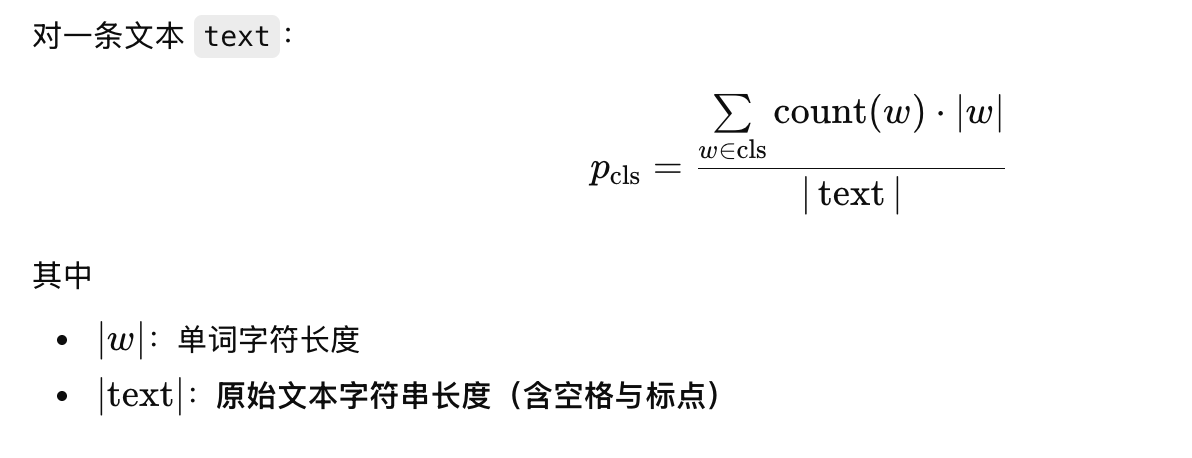

In [ ]:
!pip install wordfreq
import re
from wordfreq import zipf_frequency

def tokenize(text):
    # 与你之前一致：词 or 标点
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def zipf_length_proportions_rawlen(text):
    """
    p_cls = (该 Zipf 类别的单词字符总长度) / len(text)
    分母严格等于压缩算法看到的字符数
    """
    if not isinstance(text, str) or len(text) == 0:
        return {"low": 0.0, "mid": 0.0, "high": 0.0}

    tokens = tokenize(text)

    # 分子：每个 Zipf 类别的「单词字符长度」
    num = {"low": 0, "mid": 0, "high": 0}

    for tok in tokens:
        if tok.isalpha():          # 只对“单词”做 Zipf
            cls = classify_word_zipf(tok)
            num[cls] += len(tok)  # 单词字符数

    total_len = len(text)         # ✅ 关键：包含空格 + 标点

    return {k: v / total_len for k, v in num.items()}


In [ ]:
df["p_zipf_stats"] = df["Articles"].apply(zipf_length_proportions_rawlen)

### Updated p_i: with 6 class

low / mid / high：只对 纯字母词（英文单词）做 Zipf 分类

punct：中英文标点（以及各种符号类标点）

num_other：数字 + 其他（包含数字、混合词、中文字符、emoji、不可见字符等你不想细分的）

whitespace（空格 / 换行 / tab 等）

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def tokenize(text):
    # 词 or 单个非空白字符（空白不会被 token 化）
    return re.findall(r"\w+|[^\w\s]", text)

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    # 纯字母词（英文/拉丁字母）；你也可保留 tok.isalpha()
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等都算“数字类”
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

def zipf_length_proportions_rawlen_6cat(text):
    """
    6类比例（总和=1）：
      low/mid/high: 纯字母词按 zipf 分类，累计 len(tok)
      punct: 标点/符号 token，累计 len(tok)
      num_other: 数字 + 其它非上述 token（含中文、混合串、emoji等），累计 len(tok)
      whitespace: 所有空白字符（isspace=True），累计字符数
    分母= len(text)（压缩算法看到的字符数）
    """
    if not isinstance(text, str) or len(text) == 0:
        return {"low": 0.0, "mid": 0.0, "high": 0.0, "punct": 0.0, "num_other": 0.0, "whitespace": 0.0}

    total_len = len(text)

    # 第6类：空白字符（包含 space/newline/tab/各种 Unicode 空白）
    whitespace_len = sum(1 for ch in text if ch.isspace())

    tokens = tokenize(text)
    num = {"low": 0, "mid": 0, "high": 0, "punct": 0, "num_other": 0, "whitespace": whitespace_len}

    for tok in tokens:
        if is_punct_token(tok):
            num["punct"] += len(tok)
        elif is_alpha_word(tok):
            cls = classify_word_zipf(tok)
            num[cls] += len(tok)
        elif is_number_like(tok):
            num["num_other"] += len(tok)
        else:
            num["num_other"] += len(tok)

    # 转成比例
    props = {k: v / total_len for k, v in num.items()}

    # （可选）数值检查：理论上应非常接近 1
    # print("sum:", sum(props.values()))

    return props


In [ ]:
df["p_zipf_stats"] = df["Articles"].apply(zipf_length_proportions_rawlen_6cat)

In [ ]:
df.head(10)

### Update b_i: bertscore with only delete i

We have 6 classes. Due to the polishment is easy to change the original meaning, and for whitespace. puncutation and number_other, it doesn't change a lot of meaning, so we only use polished text for deleting low,mid, high freq and use restore text for deleting whitespace, puncutation and number_other as bertscore of only delete pi.

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

import re

from bert_score import score as bertscore
from nltk import sent_tokenize

MODEL = "distilroberta-base"

def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()


In [ ]:
def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )

#### Only delete pi

In [ ]:
!pip install wordfreq
import re
import unicodedata
from wordfreq import zipf_frequency

def classify_word_zipf(word):
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    if not tok:
        return False
    # P*: punctuation, S*: symbol
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026 等
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# ✅ 关键：包含 whitespace 的分段 tokenizer（不丢位置信息）
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """把一个 segment 归到 6 类之一。"""
    if seg.isspace():
        return "whitespace"

    # \w+ 段：可能是英文词/数字/中文/混合
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            # 数字 / 中文 / 混合串都归 num_other
            return "num_other"

    # 单字符非空白：标点/符号/emoji 等
    if is_punct_token(seg):
        return "punct"
    return "num_other"

def delete_by_class(text: str, cls_to_delete: str) -> str:
    """
    只删除指定类别的 segments，返回新文本。
    cls_to_delete in: {"low","mid","high","punct","num_other","whitespace"}
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    out = []
    for seg in _SEG_RE.findall(text):
        if segment_class(seg) == cls_to_delete:
            continue
        out.append(seg)
    return "".join(out)

def delete_variants_6cat(text: str) -> dict:
    """一次性生成 6 个版本：分别只删除某一类。"""
    classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]
    return {f"del_{c}": delete_by_class(text, c) for c in classes}


classes = ["low", "mid", "high", "punct", "num_other", "whitespace"]

for c in classes:
    df[f"delete_{c}"] = df["Articles"].apply(lambda x: delete_by_class(x, c))


In [ ]:
i = 0
print("ORIG:\n", df["Articles"].iloc[i])
print("DEL_LOW:\n", df["delete_low"].iloc[i])
print("DEL_MID:\n", df["delete_mid"].iloc[i])
print("DEL_high:\n", df["delete_high"].iloc[i])


#### LLM for restoration

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])


model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing English words (due to category-based deletion), missing punctuation symbols (e.g., commas, periods, hyphens), missing numeric or non-alphabetic tokens, or missing whitespace characters such as spaces, line breaks, or tabs.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()



def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空



cols_to_restore = ["delete_low","delete_mid","delete_high","delete_punct", "delete_num_other"] #, "delete_whitespace"]
#cols_to_restore = ["delete_whitespace"]


for col in cols_to_restore:
    curr_col=col.split("delete_")[1]
    output_col = f"restored_delete_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    df[output_col] = ""

    for idx in range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)


        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### LLM for polishment


这里只polish low/mid/high freq

In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def build_prompt_updated(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Improve fluency and readability by smoothing awkward wording while largely preserving the original phrasing and sentence structure.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.
- Prefer minimal edits over rewriting.

Restored Text:
{input_text}

Polished Output:
""".strip()


# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    #prompt = build_prompt(corrupted_text)
    prompt = build_prompt_updated(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑

cols_to_restore = ["restored_delete_low","restored_delete_mid","restored_delete_high"]
#

for col in cols_to_restore:
    curr_suffix = col.split("restored_delete_")[1]
    output_col = f"polished_delete_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    if output_col not in df.columns:
        df[output_col] = ""

    for idx in tqdm(range(len(df))):
    # ⛔ 跳过已经处理过的行（断点续跑）
        if df.at[idx, output_col]:
            continue

        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


#### Bertscore calculation

In [ ]:
import re
from bert_score import score as bertscore
from nltk import sent_tokenize
import logging

MODEL = "distilroberta-base"

df["b_zipf_stats_restore"] = None

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)

# 你指定的列名映射（更稳，不依赖startswith扫全表）
col_map = {
    "low":"restored_delete_low", #polished_delete_low",
    "mid": "restored_delete_mid", #"polished_delete_mid",
    "high":"restored_delete_high", # "polished_delete_high",
    #"punct": "restored_delete_punct",
    #"num_other": "restored_delete_num_other",
    #"whitespace": "restored_delete_whitespace",
}

for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = df.at[idx, "Articles"] # clean_text(df.at[idx, "Articles"])
    chunk_dict = {}

    for suffix, col in col_map.items():
        if col not in df.columns:
            continue  # 或者 raise，取决于你想不想强约束列必须存在

        cand = df.at[idx, col]
        # 如果有空值，跳过（避免 bertscore 报错）
        if not isinstance(cand, str) or len(cand.strip()) == 0:
            chunk_dict[suffix] = None
            continue

        P, R, F1 = bertscore(
            [cand], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )
        chunk_dict[suffix] = float(F1[0])

    df.at[idx, "b_zipf_stats_restore"] = chunk_dict


In [ ]:
import ast
df["b_zipf_stats_restore"] = df["b_zipf_stats_restore"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)
df["b_zipf_stats"] = df["b_zipf_stats"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [ ]:
for idx in range(len(df)):
  curr1= df.at[idx,"b_zipf_stats"]['punct']
  curr2= df.at[idx,"b_zipf_stats"]['num_other']
  curr3= df.at[idx,"b_zipf_stats"]['whitespace']
  df.at[idx,"b_zipf_stats_restore"]['punct']=curr1
  df.at[idx,"b_zipf_stats_restore"]['num_other']=curr2
  df.at[idx,"b_zipf_stats_restore"]['whitespace']=curr3

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Solve the Equation

**KTT+Bisection**

In [ ]:
import numpy as np

def solve_max_product(b, p, T, tol=1e-14, max_iter=500, verbose=False):
    """
    Solve:
        max Π_i [1 - (1-b_i) w_i]
        s.t. Σ_i p_i (1 - w_i) <= T
             0 <= w_i <= 1

    Parameters
    ----------
    b : array-like, shape (n,)
        b_i values.
    p : array-like, shape (n,)
        p_i >= 0 weights.
    T : float
        Budget T.
    tol : float
        tolerance for constraint satisfaction.
    max_iter : int
        max iterations for bisection.
    verbose : bool
        print debug info.

    Returns
    -------
    w_star : np.ndarray, shape (n,)
        optimal w
    info : dict
        objective, constraint_value, lambda, status
    """
    b = np.asarray(b, dtype=float)
    p = np.asarray(p, dtype=float)
    n = len(b)

    if len(p) != n:
        raise ValueError("b and p must have same length")
    if np.any(p < 0):
        raise ValueError("p_i must be >= 0")
    if T < 0:
        raise ValueError("T must be >= 0")

    a = 1.0 - b  # a_i

    # If constraint already satisfied at w=0, that's optimal (objective decreases with w if a_i>=0)
    lhs_w0 = np.sum(p * (1.0 - 0.0))
    if lhs_w0 <= T + tol:
        w_star = np.zeros(n)
        obj = float(np.prod(1.0 - a * w_star))
        cons = float(np.sum(p * (1.0 - w_star)))
        return w_star, {
            "objective": obj,
            "constraint_value": cons,
            "lambda": 0.0,
            "status": "constraint_not_active (w=0 optimal)"
        }

    # We need: Σ p_i (1 - w_i) = T  (active)
    # Define w(lambda) = clip( 1/a_i - 1/(lambda p_i), 0, 1 ) for a_i>0, p_i>0
    # Special cases:
    # - p_i = 0 : constraint ignores it, set w_i=0 to maximize objective
    # - a_i = 0 : objective ignores it, can use it to satisfy constraint -> set w_i=1 if needed

    w = np.zeros(n)

    # First, set p_i=0 -> w_i=0 always best
    mask_p_pos = p > 0

    # For a_i = 0 (b_i=1): objective unaffected.
    # We'll start them at 0, but later if constraint too tight, we can push them towards 1.
    mask_a_zero = np.isclose(a, 0.0)
    mask_a_pos = (~mask_a_zero)

    # Helper to compute w for given lambda only on (a_i>0, p_i>0)
    def w_from_lambda(lam):
        w_tmp = np.zeros(n)

        # p_i=0 => keep 0
        # a_i=0 => keep 0 for now (handled separately below)

        idx = mask_p_pos & mask_a_pos
        # formula: 1/a_i - 1/(lam p_i)
        w_tmp[idx] = (1.0 / a[idx]) - (1.0 / (lam * p[idx]))
        w_tmp[idx] = np.clip(w_tmp[idx], 0.0, 1.0)

        return w_tmp

    def constraint_value(wv):
        return float(np.sum(p * (1.0 - wv)))

    # If we can satisfy constraint using only a_i=0 items by setting them to 1, do that first
    # Because they don't hurt objective at all.
    w_free = np.zeros(n)
    w_free[mask_a_zero & mask_p_pos] = 1.0
    cons_free = constraint_value(w_free)
    if cons_free <= T + tol:
        # Great: constraint satisfied just by turning on free variables.
        # But we want maximize objective -> keep all costly vars at 0, only use enough free vars to meet T.
        # We can "partially" use free vars since w_i ∈ [0,1].
        w_star = np.zeros(n)
        free_idx = np.where(mask_a_zero & mask_p_pos)[0]

        # Need Σ p_i(1-w_i)=T -> reduce LHS from Σp to T by increasing w.
        # On free vars, increasing w reduces LHS by p_i w_i, no objective cost.
        need_reduction = np.sum(p) - T  # amount of Σ p_i w_i needed
        # Greedy fill free vars (any order works since no obj cost; use largest p first for numerical stability)
        free_idx = free_idx[np.argsort(-p[free_idx])]
        for i in free_idx:
            if need_reduction <= 0:
                break
            add = min(1.0, need_reduction / p[i])
            w_star[i] = add
            need_reduction -= p[i] * add

        obj = float(np.prod(1.0 - a * w_star))
        cons = constraint_value(w_star)
        return w_star, {
            "objective": obj,
            "constraint_value": cons,
            "lambda": None,
            "status": "solved_using_a_zero_items_only"
        }

    # Otherwise, we must use a_i>0 variables too; we find lambda by bisection.
    # Find hi such that constraint(w(hi)) <= T (feasible)
    lam_lo = 1e-12
    lam_hi = 1.0

    # Expand lam_hi until feasible
    for _ in range(200):
        w_hi = w_from_lambda(lam_hi)
        if constraint_value(w_hi) <= T + tol:
            break
        lam_hi *= 2.0
    else:
        # If never feasible, even with very large lambda, something is off (usually T too small like 0)
        # In extreme, w_i will clip to 1, so check that:
        w_all = np.zeros(n)
        w_all[mask_p_pos & mask_a_pos] = 1.0
        w_all[mask_a_zero & mask_p_pos] = 1.0
        if constraint_value(w_all) > T + tol:
            raise RuntimeError("Infeasible: even w_i=1 for all does not satisfy constraint.")
        # else should have broken earlier
        lam_hi = lam_hi

    # Bisection
    best_w = None
    best_lam = None
    for it in range(max_iter):
        lam_mid = 0.5 * (lam_lo + lam_hi)
        w_mid = w_from_lambda(lam_mid)

        cons_mid = constraint_value(w_mid)
        if verbose:
            print(f"iter={it}, lam={lam_mid:.3e}, constraint={cons_mid:.12f}")

        # Want cons_mid == T, but monotonic: larger lambda -> larger w -> smaller constraint
        if cons_mid > T:
            lam_lo = lam_mid
        else:
            lam_hi = lam_mid
            best_w = w_mid
            best_lam = lam_mid

        if abs(cons_mid - T) <= tol:
            best_w = w_mid
            best_lam = lam_mid
            break

    # After solving costly vars, we can also optionally use a_i=0 vars to fine-tune (won't hurt objective).
    # But bisection already meets T (within tol), so we leave them at 0.
    w_star = best_w if best_w is not None else w_from_lambda(lam_hi)

    obj = float(np.prod(1.0 - a * w_star))
    cons = constraint_value(w_star)

    return w_star, {
        "objective": obj,
        "constraint_value": cons,
        "lambda": float(best_lam) if best_lam is not None else float(lam_hi),
        "status": "solved_by_kkt_bisection"
    }


# -----------------------------
# Example usage
# -----------------------------
#if __name__ == "__main__":


In [ ]:

b=list(df["b_zipf_stats"].iloc[3].values())
p=list(ast.literal_eval(df["p_zipf_stats"].iloc[3]).values())
T = 0.9

w_star, info = solve_max_product(b, p, T, verbose=False)
print("w* =", w_star)
print("info =", info)


In [ ]:
print("b",b)
print("p",p)

#### **KTT+Bisection+Decimal**

In [ ]:
import numpy as np
import ast

def solve_max_product_high_precision(
    b, p, T,
    tol=1e-14,
    max_iter=800,
    verbose=False,
    snap_single_active=True,
    refine_constraint=True
):
    """
    Solve:
        max Π_i [1 - (1-b_i) w_i]
        s.t. Σ_i p_i (1 - w_i) <= T
             0 <= w_i <= 1

    Uses KKT water-filling + bisection on lambda.
    Then improves numerical precision by:
      - optional "snap" to closed-form if only one active interior variable
      - optional one-step refinement to enforce constraint equality to ~machine precision

    Returns
    -------
    w_star : np.ndarray
    info : dict
    """
    b = np.asarray(b, dtype=np.float64)
    p = np.asarray(p, dtype=np.float64)
    n = len(b)

    if len(p) != n:
        raise ValueError("b and p must have same length")
    if np.any(p < 0):
        raise ValueError("p_i must be >= 0")
    if T < 0:
        raise ValueError("T must be >= 0")

    a = 1.0 - b  # a_i

    # Guard: assume b in [0,1] => a in [0,1]
    if np.any(a < -1e-12):
        raise ValueError("Found b_i > 1 (a_i < 0). This solver assumes b_i in [0,1].")

    def objective(w):
        return float(np.prod(1.0 - a * w))

    def constraint(w):
        # keep float64 inside; only cast at the end
        return np.sum(p * (1.0 - w), dtype=np.float64)

    # ---------------------------
    # Case 1: constraint not active => w=0
    # ---------------------------
    w0 = np.zeros(n, dtype=np.float64)
    if constraint(w0) <= T + tol:
        w_star = w0
        return w_star, {
            "objective": objective(w_star),
            "constraint_value": float(constraint(w_star)),
            "lambda": 0.0,
            "status": "constraint_not_active (w=0 optimal)"
        }

    # ---------------------------
    # Masks & special cases
    # ---------------------------
    mask_p_pos = p > 0
    mask_a_zero = np.isclose(a, 0.0)      # a_i=0 => b_i=1 => objective unaffected
    mask_core = mask_p_pos & (~mask_a_zero)

    # If feasible can be achieved by only a=0 variables, do that optimally (no objective loss).
    w_free = np.zeros(n, dtype=np.float64)
    w_free[mask_p_pos & mask_a_zero] = 1.0
    if constraint(w_free) <= T + tol:
        # Need Σ p_i w_i = Σp - T using only free vars
        w_star = np.zeros(n, dtype=np.float64)
        need = float(np.sum(p) - T)

        free_idx = np.where(mask_p_pos & mask_a_zero)[0]
        free_idx = free_idx[np.argsort(-p[free_idx])]  # big p first

        for i in free_idx:
            if need <= 0:
                break
            add = min(1.0, need / p[i])
            w_star[i] = add
            need -= p[i] * add

        return w_star, {
            "objective": objective(w_star),
            "constraint_value": float(constraint(w_star)),
            "lambda": None,
            "status": "solved_using_a_zero_items_only"
        }

    # ---------------------------
    # Water-filling map w(lambda)
    # ---------------------------
    def w_from_lambda(lam):
        w = np.zeros(n, dtype=np.float64)
        idx = mask_core
        # w = 1/a - 1/(lam p)
        w[idx] = (1.0 / a[idx]) - (1.0 / (lam * p[idx]))
        w[idx] = np.clip(w[idx], 0.0, 1.0)
        return w

    # ---------------------------
    # Find bracketing interval for lambda
    # ---------------------------
    lam_lo = np.float64(1e-18)
    lam_hi = np.float64(1.0)

    # Expand lam_hi until feasible: constraint(w(lam_hi)) <= T
    for _ in range(400):
        if constraint(w_from_lambda(lam_hi)) <= T + tol:
            break
        lam_hi *= 2.0
    else:
        # Check feasibility at w=1
        w_all = np.zeros(n, dtype=np.float64)
        w_all[mask_p_pos] = 1.0
        if constraint(w_all) > T + tol:
            raise RuntimeError("Infeasible: even w_i=1 for all i cannot satisfy constraint.")
        # else okay

    # ---------------------------
    # Bisection on lambda
    # ---------------------------
    best_w = None
    best_lam = None

    for it in range(max_iter):
        lam_mid = (lam_lo + lam_hi) * 0.5
        w_mid = w_from_lambda(lam_mid)
        c_mid = constraint(w_mid)

        if verbose and (it % 20 == 0 or it < 10):
            print(f"it={it:4d}, lam={lam_mid:.18e}, constraint={c_mid:.18e}, diff={c_mid-T:.3e}")

        # constraint decreases as lambda increases
        if c_mid > T:
            lam_lo = lam_mid
        else:
            lam_hi = lam_mid
            best_w = w_mid
            best_lam = lam_mid

        if abs(c_mid - T) <= tol:
            best_w = w_mid
            best_lam = lam_mid
            break

    w_star = best_w if best_w is not None else w_from_lambda(lam_hi)
    lam_star = float(best_lam) if best_lam is not None else float(lam_hi)

    # ---------------------------
    # Optional: snap single interior active dim to closed form (very high precision)
    # ---------------------------
    if snap_single_active:
        active = np.where((w_star > 1e-12) & (w_star < 1 - 1e-12) & (p > 0))[0]
        if len(active) == 1:
            k = active[0]
            sum_p = float(np.sum(p))
            w_k = (sum_p - T) / float(p[k])
            w_new = np.zeros_like(w_star)
            w_new[k] = np.clip(w_k, 0.0, 1.0)
            w_star = w_new
            # lambda not strictly needed; keep lam_star as bisection result

    # ---------------------------
    # Optional: one-step refinement to enforce constraint equality to ~machine precision
    # ---------------------------
    if refine_constraint:
        curr = float(constraint(w_star))
        delta = curr - T  # want delta -> 0
        if abs(delta) > 5e-16:
            # Choose best index to absorb delta:
            # prefer interior vars; prefer low harm = a / (p*(1-a*w))
            candidates = np.where((p > 0) & (w_star > 0) & (w_star < 1))[0]
            if len(candidates) == 0:
                candidates = np.where((p > 0) & (w_star < 1))[0]

            best_i = None
            best_score = None
            for i in candidates:
                if np.isclose(a[i], 0.0):
                    score = -np.inf  # free objective => best
                else:
                    denom = float(p[i]) * max(1e-300, float(1.0 - a[i] * w_star[i]))
                    score = float(a[i]) / denom
                if best_score is None or score < best_score:
                    best_score = score
                    best_i = i

            if best_i is not None:
                dw = delta / float(p[best_i])  # constraint changes by -p_i*dw
                w_star[best_i] = np.clip(w_star[best_i] + dw, 0.0, 1.0)

    # Final outputs
    cons = float(constraint(w_star))
    obj = objective(w_star)

    return w_star, {
        "objective": obj,
        "constraint_value": cons,
        "lambda": lam_star,
        "status": "solved_by_kkt_bisection + refined"
    }


# ---------------------------
# Helper: safely extract b,p aligned by keys
# ---------------------------
def extract_bp_from_df(df, row_idx, b_col="b_zipf_stats_restore", p_col="p_zipf_stats", keys=None):
    """
    Extract b and p from df row, aligning dict keys to avoid mismatch from .values().
    If keys is None, uses sorted keys from b_dict.
    """
    b_dict = df[b_col].iloc[row_idx]
    if isinstance(b_dict, str):
        b_dict = ast.literal_eval(b_dict)

    p_dict = df[p_col].iloc[row_idx]
    if isinstance(p_dict, str):
        p_dict = ast.literal_eval(p_dict)

    if keys is None:
        keys = sorted(b_dict.keys())

    b = [b_dict[k] for k in keys]
    p = [p_dict[k] for k in keys]
    return b, p, keys


# ---------------------------
# Example usage (you can adapt)
# ---------------------------
# b, p, keys = extract_bp_from_df(df, 3, keys=["low","mid","high"])
# T = 0.9
# w_star, info = solve_max_product_high_precision(b, p, T, verbose=False)
# print("keys =", keys)
# print("b =", b)
# print("p =", p)
# print("w* =", w_star)
# print("info =", info)
# print("constraint diff =", info["constraint_value"] - T)


In [ ]:
b, p, keys = extract_bp_from_df(df, 3, keys=["low","mid","high","punct","num_other","whitespace"])  # 或者 keys=None 自动排序
T = 0.9

w_star, info = solve_max_product_high_precision(b, p, T, verbose=False)
print("keys =", keys)
print("w* =", w_star)
print("info =", info)
print("diff =", info["constraint_value"] - T)


In [ ]:
df["w_restore_optimal_kkt"] = [dict() for _ in range(len(df))]
df["w_restore_info_kkt"] = [dict() for _ in range(len(df))]


for i in range(len(df)):
    print("No",i)
    b, p, keys = extract_bp_from_df(df, i, b_col="b_zipf_stats_restore",
    p_col="p_zipf_stats",keys=["low","mid","high","punct","num_other","whitespace"])

    T_items = [
        ("0.9", 0.9),
        ("0.8", 0.8),
        ("lz4",  float(df.at[i, "lz4_ratio"])),
        ("0.7", 0.7),
        ("0.6", 0.6),
        ("lzma", float(df.at[i, "lzma_ratio"])),
        ("0.5", 0.5),
        ("gzip", float(df.at[i, "gzip_ratio"])),
        ("0.4", 0.4),
        ("0.3", 0.3),
        ("0.2", 0.2),
        ("0.1", 0.1),
    ]

    for label, t in T_items:
        w_star, info = solve_max_product_high_precision(b, p, t, verbose=False)
        df.at[i, "w_restore_optimal_kkt"][label] = w_star.tolist()   # 或者直接 w_star
        df.at[i, "w_restore_info_kkt"][label] = info   # 存最后一次的 info


In [ ]:
df.head(10)

#### **CVX**

In [ ]:
import numpy as np
import ast
import cvxpy as cp


def extract_bp_from_df(df, row_idx, b_col="b_zipf_stats", p_col="p_zipf_stats", keys=None):
    b_dict = df[b_col].iloc[row_idx]
    if isinstance(b_dict, str):
        b_dict = ast.literal_eval(b_dict)

    p_dict = df[p_col].iloc[row_idx]
    if isinstance(p_dict, str):
        p_dict = ast.literal_eval(p_dict)

    if keys is None:
        keys = sorted(b_dict.keys())

    b = np.array([b_dict[k] for k in keys], dtype=float)
    p = np.array([p_dict[k] for k in keys], dtype=float)
    return b, p, keys

def solve_max_product_cvxpy(b, p, T, eps=1e-12, solver="ECOS", verbose=False):
    """
    Solve via CVXPY:
        max Π_i [1 - (1-b_i) w_i]
        s.t. Σ p_i(1-w_i) <= T, 0<=w<=1

    We solve equivalent:
        max Σ log(1 - (1-b_i) w_i)
    """
    b = np.asarray(b, dtype=float)
    p = np.asarray(p, dtype=float)
    a = 1.0 - b
    n = len(b)

    w = cp.Variable(n)

    # log argument
    t = 1 - cp.multiply(a, w)

    constraints = [
        cp.sum(cp.multiply(p, 1 - w)) <= T,
        w >= 0,
        w <= 1,
        t >= eps,   # avoid log(0)
    ]

    objective = cp.Maximize(cp.sum(cp.log(t)))
    prob = cp.Problem(objective, constraints)

    # Solver options (different solvers have different knobs)
    if solver.upper() == "ECOS":
        prob.solve(solver=cp.ECOS, verbose=verbose,
                   abstol=1e-12, reltol=1e-12, feastol=1e-12, max_iters=2000)
    elif solver.upper() == "SCS":
        prob.solve(solver=cp.SCS, verbose=verbose,
                   eps=1e-6, max_iters=200000)  # SCS is first-order; eps is looser by default
    elif solver.upper() == "CLARABEL":
        prob.solve(solver=cp.CLARABEL, verbose=verbose)
    else:
        prob.solve(verbose=verbose)

    w_star = np.array(w.value).astype(float)

    # Recover original product objective (careful about underflow; log is safer)
    prod_obj = float(np.prod(1.0 - a * w_star))
    cons_val = float(np.sum(p * (1.0 - w_star)))

    return w_star, {
        "objective_product": prod_obj,
        "objective_logsum": float(np.sum(np.log(np.maximum(1.0 - a * w_star, 1e-300)))),
        "constraint_value": cons_val,
        #"solver": solver
        "diff":cons_val-T,
        "status": prob.status
    }


# ---------------------------
# Example usage
idx=3
b, p, keys = extract_bp_from_df(df, idx, b_col="b_zipf_stats",
    p_col="p_zipf_stats",keys=["low","mid","high","punct","num_other","whitespace"]) #keys=["low","mid","high"])
T = 0.9
w_star, info = solve_max_product_cvxpy(b, p, T, solver="CLARABEL", verbose=False)
print("keys =", keys)
print("w* =", w_star)
print("info =", info)
#print("diff =", info["constraint_value"] - T)


In [ ]:
df["w_restore_optimal_cvx"] = [dict() for _ in range(len(df))]
df["w_restore_info_cvx"] = [dict() for _ in range(len(df))]

for i in range(len(df)):
    print("No",i)
    b, p, keys = extract_bp_from_df(df, i, b_col="b_zipf_stats_restore",
    p_col="p_zipf_stats",keys=["low","mid","high","punct","num_other","whitespace"])

    T_items = [
        ("0.9", 0.9),
        ("0.8", 0.8),
        ("lz4",  float(df.at[i, "lz4_ratio"])),
        ("0.7", 0.7),
        ("0.6", 0.6),
        ("lzma", float(df.at[i, "lzma_ratio"])),
        ("0.5", 0.5),
        ("gzip", float(df.at[i, "gzip_ratio"])),
        ("0.4", 0.4),
        ("0.3", 0.3),
        ("0.2", 0.2),
        ("0.1", 0.1),
    ]

    for label, t in T_items:
        w_star, info = solve_max_product_cvxpy(b, p, t, solver="CLARABEL", verbose=False)
        df.at[i, "w_restore_optimal_cvx"][label] = w_star.tolist()   # 或者直接 w_star
        df.at[i, "w_restore_info_cvx"][label] = info   # 存最后一次的 info


#### Figure Plot

In [ ]:
df.head(10)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

LABELS = ["0.9","0.8","lz4","0.7","0.6","lzma","0.5","gzip","0.4","0.3","0.2","0.1"]

import ast
import numpy as np

def ensure_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return None
    return None


def summarize_means(df, w_col="w_restore_optimal_kkt", info_col="w_restore_info_kkt", labels=LABELS):
    mean_w = {}
    mean_obj = {}
    count = {}

    for lab in labels:
        w_list = []
        obj_list = []

        for i in range(len(df)):
            w_dict = ensure_dict(df.at[i, w_col])
            info_dict = ensure_dict(df.at[i, info_col])

            if not isinstance(w_dict, dict) or not isinstance(info_dict, dict):
                continue
            if lab not in w_dict or lab not in info_dict:
                continue

            w_arr = np.asarray(w_dict[lab], dtype=float)
            if w_arr.shape != (6,) or np.any(np.isnan(w_arr)):
                continue

            info_val = info_dict[lab]
            if not isinstance(info_val, dict) or "objective" not in info_val:
                continue

            obj = float(info_val["objective"])
            if np.isnan(obj):
                continue

            w_list.append(w_arr)
            obj_list.append(obj)

        if len(w_list) == 0:
            mean_w[lab] = np.array([np.nan, np.nan, np.nan])
            mean_obj[lab] = np.nan
            count[lab] = 0
        else:
            W = np.vstack(w_list)
            mean_w[lab] = W.mean(axis=0)
            mean_obj[lab] = float(np.mean(obj_list))
            count[lab] = len(w_list)

    return mean_w, mean_obj, count



mean_w, mean_obj, count = summarize_means(df)
print("counts per label:", mean_w)


In [ ]:
def build_xtick_labels(df, labels=LABELS, decimals=3):
    # 这三个 label 用 df 中对应列的均值替换显示
    mapping = {
        "lz4":  ("lz4_ratio",  "lz4"),
        "lzma": ("lzma_ratio", "lzma"),
        "gzip": ("gzip_ratio", "gzip"),
    }

    xticks = []
    for lab in labels:
        if lab in mapping:
            col, name = mapping[lab]
            val = float(np.nanmean(df[col].astype(float)))
            xticks.append(f"{name}({val:.{decimals}f})")
        else:
            xticks.append(lab)
    return xticks

xtick_labels = build_xtick_labels(df, LABELS, decimals=3)
x = np.arange(len(LABELS))
y_obj = [mean_obj[lab] for lab in LABELS]

plt.figure()
plt.plot(x, y_obj, marker="o")
plt.xticks(x, xtick_labels, rotation=45)
plt.xlabel("Tc")
plt.ylabel("Mean objective_product (over rows)")
plt.title("Mean objective_product vs Tc for restoring kkt solution")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
def build_xtick_labels(df, labels=LABELS, decimals=3):
    # 这三个 label 用 df 中对应列的均值替换显示
    mapping = {
        "lz4":  ("lz4_ratio",  "lz4"),
        "lzma": ("lzma_ratio", "lzma"),
        "gzip": ("gzip_ratio", "gzip"),
    }

    xticks = []
    for lab in labels:
        if lab in mapping:
            col, name = mapping[lab]
            val = float(np.nanmean(df[col].astype(float)))
            xticks.append(f"{name}({val:.{decimals}f})")
        else:
            xticks.append(lab)
    return xticks

xtick_labels = build_xtick_labels(df, LABELS, decimals=3)

x = np.arange(len(LABELS))

w_low  = [mean_w[lab][0] for lab in LABELS]
w_mid  = [mean_w[lab][1] for lab in LABELS]
w_high = [mean_w[lab][2] for lab in LABELS]
w_punct = [mean_w[lab][3] for lab in LABELS]
w_num   = [mean_w[lab][4] for lab in LABELS]
w_space = [mean_w[lab][5] for lab in LABELS]

plt.figure(figsize=(10, 5))

plt.plot(x, w_low,   marker="o", label="low")
plt.plot(x, w_mid,   marker="s", label="mid")
plt.plot(x, w_high,  marker="^", label="high")
plt.plot(x, w_punct, marker="D", label="punct")
plt.plot(x, w_num,   marker="v", label="num_other")
plt.plot(x, w_space, marker="o", label="whitespace")

plt.xticks(x, xtick_labels, rotation=45)
plt.xlabel("Tc")
plt.ylabel("Mean w (over rows)")
plt.title("Mean w allocation vs Tc for restoring kkt solution")

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0
)

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
def annotate_points_with_offsets(x, y, fmt="{:.3f}", dx=0, dy=0, fontsize=8):
    for xi, yi in zip(x, y):
        if np.isnan(yi):
            continue
        plt.annotate(
            fmt.format(yi),
            (xi, yi),
            textcoords="offset points",
            xytext=(dx, dy),
            ha="center",
            va="center",
            fontsize=fontsize
        )

def build_xtick_labels(df, labels=LABELS, decimals=3):
    # 这三个 label 用 df 中对应列的均值替换显示
    mapping = {
        "lz4":  ("lz4_ratio",  "lz4"),
        "lzma": ("lzma_ratio", "lzma"),
        "gzip": ("gzip_ratio", "gzip"),
    }

    xticks = []
    for lab in labels:
        if lab in mapping:
            col, name = mapping[lab]
            val = float(np.nanmean(df[col].astype(float)))
            xticks.append(f"{name}({val:.{decimals}f})")
        else:
            xticks.append(lab)
    return xticks

xtick_labels = build_xtick_labels(df, LABELS, decimals=3)
x = np.arange(len(LABELS))

plt.figure(figsize=(10, 5))

plt.plot(x, w_low,   marker="o", label="low")
plt.plot(x, w_mid,   marker="s", label="mid")
plt.plot(x, w_high,  marker="^", label="high")
plt.plot(x, w_punct, marker="D", label="punct")
plt.plot(x, w_num,   marker="v", label="num_other")
plt.plot(x, w_space, marker="o", label="whitespace")

# 为每条线分配不同的 (dx, dy)，把标签“错开”
annotate_points_with_offsets(x, w_low,   dx=-10, dy=-12, fontsize=8)
annotate_points_with_offsets(x, w_mid,   dx=0,   dy=10,  fontsize=8)
annotate_points_with_offsets(x, w_high,  dx=10,  dy=-12, fontsize=8)
annotate_points_with_offsets(x, w_punct, dx=-10, dy=10,  fontsize=8)
annotate_points_with_offsets(x, w_num,   dx=10,  dy=10,  fontsize=8)
annotate_points_with_offsets(x, w_space, dx=0,   dy=-12, fontsize=8)

plt.xticks(x, xtick_labels, rotation=45)
plt.xlabel("Tc")
plt.ylabel("Mean w (over rows)")
plt.title("Mean w allocation vs Tc for restoring kkt solution")

plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)
plt.grid(True)
plt.tight_layout()
plt.show()


##### Update Figure

In [ ]:
import numpy as np
import ast

LABELS = ["0.9","0.8","lz4","0.7","0.6","lzma","0.5","gzip","0.4","0.3","0.2","0.1"]

def ensure_dict(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return None
    return None

def summarize_mean_std(df, w_col="w_optimal", info_col="w_info", labels=LABELS):
    """
    Returns:
      w_mean: dict lab -> np.array(3,)
      w_std : dict lab -> np.array(3,)
      obj_mean: dict lab -> float
      obj_std : dict lab -> float
      count: dict lab -> int
    """
    w_mean, w_std = {}, {}
    obj_mean, obj_std = {}, {}
    count = {}

    for lab in labels:
        w_list = []
        obj_list = []

        for i in range(len(df)):
            w_dict = ensure_dict(df.at[i, w_col])
            info_dict = ensure_dict(df.at[i, info_col])

            if not isinstance(w_dict, dict) or not isinstance(info_dict, dict):
                continue
            if lab not in w_dict or lab not in info_dict:
                continue

            w_val = w_dict[lab]
            info_val = info_dict[lab]

            if w_val is None or info_val is None:
                continue
            if not isinstance(info_val, dict) or "objective_product" not in info_val:
                continue

            w_arr = np.asarray(w_val, dtype=float)
            if w_arr.shape != (6,) or np.any(np.isnan(w_arr)):
                continue

            obj = float(info_val["objective_product"])
            if np.isnan(obj):
                continue

            w_list.append(w_arr)
            obj_list.append(obj)

        m = len(w_list)
        count[lab] = m

        if m == 0:
            w_mean[lab] = np.array([np.nan, np.nan, np.nan])
            w_std[lab]  = np.array([np.nan, np.nan, np.nan])
            obj_mean[lab] = np.nan
            obj_std[lab]  = np.nan
        else:
            W = np.vstack(w_list)  # (m,3)
            w_mean[lab] = W.mean(axis=0)
            w_std[lab]  = W.std(axis=0, ddof=1) if m > 1 else np.zeros(3)
            obj_mean[lab] = float(np.mean(obj_list))
            obj_std[lab]  = float(np.std(obj_list, ddof=1)) if m > 1 else 0.0

    return w_mean, w_std, obj_mean, obj_std, count


w_mean, w_std, obj_mean, obj_std, count = summarize_mean_std(df,w_col="w_optimal_cvx", info_col="w_info_cvx")
print("w_mean:", w_mean)


In [ ]:
def build_xtick_labels(df, labels=LABELS, decimals=3):
    # 这三个 label 用 df 中对应列的均值替换显示
    mapping = {
        "lz4":  ("lz4_ratio",  "lz4"),
        "lzma": ("lzma_ratio", "lzma"),
        "gzip": ("gzip_ratio", "gzip"),
    }

    xticks = []
    for lab in labels:
        if lab in mapping:
            col, name = mapping[lab]
            val = float(np.nanmean(df[col].astype(float)))
            xticks.append(f"{name}({val:.{decimals}f})")
        else:
            xticks.append(lab)
    return xticks

xtick_labels = build_xtick_labels(df, LABELS, decimals=3)
x = np.arange(len(LABELS))


In [ ]:
import matplotlib.pyplot as plt

y = np.array([obj_mean[lab] for lab in LABELS], dtype=float)
s = np.array([obj_std[lab]  for lab in LABELS], dtype=float)

plt.figure()
plt.plot(x, y, marker="o")
plt.fill_between(x, y - s, y + s, alpha=0.2)  # 阴影：mean ± std

plt.xticks(x, xtick_labels, rotation=45, ha="right")
plt.xlabel("Tc")
plt.ylabel("Objective Product (mean ± std)")
plt.title("Objective_product over Tc")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
wL = np.array([w_mean[lab][0] for lab in LABELS], dtype=float)
wM = np.array([w_mean[lab][1] for lab in LABELS], dtype=float)
wH = np.array([w_mean[lab][2] for lab in LABELS], dtype=float)

sL = np.array([w_std[lab][0] for lab in LABELS], dtype=float)
sM = np.array([w_std[lab][1] for lab in LABELS], dtype=float)
sH = np.array([w_std[lab][2] for lab in LABELS], dtype=float)

plt.figure()
plt.plot(x, wL, marker="o", label="low")
plt.fill_between(x, wL - sL, wL + sL, alpha=0.2)

plt.plot(x, wM, marker="s", label="mid")
plt.fill_between(x, wM - sM, wM + sM, alpha=0.2)

plt.plot(x, wH, marker="^", label="high")
plt.fill_between(x, wH - sH, wH + sH, alpha=0.2)

plt.xticks(x, xtick_labels, rotation=45, ha="right")
plt.xlabel("Tc")
plt.ylabel("w (mean ± std)")
plt.title("Optimal w allocation over Tc")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(8, 9), sharex=True)

# (a) objective
axes[0].plot(x, y, marker="o")
axes[0].fill_between(x, y - s, y + s, alpha=0.2)
axes[0].set_ylabel("Objective Product")
axes[0].set_title("(a) Objective (mean ± std)")
axes[0].grid(True)

# (b) w
axes[1].plot(x, wL, marker="o", label="low")
axes[1].fill_between(x, wL - sL, wL + sL, alpha=0.2)

axes[1].plot(x, wM, marker="s", label="mid")
axes[1].fill_between(x, wM - sM, wM + sM, alpha=0.2)

axes[1].plot(x, wH, marker="^", label="high")
axes[1].fill_between(x, wH - sH, wH + sH, alpha=0.2)

axes[1].set_ylabel("w")
axes[1].set_title("(b) Optimal w Allocation (mean ± std)")
axes[1].legend()
axes[1].grid(True)

axes[1].set_xticks(x)
axes[1].set_xticklabels(xtick_labels, rotation=45, ha="right")
axes[1].set_xlabel("Tc")

plt.tight_layout()
plt.show()


### Table Statistic

##### w_mean, w_std dataframe table

In [ ]:
import pandas as pd
import numpy as np

def build_expanded_summary_df(
    w_mean, w_std, obj_mean, obj_std,
    labels, xtick_labels
):
    # 行名（你想要体现 low/mid/high）
    rows = [
        "w_mean_low", "w_mean_mid", "w_mean_high",
        "w_std_low",  "w_std_mid",  "w_std_high",
        "obj_mean", "obj_std"
    ]

    df_out = pd.DataFrame(index=rows, columns=xtick_labels, dtype=float)

    for lab, col_name in zip(labels, xtick_labels):
        wm = w_mean.get(lab, np.array([np.nan, np.nan, np.nan], dtype=float))
        ws = w_std.get(lab,  np.array([np.nan, np.nan, np.nan], dtype=float))

        wm = np.asarray(wm, dtype=float).reshape(-1)  # ensure shape (3,)
        ws = np.asarray(ws, dtype=float).reshape(-1)

        df_out.at["w_mean_low",  col_name] = wm[0] if wm.size >= 1 else np.nan
        df_out.at["w_mean_mid",  col_name] = wm[1] if wm.size >= 2 else np.nan
        df_out.at["w_mean_high", col_name] = wm[2] if wm.size >= 3 else np.nan

        df_out.at["w_std_low",   col_name] = ws[0] if ws.size >= 1 else np.nan
        df_out.at["w_std_mid",   col_name] = ws[1] if ws.size >= 2 else np.nan
        df_out.at["w_std_high",  col_name] = ws[2] if ws.size >= 3 else np.nan

        df_out.at["obj_mean", col_name] = float(obj_mean.get(lab, np.nan))
        df_out.at["obj_std",  col_name] = float(obj_std.get(lab, np.nan))

    return df_out


df_summary_expanded = build_expanded_summary_df(
    w_mean, w_std, obj_mean, obj_std,
    labels=LABELS,
    xtick_labels=xtick_labels
)

df_summary_expanded


In [ ]:
import pandas as pd
import numpy as np

def build_summary_dataframe(
    w_mean, w_std, obj_mean, obj_std,
    labels, xtick_labels
):
    """
    Returns a DataFrame:
      rows: w_mean, w_std, obj_mean, obj_std
      columns: xtick_labels
    """
    data = {}

    for lab, col_name in zip(labels, xtick_labels):
        data[col_name] = [
            w_mean.get(lab, np.array([np.nan, np.nan, np.nan])),
            w_std.get(lab,  np.array([np.nan, np.nan, np.nan])),
            obj_mean.get(lab, np.nan),
            obj_std.get(lab,  np.nan),
        ]

    df_summary = pd.DataFrame(
        data,
        index=["w_mean", "w_std", "obj_mean", "obj_std"]
    )

    return df_summary


df_summary = build_summary_dataframe(
    w_mean, w_std, obj_mean, obj_std,
    labels=LABELS,
    xtick_labels=xtick_labels
)

df_summary

##### Detailed Dataframe

In [ ]:
import pandas as pd
import numpy as np

def build_wmean_dataframe(
    w_mean,
    labels,
    xtick_labels,
    row_names=("low", "mid", "high", "punct", "num_other", "whitespace")
):
    """
    Build DataFrame:
      rows: low, mid, high, punct, num_other, whitespace
      columns: xtick_labels
      values: mean w
    """
    data = {}

    for lab, col_name in zip(labels, xtick_labels):
        arr = w_mean.get(lab, np.full(len(row_names), np.nan))
        data[col_name] = arr

    df = pd.DataFrame(
        data,
        index=row_names
    )

    return df

df_wmean = build_wmean_dataframe(
    w_mean=w_mean,
    labels=LABELS,
    xtick_labels=xtick_labels
)

df_wmean

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Experimental Evaulation

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "english_news_wf_optimal"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df.head(10)

### Dataset Processing

In [ ]:
# ============================================================
# Full pipeline: 6-class segmentation + stochastic deletion by w
# Generates new df columns for each retention-rate key in w_all
# ============================================================

# If running in Colab:
!pip -q install wordfreq

import re
import unicodedata
import random
import ast
from typing import Dict, List, Any, Optional

import numpy as np
import pandas as pd
import random
from collections import defaultdict

from wordfreq import zipf_frequency

# -----------------------------
# 1) 6-class definitions
# -----------------------------
CLASSES = ["low", "mid", "high", "punct", "num_other", "whitespace"]

def classify_word_zipf(word: str) -> str:
    """Classify English alpha words into low/mid/high by Zipf frequency."""
    z = zipf_frequency(word.lower(), "en")
    if z <= 3:
        return "low"
    elif z <= 5:
        return "mid"
    else:
        return "high"

def is_punct_token(tok: str) -> bool:
    """Token is punctuation/symbol if all chars are category P* or S*."""
    if not tok:
        return False
    if unicodedata.category(tok[0])[0] in ("P", "S"):
        return all(unicodedata.category(ch)[0] in ("P", "S") for ch in tok)
    return False

def is_alpha_word(tok: str) -> bool:
    return tok.isalpha()

def is_number_like(tok: str) -> bool:
    # 123, 3.14, 2026-01-12, 1/12/2026, etc.
    return bool(re.fullmatch(r"[0-9]+([.,:/_-][0-9]+)*", tok))

# Keep whitespace segments to preserve position info
_SEG_RE = re.compile(r"\s+|\w+|[^\w\s]", flags=re.UNICODE)

def segment_class(seg: str) -> str:
    """
    Map a segment to one of 6 classes:
    low/mid/high (alpha words by Zipf), punct, num_other, whitespace.
    """
    if seg.isspace():
        return "whitespace"

    # \w+ could be alpha word / number / CJK / mixed
    if re.fullmatch(r"\w+", seg):
        if is_alpha_word(seg):
            return classify_word_zipf(seg)  # low/mid/high
        else:
            return "num_other"

    # non-space, non-\w: punctuation/symbol/emoji, etc.
    if is_punct_token(seg):
        return "punct"
    return "num_other"

# -----------------------------
# 2) Convert w list -> dict
# -----------------------------
def w_list_to_dict(w_list):
    return dict(zip(CLASSES, w_list))
# -----------------------------
# 3) Stochastic deletion by w
# -----------------------------

def _compute_keep_ratio(original: str, modified: str) -> float:
    return len(modified) / max(len(original), 1)

def delete_by_w_length_budget_with_target(
    text: str,
    w_dict: Dict[str, float],
    T: float,                      # 目标保留率，例如 0.9
    lower: float = 0.88,           # 允许下界
    eps: float = 1e-6,
    seed: Optional[int] = None,
) -> str:
    """
    目标：最终保留率 keep_ratio 落在 [lower, T]，并尽量贴近 T（不超过T）。
    1) 先按类长度预算删（segment级）
    2) 若 keep_ratio > T：用 whitespace 做字符级微调删到接近 T
    3) 若 keep_ratio < lower：回退到微调前文本（更保守）
    """
    if not isinstance(text, str) or len(text) == 0:
        return text

    rng = random.Random(seed)
    segs = _SEG_RE.findall(text)

    class_items = defaultdict(list)
    for idx, seg in enumerate(segs):
        cls = segment_class(seg)
        class_items[cls].append((idx, seg, len(seg)))

    to_delete = set()

    for cls, items in class_items.items():
        w = float(w_dict.get(cls, 0.0))
        w = max(0.0, min(1.0, w))
        if w == 0.0:
            continue

        total_len = sum(l for _, _, l in items)
        target_del_len = w * total_len

        rng.shuffle(items)

        acc = 0
        for idx, seg, l in items:
            if acc >= target_del_len:
                break
            to_delete.add(idx)
            acc += l

    # --- 重建第一次（微调前） ---
    out_before_tweak = "".join(seg for i, seg in enumerate(segs) if i not in to_delete)
    keep_ratio = _compute_keep_ratio(text, out_before_tweak)

    out = out_before_tweak

    # --- 如果保留率 > T：删少了，用 whitespace 字符级补刀 ---
    if keep_ratio > T + eps:
        target_len = int(round(T * len(text)))
        need_del_chars = len(out) - target_len  # 需要再删掉的字符数（尽量从空白删）
        if need_del_chars > 0:
            out_chars = list(out)
            removed = 0
            for j in range(len(out_chars) - 1, -1, -1):
                if removed >= need_del_chars:
                    break
                if out_chars[j].isspace():
                    out_chars[j] = ""
                    removed += 1
            out = "".join(out_chars)

    # --- 保底：如果删过头，回退到微调前 ---
    keep_ratio_after = _compute_keep_ratio(text, out)
    if keep_ratio_after < lower - eps:
        return out_before_tweak

    return out


def ensure_w_dict(x):
    """df 单元格可能是 dict / str(dict) / [dict]，统一转成 dict"""
    if isinstance(x, dict):
        return x
    if isinstance(x, list) and len(x) == 1 and isinstance(x[0], dict):
        return x[0]
    if isinstance(x, str):
        y = ast.literal_eval(x)
        if isinstance(y, dict):
            return y
        if isinstance(y, list) and len(y) == 1 and isinstance(y[0], dict):
            return y[0]
    raise TypeError(f"Unsupported w format: {type(x)}")

def key_to_colname(prefix: str, key: str) -> str:
    """'0.9'->optimal_del_90, 'lz4'->optimal_del_lz4"""
    try:
        T = float(key)
        return f"{prefix}_{int(round(T*100))}"
    except:
        return f"{prefix}_{str(key)}"

def apply_optimal_del_columns_mixed_keys(
    df: pd.DataFrame,
    text_col: str = "Articles",
    w_col: str = "w_optimal_cvx",
    prefix: str = "optimal_del",
    band: float = 0.02,
    base_seed: int = 123,
    compressor_T_cols: dict = None,   # e.g. {"lz4":"lz4_ratio","lzma":"lzma_ratio","gzip":"gzip_ratio"}
) -> pd.DataFrame:
    """
    对 df 每行：
      - 数值 key: T=float(key)
      - compressor key: T=df[对应ratio列] 的逐行值
    每个 key 生成单独一列。
    """
    if compressor_T_cols is None:
        compressor_T_cols = {"lz4": "lz4_ratio", "lzma": "lzma_ratio", "gzip": "gzip_ratio"}

    # 1) 收集全表所有 key（来自 w_col）
    all_keys = set()
    for x in df[w_col]:
        if x is None or (isinstance(x, float) and np.isnan(x)):
            continue
        w_all = ensure_w_dict(x)
        all_keys.update(w_all.keys())

    # 2) 拆分：数值 key + compressor key
    numeric_keys = []
    comp_keys = []

    for k in all_keys:
        ks = str(k)
        if ks in compressor_T_cols:
            comp_keys.append(ks)
        else:
            try:
                float(ks)
                numeric_keys.append(ks)
            except:
                # 其他非数值、非 compressor 的 key（如果未来有）先忽略
                pass

    numeric_keys = sorted(numeric_keys, key=lambda x: float(x), reverse=True)
    comp_keys = sorted(comp_keys)  # lz4/gzip/lzma 顺序随意，你也可自定义

    # 3) 先做数值 key（T固定 = float(key)）
    for key in numeric_keys:
        T_fixed = float(key)
        col = key_to_colname(prefix, key)

        out = []
        lower_fixed = max(0.0, T_fixed - band)

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_fixed,
                    lower=lower_fixed,
                    seed=seed
                )
            )
        df[col] = out

    # 4) 再做 compressor key（T逐行取 df[ratio_col]）
    for key in comp_keys:
        ratio_col = compressor_T_cols[key]
        if ratio_col not in df.columns:
            raise KeyError(f"Missing ratio column '{ratio_col}' for key '{key}'")

        col = key_to_colname(prefix, key)
        out = []

        for i in range(len(df)):
            text = df[text_col].iloc[i]
            w_all = ensure_w_dict(df[w_col].iloc[i])

            if key not in w_all:
                out.append(text)
                continue

            # 逐行 T
            T_i = float(df[ratio_col].iloc[i])
            # 安全剪裁到 [0,1]
            T_i = max(0.0, min(1.0, T_i))
            lower_i = max(0.0, T_i - band)

            w_dict = w_list_to_dict(w_all[key])
            seed = (hash((base_seed, i, key)) & 0xFFFFFFFF)

            out.append(
                delete_by_w_length_budget_with_target(
                    text=text,
                    w_dict=w_dict,
                    T=T_i,
                    lower=lower_i,
                    seed=seed
                )
            )
        df[col] = out

    return df

df = apply_optimal_del_columns_mixed_keys(
    df,
    text_col="Articles",
    w_col="w_optimal_cvx",
    prefix="optimal_keep",
    band=0.02,
    compressor_T_cols={"lz4":"lz4_ratio", "lzma":"lzma_ratio", "gzip":"gzip_ratio"}
)

In [ ]:
df.head(10)

In [ ]:
def keep_ratio_summary(df, src_col, gen_col):
    ratios = df.apply(lambda r: len(r[gen_col]) / max(len(r[src_col]), 1), axis=1)
    return float(ratios.min()), float(ratios.mean()), float(ratios.max())

for c in [c for c in df.columns if c.startswith("optimal_keep_")]:
    mn, mean, mx = keep_ratio_summary(df, "Articles", c)
    print(c, "min/mean/max keep =", mn, mean, mx)

rows = []
for c in [c for c in df.columns if c.startswith("optimal_keep_")]:
    T = int(c.split("_")[-1]) / 100.0   # optimal_del_90 -> 0.9
    mn, mean, mx = keep_ratio_summary(df, "Articles", c)
    rows.append({
        "col": c,
        "T": T,
        "lower": T - 0.02,
        "min_keep": mn,
        "mean_keep": mean,
        "max_keep": mx,
    })

keep_summary_df = pd.DataFrame(rows).sort_values("T", ascending=False)
keep_summary_df


### LLM for restoration

In [ ]:
df["restored_optimal_keep_70"].iloc[190]

In [ ]:
import os
from tqdm import tqdm
import time
tqdm.pandas()

!pip install -U google-generativeai

import google.generativeai as genai
# NEW correct initialization
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
                #os.environ["GOOGLE_API_KEY"])


model = genai.GenerativeModel("gemini-2.0-flash")



def build_prompt(corrupted_text):
  return f"""
You are a linguistic reconstruction model whose goal is to recover the original text from corrupted input.

The text may have missing English words (due to category-based deletion), missing punctuation symbols (e.g., commas, periods, hyphens), missing numeric or non-alphabetic tokens, or missing whitespace characters such as spaces, line breaks, or tabs.

Restore the text to its closest original English form.
Do NOT paraphrase.
Do NOT add new meaning.
Only restore missing parts.

Corrupted input:
{corrupted_text}

Restored output:
""".strip()



def restore_text(corrupted_text, retries=3):
    prompt = build_prompt(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,
                    "max_output_tokens": 1024,
                    "top_p": 0.9,
                    "top_k": 40
                }
            )
            return response.text

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)  # 等 2 秒重新试
    return ""  # 如果多次失败，返回空



#cols_to_restore = [#"optimal_keep_90","optimal_keep_80","optimal_keep_lz4","optimal_keep_70"]
 #                  "optimal_keep_60","optimal_keep_lzma","optimal_keep_50","optimal_keep_gzip","optimal_keep_40","optimal_keep_30","optimal_keep_20","optimal_keep_10"]
cols_to_restore = ["optimal_keep_70"]



for col in cols_to_restore:
    curr_col=col.split("optimal_keep_")[1]
    output_col = f"restored_optimal_keep_{curr_col}"
    print(f"\n=== Restoring column: {curr_col} ===")

    # 先新增空列
    #df[output_col] = ""

    for idx in range(148):#range(len(df)):
        corrupted = df.at[idx, col]

        print(f"\n---- Index {idx} ----")
        print("Corrupted:")
        print(corrupted)


        restored = restore_text(corrupted)

        print("Restored:")
        print(restored)

        # 🔥 每条都立刻写入 DataFrame
        df.at[idx, output_col] = restored




In [ ]:
df.head(10)

In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### LLM for polishment



In [ ]:
import os
import pandas as pd
import time
from tqdm import tqdm
import google.generativeai as genai

# 1. 初始化配置 (保留你的 Key 和配置方式)
genai.configure(api_key=os.environ["GOOGLE_API_KEY"])
model = genai.GenerativeModel("gemini-2.0-flash")

# 2. 糅合后的统一润色 Prompt
def build_prompt(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Transform stiff or awkward phrasing into smooth, professional English. Ensure natural word flow and correct any remaining grammatical artifacts.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.

Restored Text:
{input_text}

Polished Output:
""".strip()


def build_prompt_updated(input_text):

    return f"""
You are a professional linguistic refiner. Your goal is to polish the "Restored Text" to make it natural, grammatically flawless, and highly readable for humans.

### Core Requirements:
1. **Linguistic Fluency:** Improve fluency and readability by smoothing awkward wording while largely preserving the original phrasing and sentence structure.
2. **Structural Preservation (Strict):**
   - You MUST maintain a **1:1 sentence correspondence**. Do not merge or split sentences.
   - Keep the original sequence of information exactly as it is.
   - Reason: The output is evaluated by a sliding-window alignment tool. Any structural shift will cause evaluation failure.
3. **Semantic Integrity:** Do not add, speculate, or remove any facts. Maintain the original tone.
4. **Zero Hallucination:** If a phrase is ambiguous, fix its grammar but do not invent a new meaning.

### Output Policy:
- Return ONLY the polished text. No meta-talk.
- Prefer minimal edits over rewriting.

Restored Text:
{input_text}

Polished Output:
""".strip()


# 3. 润色执行函数 (严格保留你的参数)
def polished_text(corrupted_text, retries=3):
    if not corrupted_text or pd.isna(corrupted_text):
        return ""

    prompt = build_prompt(corrupted_text)
    #prompt = build_prompt_updated(corrupted_text)

    for attempt in range(retries):
        try:
            response = model.generate_content(
                prompt,
                generation_config={
                    "temperature": 0.1,    # 保留你的参数
                    "max_output_tokens": 1024,
                    "top_p": 0.9,          # 保留你的参数
                    "top_k": 40            # 保留你的参数
                }
            )
            # 增加安全性检查：确保 response.text 存在
            if response and response.text:
                return response.text.strip()
            return corrupted_text # 如果为空则返回原文

        except Exception as e:
            print(f"Error on attempt {attempt+1}: {e}")
            time.sleep(2)
    return corrupted_text  # 多次失败返回原文，保证数据不丢失

# 4. 主循环逻辑

#cols_to_restore = ["restored_optimal_keep_90","restored_optimal_keep_80","restored_optimal_keep_lz4","restored_optimal_keep_70","restored_optimal_keep_60","restored_optimal_keep_lzma","restored_optimal_keep_50","restored_optimal_keep_gzip","restored_optimal_keep_40","restored_optimal_keep_30","restored_optimal_keep_20","restored_optimal_keep_10"]
cols_to_restore = ["restored_optimal_keep_70"]

for col in cols_to_restore:
    curr_suffix = col.split("restored_optimal_keep_")[1]
    output_col = f"polished_optimal_keep_{curr_suffix}"
    print(f"\n=== Polishing column: {col} -> {output_col} ===")

    # 初始化新列
    #if output_col not in df.columns:
    #    df[output_col] = ""

    #for idx in tqdm(range(len(df))):
    #
    # ⛔ 跳过已经处理过的行（断点续跑）
    #    if df.at[idx, output_col]:
    #        continue
    for idx in range(148):
        corrupted = df.at[idx, col]
        result = polished_text(corrupted)
        print("polished:")
        print(result)


        # 实时存回 DataFrame
        df.at[idx, output_col] = result



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


### Bertscore calculation

In [ ]:
!pip install bert_score
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
import logging
logging.getLogger("transformers.modeling_utils").setLevel(logging.ERROR)

In [ ]:
def clean_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()



def compute_bertscore_batch(ref_list, hyp_list):
    """
    一次性计算多个句子的 BERTScore（比逐句快 10×）
    """
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,   # 很重要，显著加速
    )
    return (
        P.tolist(),
        R.tolist(),
        F1.tolist()
    )



def compute_bertscore_sentence_batch(ref_list, hyp_list):
    P, R, F1 = bertscore(
        hyp_list,
        ref_list,
        lang="en",
        verbose=False,
        model_type=MODEL,
        batch_size=64,
    )
    return P.tolist(), R.tolist(), F1.tolist()


In [ ]:
import re
import logging
from bert_score import score as bertscore
from nltk import sent_tokenize

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)
MODEL = "distilroberta-base"

df["bert_chunk"] = None
df["bert_sentence"] = None


for idx in range(len(df)):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    ori_sents = sent_tokenize(original)

    chunk_dict = {}
    sentence_dict = {}

    # 收集 sentence-level 的所有 pair
    refs_all = []
    hyps_all = []
    keys_all = []       # 用来记录属于哪个 col

    for col in df.columns:
        if col.startswith("polished_optimal_keep"):
            polished = clean_text(df.at[idx, col])

            # --------------------------
            # 1️⃣ Chunk-level BERTScore  ← 使用 MODEL_CHUNK
            # --------------------------
            P, R, F1 = bertscore(
                [polished], [original],
                model_type=MODEL,   # chunk-level BERTScore
                lang="en",
                verbose=False
            )

            chunk_dict[col] = {
                "P": float(P[0]),
                "R": float(R[0]),
                "F1": float(F1[0])
            }

                   # --------------------------
            # 2️⃣ Sentence-level 记录句子对（还不计算）
            # --------------------------
            res_sents = sent_tokenize(polished)
            min_len = min(len(ori_sents), len(res_sents))

            for i in range(min_len):
                refs_all.append(ori_sents[i])
                hyps_all.append(res_sents[i])
                keys_all.append(col)

    # --------------------------
    # 🔥🔥 batch 计算 sentence-level BERTScore
    # 使用 MODEL
    # --------------------------
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 把结果归类进每个 col
    sent_score = {col: [] for col in df.columns if col.startswith("polished_optimal_keep")}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": P_list[ptr],
            "R": R_list[ptr],
            "F1": F1_list[ptr],
        })
        ptr += 1

    # 写回 DataFrame
    df.at[idx, "bert_chunk"] = chunk_dict
    df.at[idx, "bert_sentence"] = sent_score




In [ ]:
import re
import logging
import math
from bert_score import score as bertscore
from nltk import sent_tokenize

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("accelerate").setLevel(logging.ERROR)
MODEL = "distilroberta-base"


def is_missing(x):
    # None / NaN / 空串都算 missing
    if x is None:
        return True
    if isinstance(x, float) and math.isnan(x):
        return True
    if isinstance(x, str) and x.strip() == "":
        return True
    return False


# ❌ 不要再清空了（这是你之前结果丢失的原因）
# df["bert_chunk"] = None
# df["bert_sentence"] = None

for idx in range(148):
    print(f"Processing row {idx}")

    original = clean_text(df.at[idx, "Articles"])
    if is_missing(original):
        continue

    ori_sents = sent_tokenize(original)

    # ✅ 读出已有结果（如果没有就初始化为空 dict）
    existing_chunk = df.at[idx, "bert_chunk"]
    if not isinstance(existing_chunk, dict):
        existing_chunk = {}

    existing_sentence = df.at[idx, "bert_sentence"]
    if not isinstance(existing_sentence, dict):
        existing_sentence = {}

    # 只计算“缺失的 col”
    cols_to_fill = []
    for col in df.columns:
        if col.startswith("polished_optimal_keep_70"):
            polished = clean_text(df.at[idx, col])
            if is_missing(polished):
                continue

            # ✅ 关键：只补不存在的 key（避免覆盖已有）
            if col not in existing_chunk:
                cols_to_fill.append(col)

    # 如果这行没有要补的，直接跳过
    if not cols_to_fill:
        continue

    # 你原来的 chunk_dict / sentence_dict 保留，但现在只用于“增量补全”
    chunk_dict = {}
    refs_all, hyps_all, keys_all = [], [], []

    # ---- 1) chunk-level：只对缺失 col 计算
    for col in cols_to_fill:
        polished = clean_text(df.at[idx, col])

        P, R, F1 = bertscore(
            [polished], [original],
            model_type=MODEL,
            lang="en",
            verbose=False
        )

        chunk_dict[col] = {
            "P": float(P[0]),
            "R": float(R[0]),
            "F1": float(F1[0])
        }

        # ---- 2) sentence-level：收集 pair（只对缺失 col）
        res_sents = sent_tokenize(polished)
        min_len = min(len(ori_sents), len(res_sents))
        for i in range(min_len):
            refs_all.append(ori_sents[i])
            hyps_all.append(res_sents[i])
            keys_all.append(col)

    # ---- batch 计算 sentence-level（只对缺失 col）
    P_list, R_list, F1_list = compute_bertscore_sentence_batch(refs_all, hyps_all)

    # 归类：只给缺失 col 建 list
    sent_score = {col: [] for col in cols_to_fill}

    ptr = 0
    for col in keys_all:
        sent_score[col].append({
            "P": float(P_list[ptr]),
            "R": float(R_list[ptr]),
            "F1": float(F1_list[ptr]),
        })
        ptr += 1

    # ✅ merge 写回：把新算的补到已有 dict 里
    existing_chunk.update(chunk_dict)
    existing_sentence.update(sent_score)

    df.at[idx, "bert_chunk"] = existing_chunk
    df.at[idx, "bert_sentence"] = existing_sentence


In [ ]:
df.head(10)

In [ ]:
import numpy as np
import pandas as pd
import ast

def parse_obj(x):
    """Parse a stringified Python literal (dict/list/...) safely."""
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return np.nan  # 解析失败就标 NaN
    return x

df["bert_chunk"] = df["bert_chunk"].apply(parse_obj)
df["bert_sentence"] = df["bert_sentence"].apply(parse_obj)


restore_cols = [col for col in df.columns if col.startswith("polished_optimal_keep_")]

rows = [
    "P_chunk_mean",  "P_chunk_std",
    "R_chunk_mean",  "R_chunk_std",
    "F1_chunk_mean", "F1_chunk_std",

    "P_sent_mean",   "P_sent_std",
    "R_sent_mean",   "R_sent_std",
    "F1_sent_mean",  "F1_sent_std",
]

summary = pd.DataFrame(index=rows, columns=restore_cols, dtype=float)

for col in restore_cols:
    # ----------- 收集所有 chunk scores ----------- #
    P_chunk_list = []
    R_chunk_list = []
    F1_chunk_list = []

    # ----------- 收集所有 sentence scores ----------- #
    P_sent_all = []
    R_sent_all = []
    F1_sent_all = []

    for idx in df.index:
        chunk_dict = df.at[idx, "bert_chunk"][col]
        sent_list  = df.at[idx, "bert_sentence"][col]

        # chunk-level：每条记录一个
        P_chunk_list.append(chunk_dict["P"])
        R_chunk_list.append(chunk_dict["R"])
        F1_chunk_list.append(chunk_dict["F1"])

        # sentence-level：每条记录多个句子
        P_sent_all.extend([s["P"] for s in sent_list])
        R_sent_all.extend([s["R"] for s in sent_list])
        F1_sent_all.extend([s["F1"] for s in sent_list])

    # ---------- 写入 mean + std ---------- #
    summary.loc["P_chunk_mean", col] = np.mean(P_chunk_list)
    summary.loc["P_chunk_std",  col] = np.std(P_chunk_list)

    summary.loc["R_chunk_mean", col] = np.mean(R_chunk_list)
    summary.loc["R_chunk_std",  col] = np.std(R_chunk_list)

    summary.loc["F1_chunk_mean", col] = np.mean(F1_chunk_list)
    summary.loc["F1_chunk_std",  col] = np.std(F1_chunk_list)

    summary.loc["P_sent_mean", col] = np.mean(P_sent_all)
    summary.loc["P_sent_std",  col] = np.std(P_sent_all)

    summary.loc["R_sent_mean", col] = np.mean(R_sent_all)
    summary.loc["R_sent_std",  col] = np.std(R_sent_all)

    summary.loc["F1_sent_mean", col] = np.mean(F1_sent_all)
    summary.loc["F1_sent_std",  col] = np.std(F1_sent_all)

summary



In [ ]:
!pip install --quiet gspread gspread_dataframe pandas google-auth

from google.colab import auth
auth.authenticate_user()

from google.auth import default
import gspread
from gspread_dataframe import set_with_dataframe

# ✅ 1️⃣ 获取默认凭证（Colab 内置）
creds, _ = default()

# ✅ 2️⃣ 授权 gspread
gc = gspread.authorize(creds)

# ✅ 3️⃣ 打开已有 Google Sheet
sheet_id = "<GOOGLE_SHEET_ID>"
sh = gc.open_by_key(sheet_id)

# ✅ 4️⃣ 打开或新建 "chunk" 工作表
try:
    wks = sh.worksheet("english_news_wf_optimal")
except gspread.WorksheetNotFound:
    wks = sh.add_worksheet(title="english_news_wf_optimal", rows="200", cols="20")

# ✅ 5️⃣ 清空旧内容
wks.clear()

# ✅ 6️⃣ 写入 df_chunks
set_with_dataframe(wks, df)

print("✅ 已成功写入 Google Sheet！")
print(f"🔗 打开链接: https://docs.google.com/spreadsheets/d/{sheet_id}/edit#gid={wks.id}")


## Summary Figure Plot

### Dataset

In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "benchmark_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_benchmark = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_benchmark.head(5)

,Unnamed: 0,polished_90,polished_80,polished_lz4,polished_70,polished_60,polished_lzma,polished_gzip,polished_50,polished_40,polished_30,polished_20,polished_10,Level_type
0,P_chunk_mean,0.992183,0.989754,0.986755,0.945883,0.944135,0.858330,0.836697,0.835306,0.837342,0.840731,0.843837,0.844282,char_level
1,P_chunk_std,0.005771,0.004207,0.008905,0.046105,0.046981,0.076933,0.043392,0.040281,0.030336,0.018893,0.015095,0.012217,char_level
2,R_chunk_mean,0.991444,0.988983,0.986112,0.948228,0.947079,0.861431,0.836313,0.834522,0.823223,0.812837,0.796274,0.784391,char_level
3,R_chunk_std,0.005857,0.003620,0.008450,0.040073,0.040538,0.067255,0.032106,0.027537,0.020003,0.014809,0.013786,0.013881,char_level
4,F1_chunk_mean,0.991812,0.989367,0.986432,0.947035,0.945583,0.859751,0.836425,0.834821,0.830122,0.826475,0.819305,0.813160,char_level


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "word_length_adaptive_del_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wl = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wl.head(5)

,Unnamed: 0,polished_90,polished_80,polished_lz4,polished_70,polished_60,polished_lzma,polished_50,polished_gzip,polished_40,polished_30,polished_20,polished_10
0,P_chunk_mean,0.988880,0.989023,0.988651,0.987062,0.983425,0.971818,0.949708,0.956650,0.923837,0.852919,0.831872,0.833248
1,P_chunk_std,0.006476,0.006033,0.005856,0.016945,0.006841,0.019049,0.027779,0.024827,0.024330,0.032836,0.029974,0.026650
2,R_chunk_mean,0.987909,0.987980,0.987661,0.986031,0.982067,0.970609,0.945409,0.953533,0.911485,0.844256,0.812470,0.787453
3,R_chunk_std,0.006719,0.006433,0.006031,0.014601,0.007274,0.019411,0.022343,0.023109,0.020989,0.023050,0.020040,0.017089
4,F1_chunk_mean,0.988392,0.988499,0.988154,0.986542,0.982743,0.971209,0.947531,0.955076,0.917599,0.848496,0.821952,0.809557


In [ ]:

# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf.head(5)

,Unnamed: 0,polished_90,polished_80,polished_lz4,polished_70,polished_60,polished_lzma,polished_gzip,polished_50,polished_40,polished_30,polished_20,polished_10
0,P_chunk_mean,0.985208,0.977444,0.975054,0.967592,0.952441,0.949903,0.940048,0.937952,0.923524,0.910643,0.897522,0.888542
1,P_chunk_std,0.005029,0.007181,0.010236,0.009542,0.012888,0.019101,0.019802,0.014822,0.017060,0.014976,0.014892,0.015164
2,R_chunk_mean,0.982609,0.973447,0.971275,0.961421,0.943434,0.940605,0.928549,0.925017,0.904250,0.879528,0.851208,0.819671
3,R_chunk_std,0.005730,0.007480,0.010013,0.009376,0.012145,0.017946,0.015758,0.013411,0.013546,0.014459,0.016158,0.014673
4,F1_chunk_mean,0.983905,0.975438,0.973157,0.964491,0.947906,0.945220,0.934232,0.931423,0.913749,0.894777,0.873701,0.852674


In [ ]:
# ============================================================
# 📘 安装依赖
# ============================================================
!pip install --quiet gspread gspread_dataframe tiktoken pandas google-auth
!
# ============================================================
# 📗 导入库
# ============================================================
import pandas as pd
import tiktoken
from google.colab import auth
from google.auth import default
import gspread
from gspread_dataframe import get_as_dataframe, set_with_dataframe

# ============================================================
# 1️⃣ 授权 Google 账户
# ============================================================
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# ============================================================
# 2️⃣ 打开目标 Sheet
# ============================================================
sheet_id = "<GOOGLE_SHEET_ID>"
sheet_name = "wf_optimal_stats_result"


sh = gc.open_by_key(sheet_id)
wks = sh.worksheet(sheet_name)

# ============================================================
# 3️⃣ 读取 Sheet 为 DataFrame
# ============================================================
df_wf_opt = get_as_dataframe(wks, evaluate_formulas=True).dropna(how="all")
df_wf_opt.head(5)

,Unnamed: 0,polished_90,polished_80,polished_lz4,polished_70,polished_60,polished_lzma,polished_50,polished_gzip,polished_40,polished_30,polished_20,polished_10
0,P_chunk_mean,0.989346,0.987323,0.985862,0.979916,0.969611,0.964870,0.953313,0.955236,0.929371,0.907121,0.892062,0.881100
1,P_chunk_std,0.005324,0.005363,0.005992,0.006570,0.008889,0.015417,0.013814,0.015746,0.015334,0.017383,0.016034,0.018671
2,R_chunk_mean,0.987676,0.985004,0.983628,0.976149,0.963920,0.958944,0.943514,0.947249,0.913106,0.878343,0.842551,0.802286
3,R_chunk_std,0.005750,0.005900,0.006419,0.007716,0.010200,0.015601,0.016334,0.015318,0.017145,0.017864,0.016039,0.015536
4,F1_chunk_mean,0.988509,0.986160,0.984742,0.978025,0.966751,0.961894,0.948375,0.951216,0.921139,0.892431,0.866537,0.839743


In [ ]:
df_wf_opt = df_wf_opt.set_index("Unnamed: 0")
df_wf = df_wf.set_index("Unnamed: 0")
df_wl= df_wl.set_index("Unnamed: 0")
df_benchmark = df_benchmark.set_index("Unnamed: 0")

In [ ]:
df_benchmark = df_benchmark.set_index("Unnamed: 0")
df_benchmark.head(3)

,polished_90,polished_80,polished_lz4,polished_70,polished_60,polished_lzma,polished_gzip,polished_50,polished_40,polished_30,polished_20,polished_10,Level_type
Unnamed: 0,,,,,,,,,,,,,
P_chunk_mean,0.992183,0.989754,0.986755,0.945883,0.944135,0.858330,0.836697,0.835306,0.837342,0.840731,0.843837,0.844282,char_level
P_chunk_std,0.005771,0.004207,0.008905,0.046105,0.046981,0.076933,0.043392,0.040281,0.030336,0.018893,0.015095,0.012217,char_level
R_chunk_mean,0.991444,0.988983,0.986112,0.948228,0.947079,0.861431,0.836313,0.834522,0.823223,0.812837,0.796274,0.784391,char_level


In [ ]:
import ast
import numpy as np
import matplotlib.pyplot as plt

LABELS = ["0.9","0.8","lz4(0.790)","0.7","0.6","lzma(0.580)","gzip(0.520)","0.5","0.4","0.3","0.2","0.1"]
COLS = [
    "polished_90",
    "polished_80",
    "polished_lz4",
    "polished_70",
    "polished_60",
    "polished_lzma",
    "polished_gzip",
    "polished_50",
    "polished_40",
    "polished_30",
    "polished_20",
    "polished_10",
]

dfs = {
    "Benchmark": df_benchmark,
    "Word Length Deletion": df_wl,
    "Word Frequency": df_wf,
    "Word Frequency with Optimal": df_wf_opt,
}



**Mean**

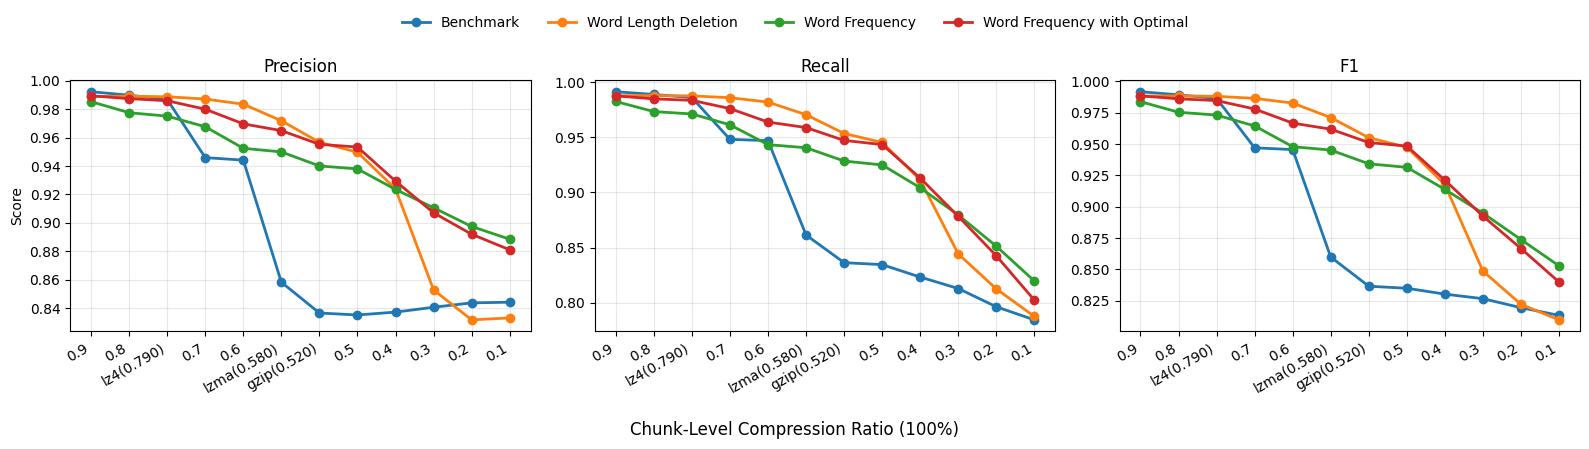

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_mean_only(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_chunk_mean",  "Precision"),
        ("R_chunk_mean",  "Recall"),
        ("F1_chunk_mean", "F1"),
    ]

    for ax, (mean_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values

            ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(LABELS, rotation=30, ha="right")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("Score")
    fig.supxlabel("Chunk-Level Compression Ratio (100%)")

    # legend 只画一次
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(dfs),
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),  # 👈 往上抬
)
    plt.tight_layout()
    plt.show()

plot_PRF_3in1_mean_only(dfs)

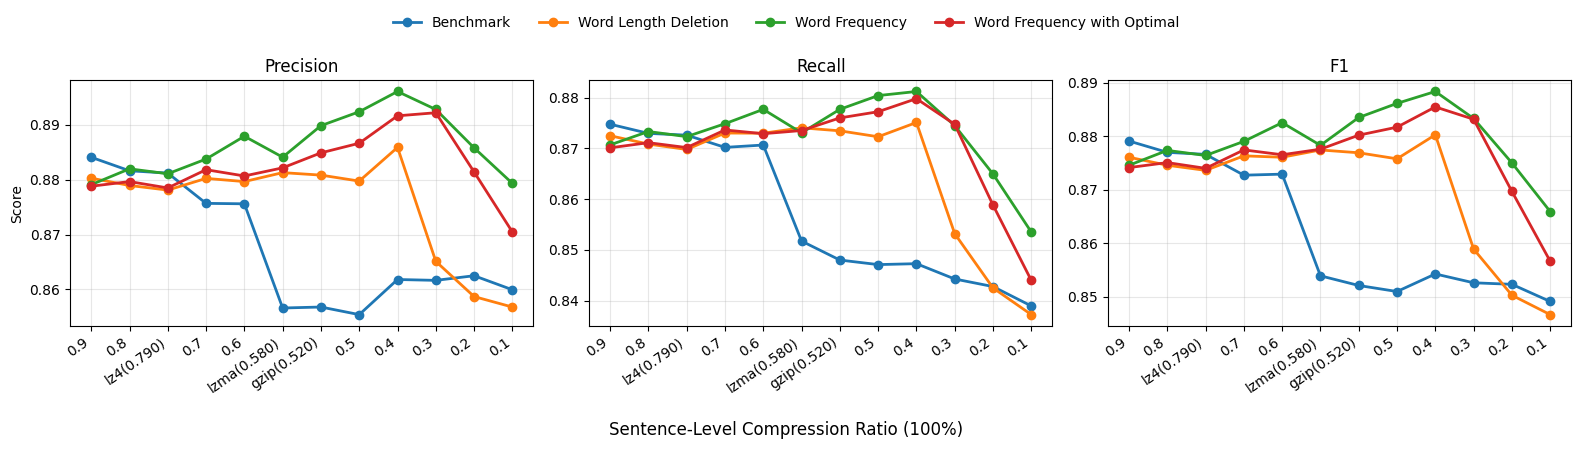

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_mean_only(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_sent_mean",  "Precision"),
        ("R_sent_mean",  "Recall"),
        ("F1_sent_mean", "F1"),
    ]

    for ax, (mean_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values

            ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(LABELS, rotation=35, ha="right")
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("Score")
    fig.supxlabel("Sentence-Level Compression Ratio (100%)")

    # legend 只画一次
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(dfs),
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),  # 👈 往上抬
)
    plt.tight_layout()
    plt.show()

plot_PRF_3in1_mean_only(dfs)

**Mean, Std**

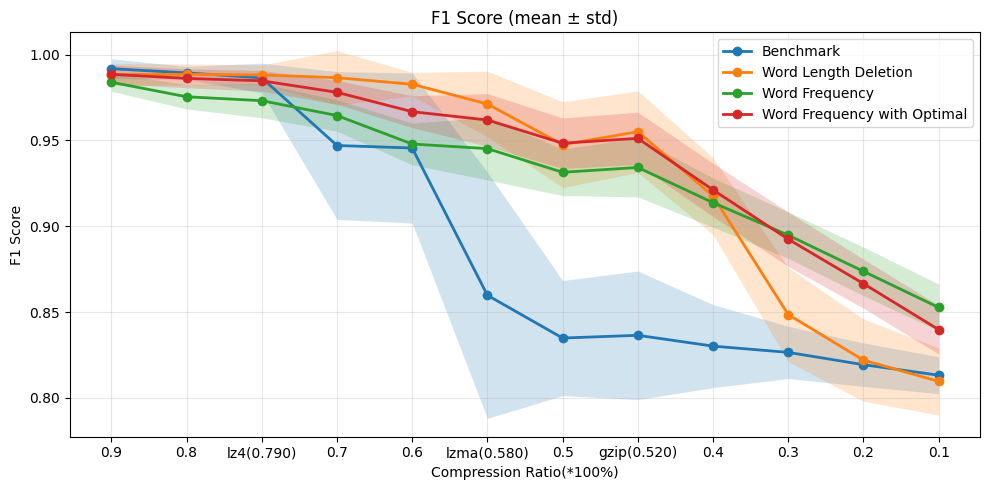

In [ ]:
plot_metric_with_std_band(
    dfs,
    mean_key="F1_chunk_mean",
    std_key="F1_chunk_std",
    title="F1 Score (mean ± std)",
    ylabel="F1 Score",
)



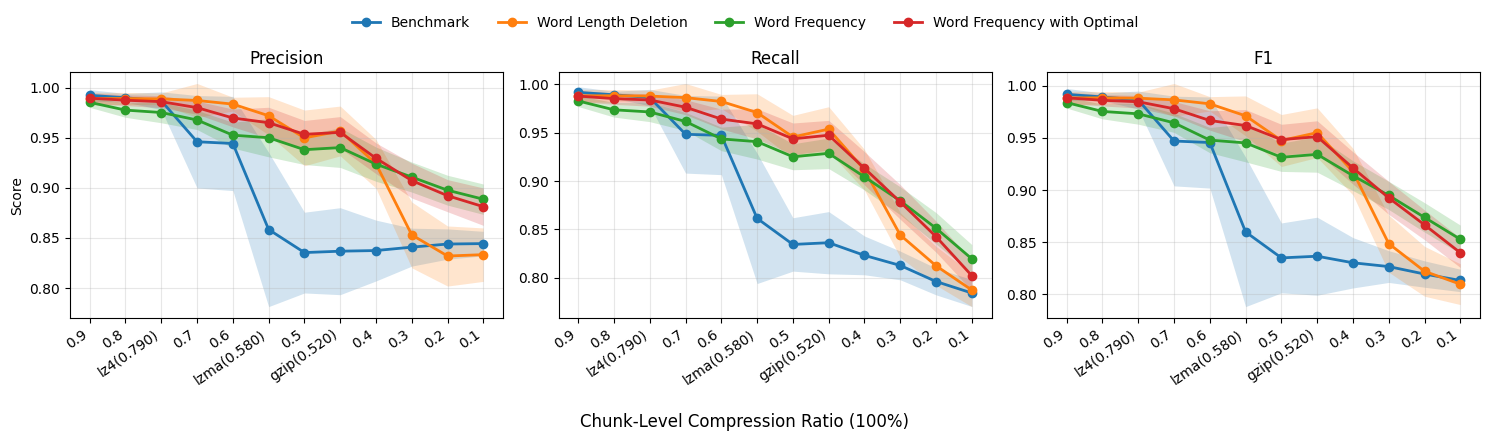

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_std_band(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_chunk_mean",  "P_chunk_std",  "Precision"),
        ("R_chunk_mean",  "R_chunk_std",  "Recall"),
        ("F1_chunk_mean", "F1_chunk_std", "F1"),
    ]

    for ax, (mean_key, std_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values
            std  = df.loc[std_key,  COLS].astype(float).values

            # mean 曲线
            line, = ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

            # std 阴影
            ax.fill_between(
                x,
                mean - std,
                mean + std,
                color=line.get_color(),
                alpha=0.2,
                linewidth=0,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        #ax.set_xticklabels(LABELS, rotation=0)
        ax.set_xticklabels(LABELS, rotation=35, ha="right")
        ax.grid(alpha=0.3)

    # 统一坐标轴标签
    axes[0].set_ylabel("Score")
    fig.supxlabel("Chunk-Level Compression Ratio (100%)")

    # legend 只放一次（右上角 or 下方）
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(dfs),
        frameon=False,
        bbox_to_anchor=(0.5, 1.08),
    )

    plt.tight_layout()
    plt.show()


plot_PRF_3in1_std_band(dfs)


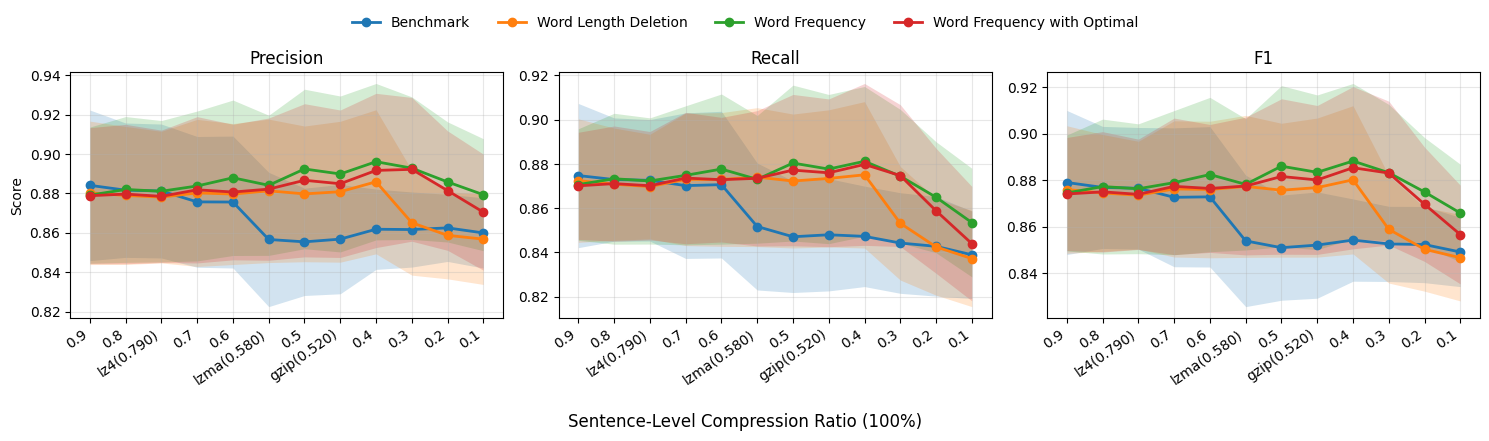

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_PRF_3in1_std_band(dfs):
    x = np.arange(len(LABELS))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4),
        sharex=True,
        sharey=False,
    )

    metrics = [
        ("P_sent_mean",  "P_sent_std",  "Precision"),
        ("R_sent_mean",  "R_sent_std",  "Recall"),
        ("F1_sent_mean", "F1_sent_std", "F1"),
    ]

    for ax, (mean_key, std_key, title) in zip(axes, metrics):
        for name, df in dfs.items():
            mean = df.loc[mean_key, COLS].astype(float).values
            std  = df.loc[std_key,  COLS].astype(float).values

            # mean 曲线
            line, = ax.plot(
                x,
                mean,
                marker="o",
                linewidth=2,
                label=name,
            )

            # std 阴影
            ax.fill_between(
                x,
                mean - std,
                mean + std,
                color=line.get_color(),
                alpha=0.2,
                linewidth=0,
            )

        ax.set_title(title)
        ax.set_xticks(x)
        #ax.set_xticklabels(LABELS, rotation=0)
        ax.set_xticklabels(LABELS, rotation=35, ha="right")
        ax.grid(alpha=0.3)

    # 统一坐标轴标签
    axes[0].set_ylabel("Score")
    fig.supxlabel("Sentence-Level Compression Ratio (100%)")

    # legend 只放一次（右上角 or 下方）
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(dfs),
        frameon=False,
        bbox_to_anchor=(0.5, 1.08),
    )

    plt.tight_layout()
    plt.show()


plot_PRF_3in1_std_band(dfs)
